In [1]:
import os
from datetime import datetime
import pickle
import random
import math
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.colors as mcolors
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler, MaxAbsScaler, MinMaxScaler

import torch
import torch.nn as nn
import torch.nn.functional as F

os.makedirs("models", exist_ok=True)

def set_all_seeds(seed):
    np.random.seed(seed)
    random.seed(seed)
    torch.manual_seed(seed)

seed = 0
set_all_seeds(seed)

In [2]:
df = pd.read_csv(f"BTCUSDT-15m-data.csv")
print(df)

                  timestamp      open_time      open      high       low  \
0       2017-08-17 04:00:00  1502942400000   4261.48   4280.56   4261.48   
1       2017-08-17 04:15:00  1502943300000   4261.48   4270.41   4261.32   
2       2017-08-17 04:30:00  1502944200000   4280.00   4310.07   4267.99   
3       2017-08-17 04:45:00  1502945100000   4310.07   4313.62   4291.37   
4       2017-08-17 05:00:00  1502946000000   4308.83   4328.69   4304.31   
...                     ...            ...       ...       ...       ...   
315235  2026-08-19 18:00:00  1787162400000  68187.39  68236.82  68042.42   
315236  2026-08-19 18:15:00  1787163300000  68238.57  68322.74  68221.64   
315237  2026-08-19 18:30:00  1787164200000  68272.37  68424.05  68236.25   
315238  2026-08-19 18:45:00  1787165100000  68423.58  68444.43  68336.57   
315239  2026-08-19 19:00:00  1787166000000  68397.33  68452.53  68108.45   

           close     volume     close_time      quote_av  trades  tb_base_av  \
0      

**Check missing values**

In [3]:
print(df.isnull())
print(f"Counts how many missing values there are in each column: {df.isnull().sum()}")
print(f"Total missing values: {df.isnull().sum().sum()}")

        timestamp  open_time   open   high    low  close  volume  close_time  \
0           False      False  False  False  False  False   False       False   
1           False      False  False  False  False  False   False       False   
2           False      False  False  False  False  False   False       False   
3           False      False  False  False  False  False   False       False   
4           False      False  False  False  False  False   False       False   
...           ...        ...    ...    ...    ...    ...     ...         ...   
315235      False      False  False  False  False  False   False       False   
315236      False      False  False  False  False  False   False       False   
315237      False      False  False  False  False  False   False       False   
315238      False      False  False  False  False  False   False       False   
315239      False      False  False  False  False  False   False       False   

        quote_av  trades  tb_base_av  t

**Split data**

In [4]:
train_end_idx = 252_000
val_end_idx = 283_500

# 3-way split, chronological, no shuffling across the boundaries:
#   df_train -> fit the model
#   df_val   -> checked every epoch to decide when to stop / which checkpoint
#               to keep (this replaces the old df_test in that role)
#   df_test  -> touched exactly once, in the final cell, after training is
#               completely finished. No epoch/checkpoint decision may look at
#               df_test's performance.
df_train = df.iloc[:train_end_idx].copy()
df_val = df.iloc[train_end_idx:val_end_idx].copy()
df_test = df.iloc[val_end_idx:].copy()

df_val.reset_index(drop=True, inplace=True)
df_test.reset_index(drop=True, inplace=True)

print(f"Length of df_train: {len(df_train)}")
print(f"Length of df_val:   {len(df_val)}")
print(f"Length of df_test:  {len(df_test)}")

Length of df_train: 252000
Length of df_val:   31500
Length of df_test:  31740


**Building Meaningful Features**

In [5]:
def build_features(opens, highs, lows, closes, volumes, train_scalers=None):

    # Build features
    feature1 = (closes - opens) / opens
    feature2 = (highs - opens) / opens
    feature3 = (highs - closes) / closes
    feature4 = (lows - opens) / opens
    feature5 = (lows - closes) / closes
    feature6 = (highs - lows) / opens
    feature7 = (highs - lows) / closes
    feature8 = volumes

    # Stack features
    features = [
        feature1,
        feature2,
        feature3,
        feature4,
        feature5,
        feature6,
        feature7,
        feature8,
    ]
    num_features = len(features)
    scaled_fts = []

    if train_scalers is None:
        train_scalers = [MaxAbsScaler() for _ in range(num_features)]
        is_train = True
    else:
        is_train = False

    for i in range(num_features):
        # Get train scaler
        scaler = train_scalers[i]
        if is_train:
            # Scaler -> Fit -> Train dataset
            scaled_ft = scaler.fit_transform(features[i].reshape(-1, 1))
            # Save the train scaler in a list
        elif not is_train:
            # Scaler -> NOT Fit -> Test dataset
            scaled_ft = scaler.transform(features[i].reshape(-1, 1))

        # Update list of SCALED features
        scaled_fts.append(scaled_ft.flatten())

    # Stack features
    scaled_features = np.stack(scaled_fts, axis=-1)

    # Get num. features
    num_features = scaled_features.shape[-1]
    return scaled_features, num_features, train_scalers

**Example of how the scaler works**

In [6]:
import numpy as np
from sklearn.preprocessing import MaxAbsScaler

# Suppose we have a simple 1D array (e.g. daily returns)
X = np.array([ -2, -1, 0, 1, 2 ])

print("Original data:", X)

# Step 1: reshape into 2D (because sklearn expects shape (n_samples, n_features))
X_2d = X.reshape(-1, 1)

# Step 2: create the scaler and fit_transform
scaler = MaxAbsScaler()
X_scaled = scaler.fit_transform(X_2d)

# Step 3: flatten back to 1D for convenience
X_scaled = X_scaled.flatten()

print("Scaled data:", X_scaled)


Original data: [-2 -1  0  1  2]
Scaled data: [-1.  -0.5  0.   0.5  1. ]


**Preprocess data**

In [7]:
def preprocess_data(seq_len, df, train_scalers=None):
    m = len(df)

    opens = np.array(df['open'].values)
    highs = np.array(df['high'].values)
    lows = np.array(df['low'].values)
    closes = np.array(df['close'].values)
    volumes = np.array(df['volume'].values)

    # Build features
    features, num_features, train_scalers = build_features(opens, highs, lows, closes, volumes, train_scalers)

    # Calculate number of samples
    num_samples = m - seq_len

    # Create storage for inputs & targets
    X = np.zeros([num_samples, seq_len, num_features], dtype=np.float32)
    Y = np.zeros([num_samples, num_features], dtype=np.float32)

    # Create samples (X, Y)
    for i in range(num_samples):
        X[i] = features[i : i+seq_len]
        Y[i] = features[i+seq_len : i+seq_len+1]

    # Fix alignment
    opens = np.array(opens[seq_len:])
    closes = np.array(closes[seq_len:])

    return X, Y, num_features, opens, closes, train_scalers

In [8]:
# Sequence Length
seq_len = 96

# Preprocess data. df_val is what the training loop is allowed to check every
# epoch; df_test is preprocessed here but not looked at again until the final
# one-time evaluation cell at the end of this notebook.
X_train, Y_train, num_features, _, _, train_scalers = preprocess_data(seq_len, df_train)
X_val, Y_val, num_features, backtest_opens_val, backtest_closes_val, _ = preprocess_data(seq_len, df_val, train_scalers)
X_test, Y_test, num_features, backtest_opens_test, backtest_closes_test, _ = preprocess_data(seq_len, df_test, train_scalers)

In [9]:
m_train = X_train.shape[0]
m_val = X_val.shape[0]
m_test = X_test.shape[0]
print(f"m_train: {m_train}")
print(f"m_val: {m_val}")
print(f"m_test: {m_test}")
print(f"X_train shape: {X_train.shape}")
print(f"Y_train shape: {Y_train.shape}")
print(f"X_val shape: {X_val.shape}")
print(f"Y_val shape: {Y_val.shape}")
print(f"X_test shape: {X_test.shape}")
print(f"Y_test shape: {Y_test.shape}")

m_train: 251904
m_val: 31404
m_test: 31644
X_train shape: (251904, 96, 8)
Y_train shape: (251904, 8)
X_val shape: (31404, 96, 8)
Y_val shape: (31404, 8)
X_test shape: (31644, 96, 8)
Y_test shape: (31644, 8)


**Transform data to Torch Tensor**

In [10]:
device = torch.device("cuda:0" if torch.cuda.is_available() else 'cpu')
print("my deive: ", device)

X_train = torch.from_numpy(X_train.astype(np.float32)).to(device, dtype=torch.float32)
Y_train = torch.from_numpy(Y_train.astype(np.float32)).to(device, dtype=torch.float32)

X_val = torch.from_numpy(X_val.astype(np.float32)).to(device, dtype=torch.float32)
Y_val = torch.from_numpy(Y_val.astype(np.float32)).to(device, dtype=torch.float32)

# X_test/Y_test are kept on CPU and are not touched anywhere in the training
# loop below -- only in the final one-time evaluation cell at the end.
X_test = torch.from_numpy(X_test.astype(np.float32))
Y_test = torch.from_numpy(Y_test.astype(np.float32))

Y_pred_val = torch.zeros([m_val, num_features], device=device, dtype=torch.float32)

my deive:  cpu


**Build model**

In [11]:
class Model(nn.Module):
    def __init__(self):
        super().__init__()

        # LSTM
        self.lstm = nn.LSTM(input_size=num_features,
                            hidden_size=64,
                            num_layers=1,
                            batch_first=True)

        # Output layer
        self.fc_out = nn.Linear(64, num_features)

    def forward(self, x):
        # LSTM
        x, (h_n, c_n) = self.lstm(x)
        x = x[:, -1, :] 

        # Output layer
        x = self.fc_out(x)
        return x



**Initialization**

In [12]:
# Initialize model
model = Model()

# Transfer model to device
model.to(device)

# Initialize criterion
criterion = nn.MSELoss()

# Choose learning rate
lr = 1e-4

# Create optimizer
optimizer = torch.optim.Adam(model.parameters(), lr=lr)

# Choose batch size
batch_size = 32

# Lists of train/validation losses
train_losses = []
val_losses = []

val_equity_epochs = []
val_accuracy_epochs = []

# Tracks the single best checkpoint seen so far, by validation equity --
# this is the file the final held-out test cell evaluates.
best_val_equity = -float("inf")

# Set epoch
num_epochs = 200

In [13]:
def create_minibatches(X, Y, batch_size, seed, shuffle=True):

    mini_batches = []
    m = len(X)
    if shuffle:
        permutation = list(np.random.permutation(m))
        X = X[permutation]
        Y = Y[permutation]
    num_batches = m // batch_size
    for k in range(num_batches):
        mb_X = X[k * batch_size : k * batch_size + batch_size]
        mb_Y = Y[k * batch_size : k * batch_size + batch_size]
        mb_pair = (mb_X, mb_Y)
        mini_batches.append(mb_pair)

    seed += 1
    set_all_seeds(seed)

    return mini_batches, seed

**Load model (if available)**

In [14]:
def load_training_data(model, optimizer):
    checkpoint = torch.load('training_process', weights_only=False)
    epoch = checkpoint['epoch']
    train_losses = checkpoint['train_losses']
    val_losses = checkpoint['val_losses']
    val_equity_epochs = checkpoint['val_equity_epochs']
    val_accuracy_epochs = checkpoint['val_accuracy_epochs']
    best_val_equity = checkpoint['best_val_equity']
    seed = checkpoint['seed']

    # Load model's weights & optimizer's state
    model.load_state_dict(checkpoint['model_state_dict'])
    optimizer.load_state_dict(checkpoint['optimizer_state_dict'])
    return model, optimizer, epoch, train_losses, val_losses, val_equity_epochs, val_accuracy_epochs, best_val_equity, seed


if os.path.exists("training_process"):
    model, optimizer, epoch, train_losses, val_losses, val_equity_epochs, val_accuracy_epochs, best_val_equity, seed = load_training_data(model, optimizer)
    print(f"Loaded model!")
else:
    print(f"No training process to load.")
    epoch = 0

No training process to load.


**Train model**

Epoch: 0, Val Equity: 1656.14, Val Accuracy: 50.43 train_losses: 0.00035169207707231475, val_losses: 9.257633064407855e-05, Duration: 0:01:43.699924


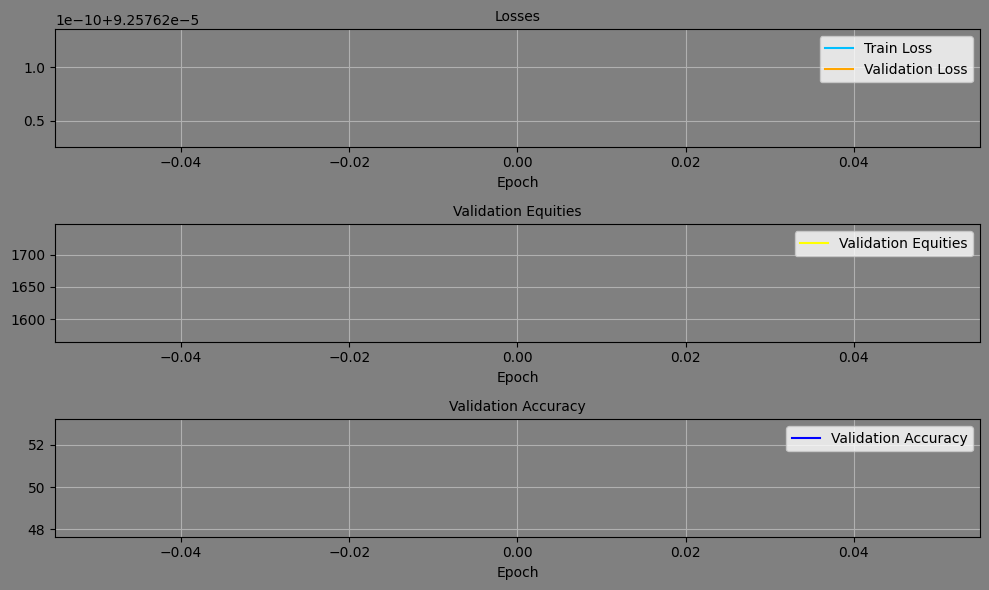

Epoch: 1, Val Equity: 782.95, Val Accuracy: 50.10 train_losses: 0.00028862644558287913, val_losses: 9.10176822799258e-05, Duration: 0:01:44.373891


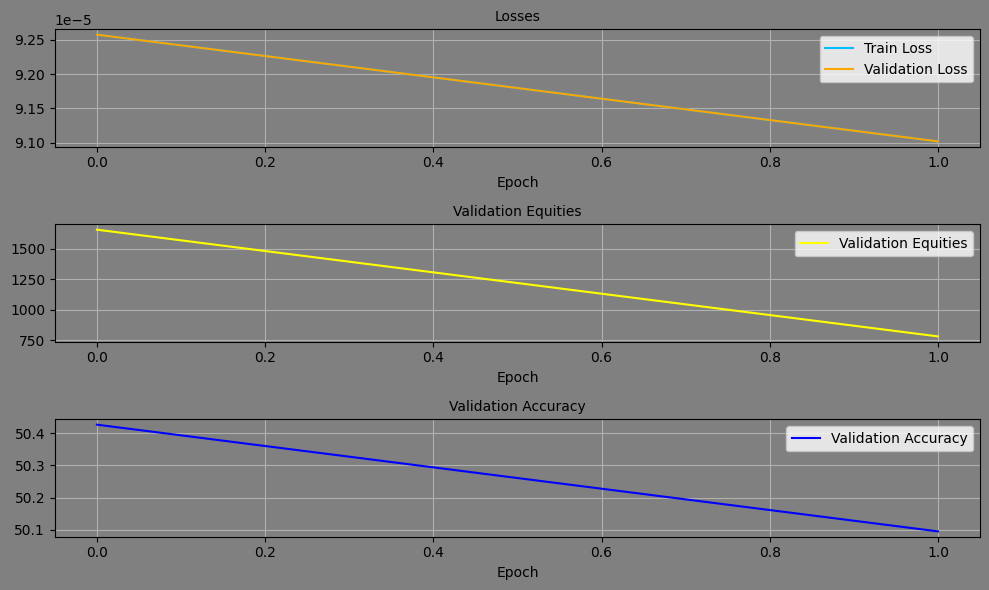

Epoch: 2, Val Equity: 864.96, Val Accuracy: 50.09 train_losses: 0.00028542087004534256, val_losses: 9.092834079638124e-05, Duration: 0:01:43.964575


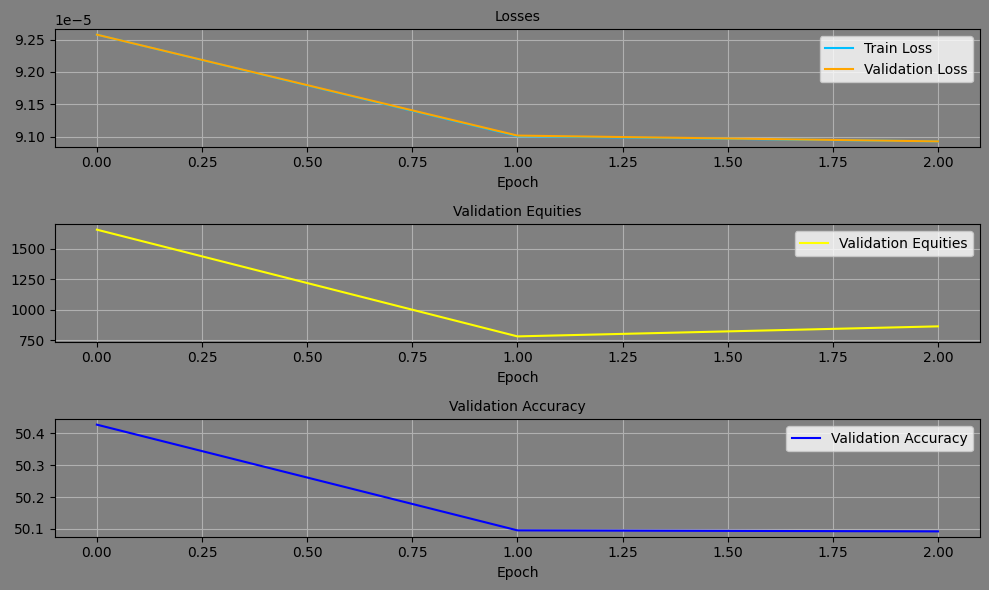

Epoch: 3, Val Equity: 1287.21, Val Accuracy: 49.00 train_losses: 0.0002839430206206747, val_losses: 9.100884199142456e-05, Duration: 0:01:44.447590


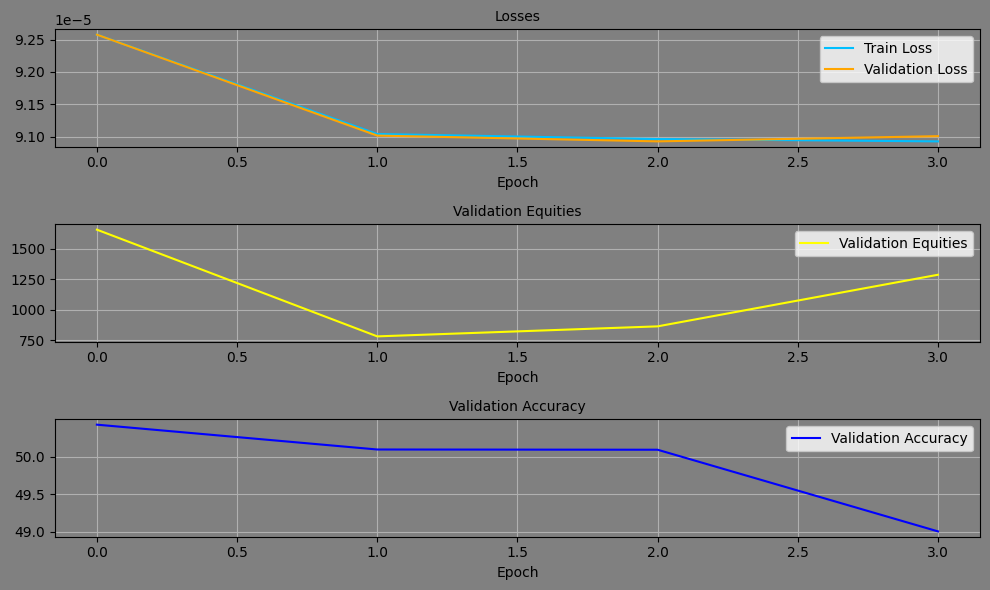

Epoch: 4, Val Equity: 829.55, Val Accuracy: 50.09 train_losses: 0.00028305853564047277, val_losses: 8.965913002612069e-05, Duration: 0:01:43.255311


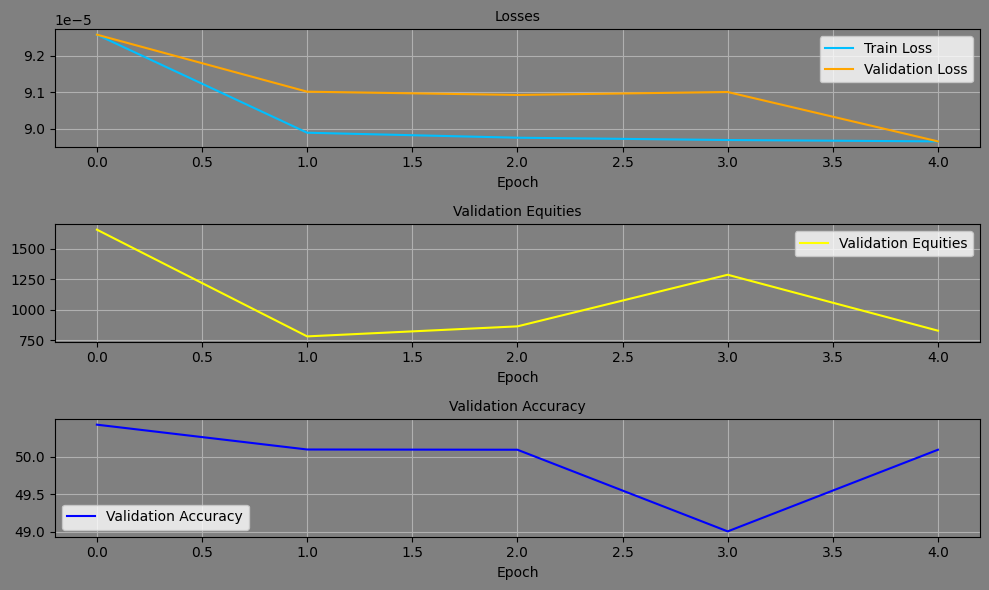

Epoch: 5, Val Equity: 1344.15, Val Accuracy: 48.94 train_losses: 0.0002824486966020468, val_losses: 9.031898662215099e-05, Duration: 0:01:44.209687


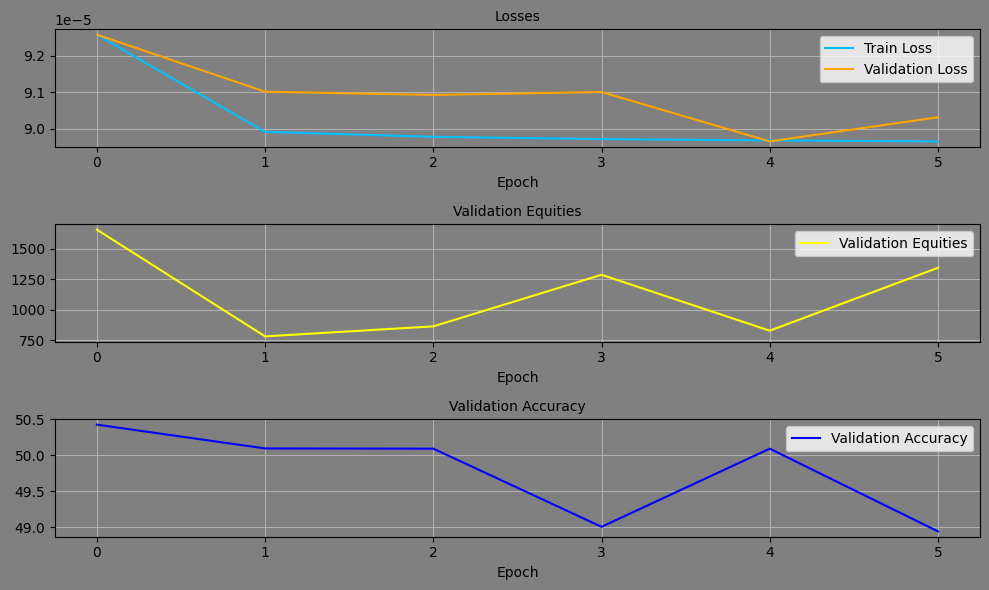

Epoch: 6, Val Equity: 1550.60, Val Accuracy: 49.07 train_losses: 0.00028226683107453106, val_losses: 8.936413360061124e-05, Duration: 0:01:44.480640


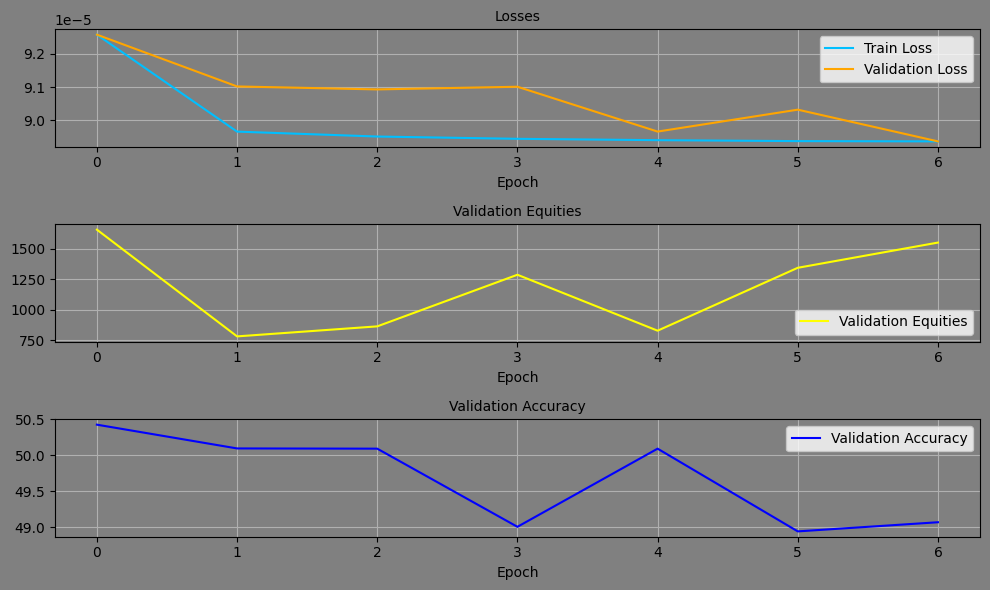

Epoch: 7, Val Equity: 1378.96, Val Accuracy: 50.61 train_losses: 0.0002818555616021128, val_losses: 8.911760960472748e-05, Duration: 0:01:44.440979


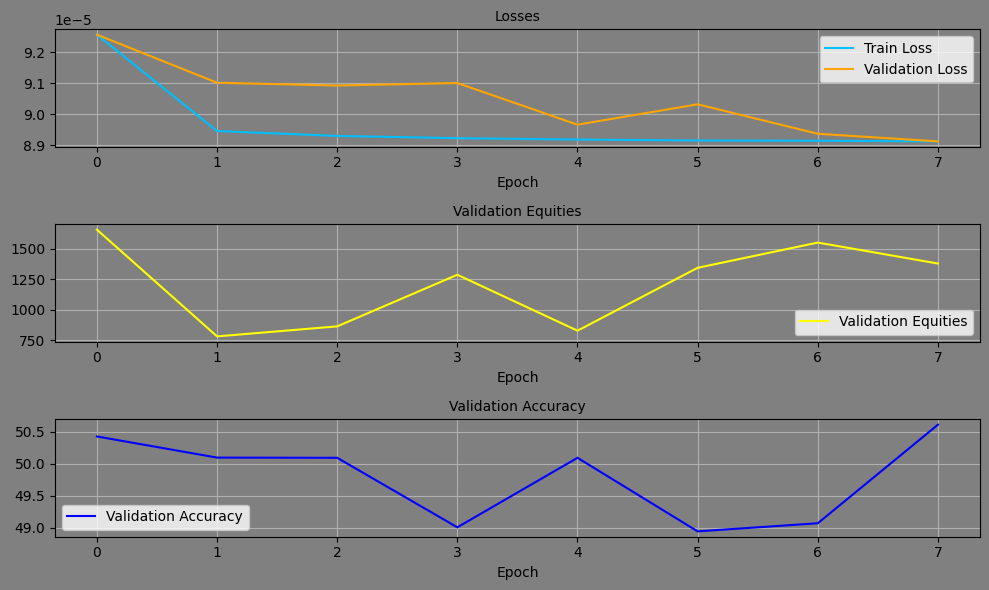

Epoch: 8, Val Equity: 1237.14, Val Accuracy: 50.45 train_losses: 0.00028157537695868427, val_losses: 8.969368354883045e-05, Duration: 0:01:44.866073


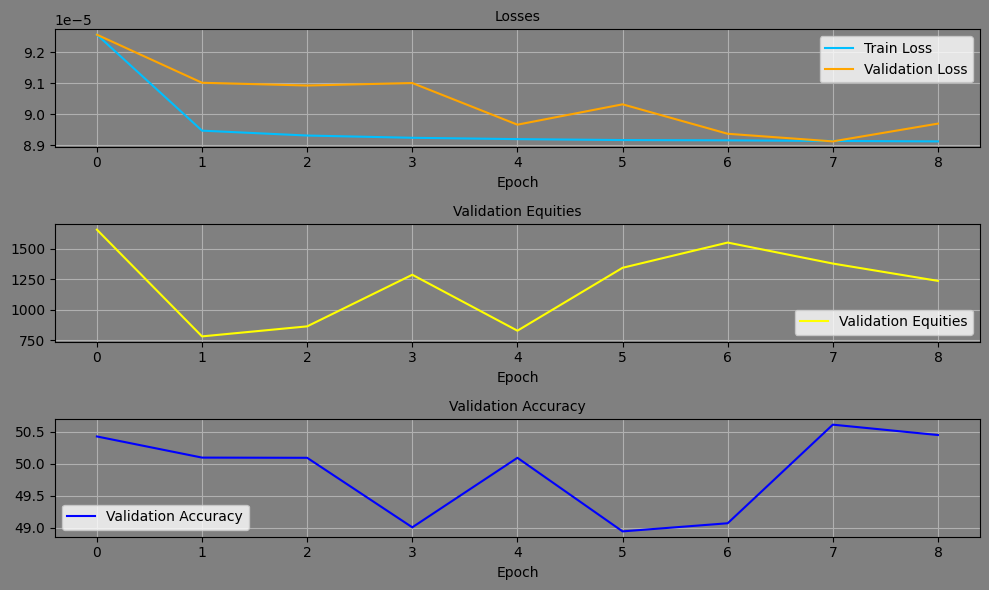

Epoch: 9, Val Equity: 868.71, Val Accuracy: 50.07 train_losses: 0.00028136405160100877, val_losses: 8.93443648237735e-05, Duration: 0:01:46.672207


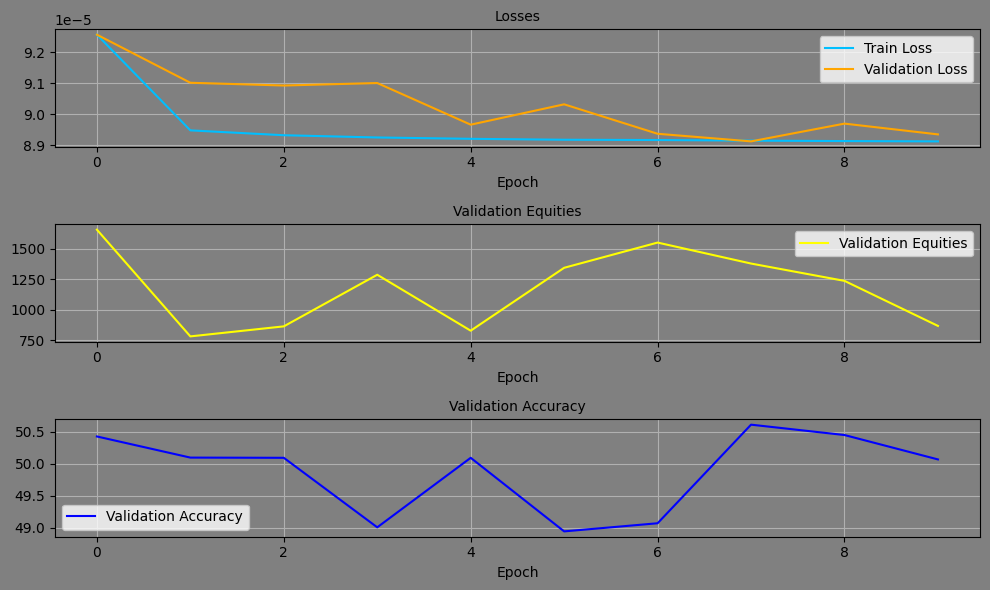

Epoch: 10, Val Equity: 1271.50, Val Accuracy: 49.06 train_losses: 0.0002812221996981958, val_losses: 8.917337254388258e-05, Duration: 0:01:45.482807


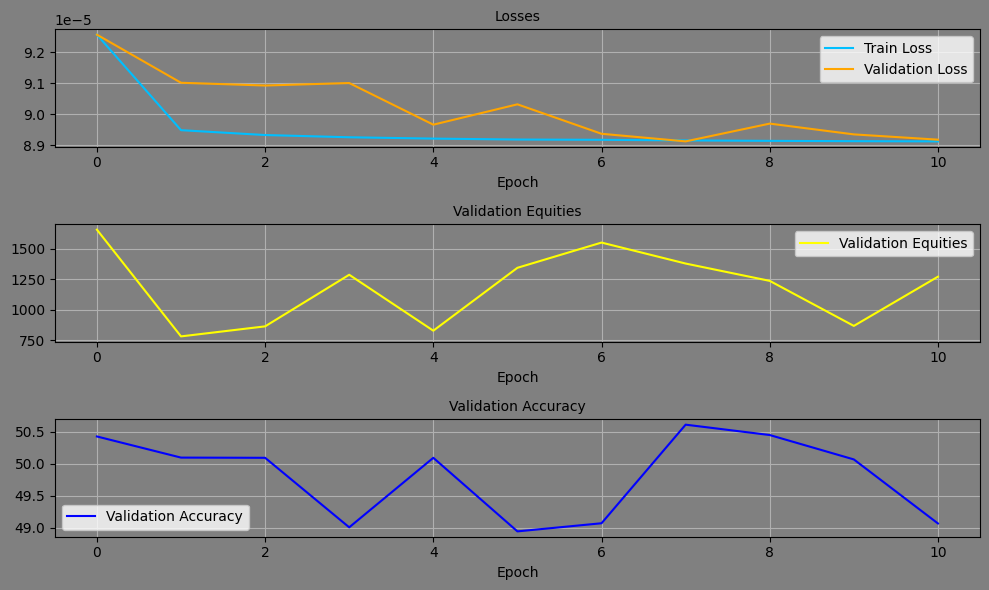

Epoch: 11, Val Equity: 1377.13, Val Accuracy: 48.88 train_losses: 0.0002810282629697235, val_losses: 8.982419967651367e-05, Duration: 0:01:44.781131


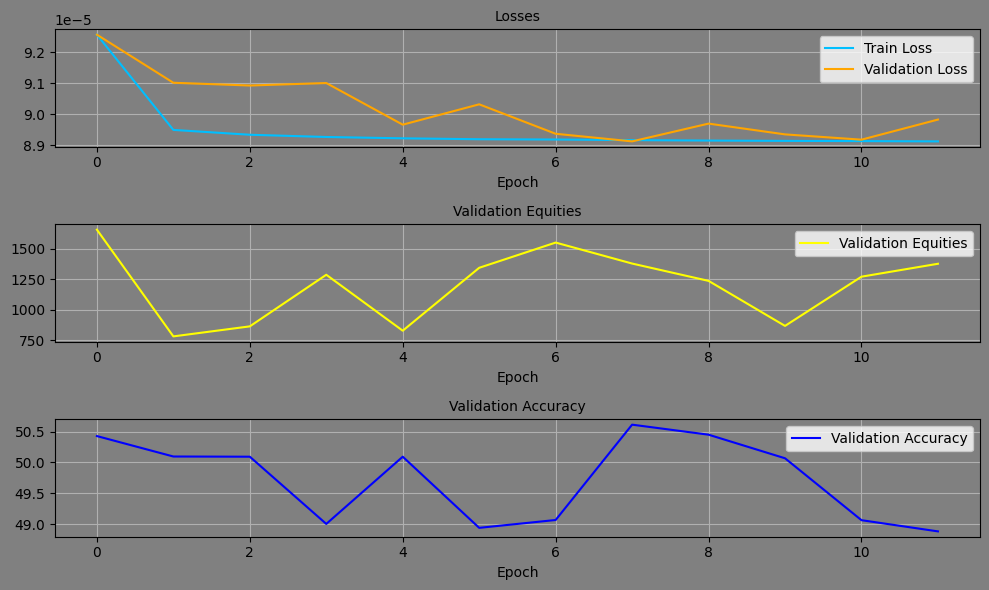

Epoch: 12, Val Equity: 672.33, Val Accuracy: 50.07 train_losses: 0.0002808609040823462, val_losses: 8.973735384643078e-05, Duration: 0:01:44.946174


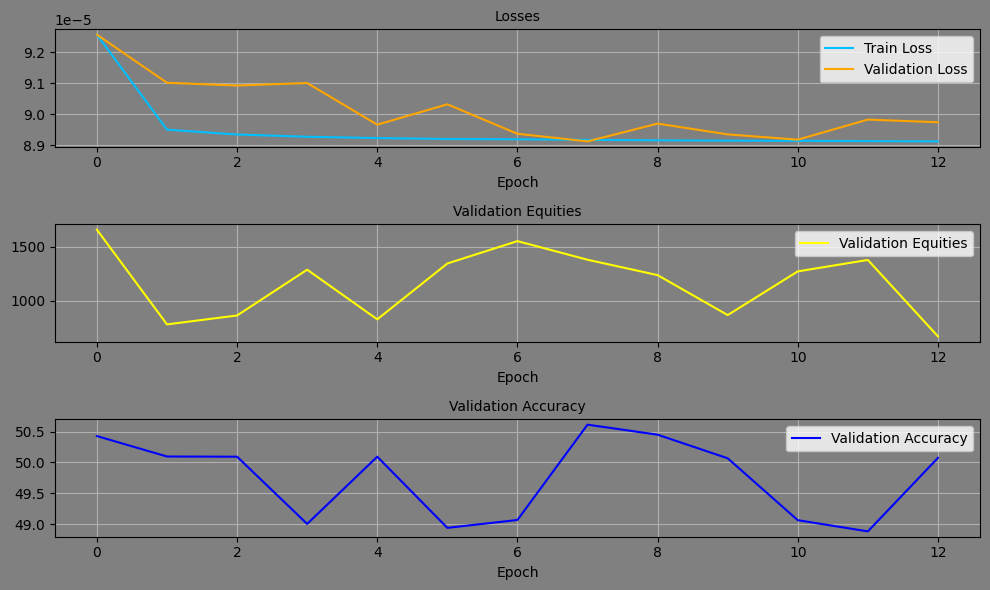

Epoch: 13, Val Equity: 1272.03, Val Accuracy: 49.45 train_losses: 0.00028071804131961353, val_losses: 9.318759111920372e-05, Duration: 0:01:48.006769


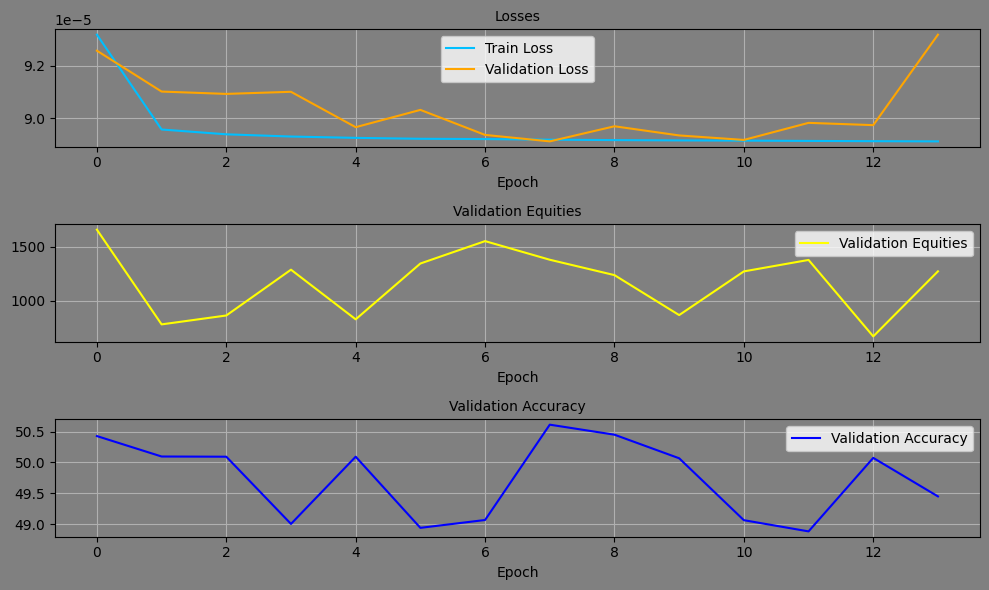

Epoch: 14, Val Equity: 1002.74, Val Accuracy: 49.42 train_losses: 0.0002807407018940097, val_losses: 8.956681995186955e-05, Duration: 0:01:45.716573


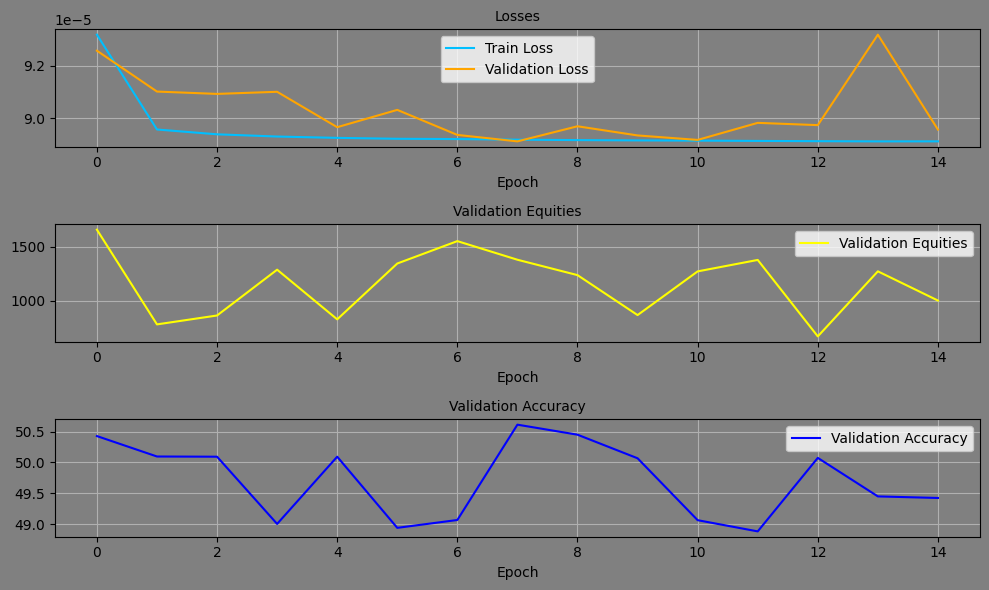

Epoch: 15, Val Equity: 773.33, Val Accuracy: 50.06 train_losses: 0.0002804788110229606, val_losses: 8.94840995897539e-05, Duration: 0:01:46.371387


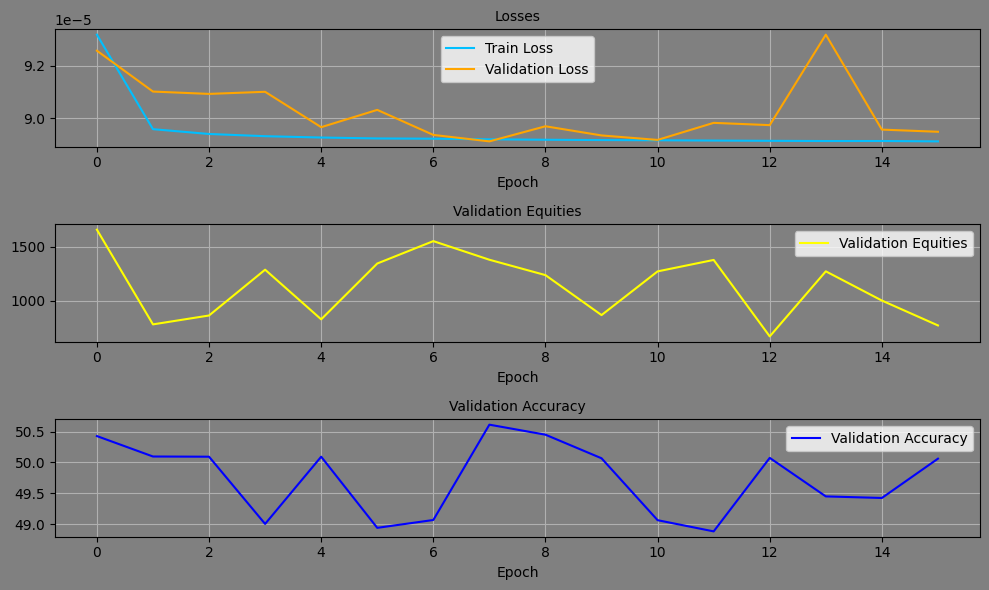

Epoch: 16, Val Equity: 1611.25, Val Accuracy: 49.00 train_losses: 0.0002803128269662248, val_losses: 9.196328755933791e-05, Duration: 0:01:45.643473


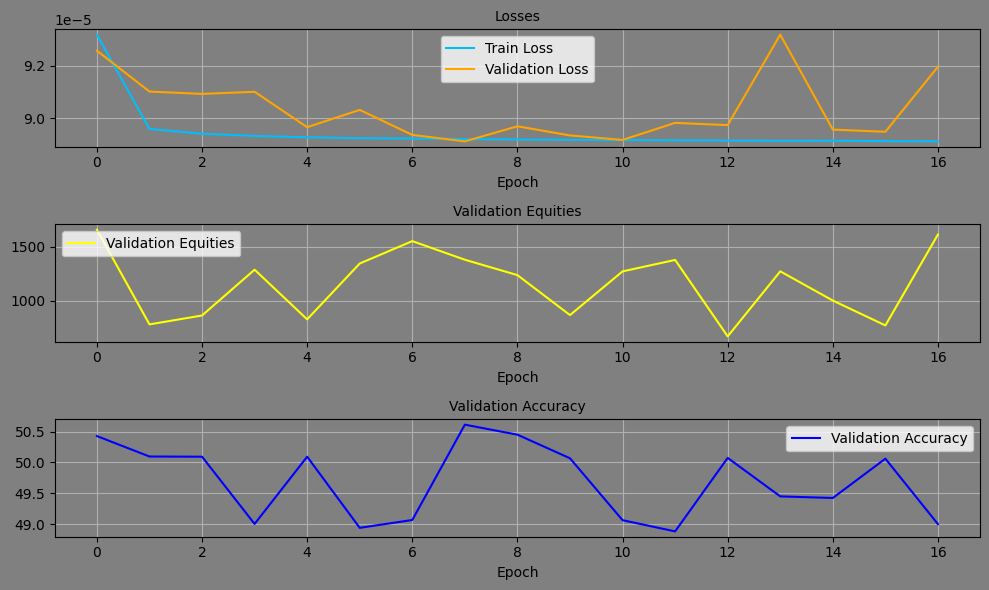

Epoch: 17, Val Equity: 1240.95, Val Accuracy: 50.21 train_losses: 0.00028018786446736845, val_losses: 9.002271690405905e-05, Duration: 0:01:45.856506


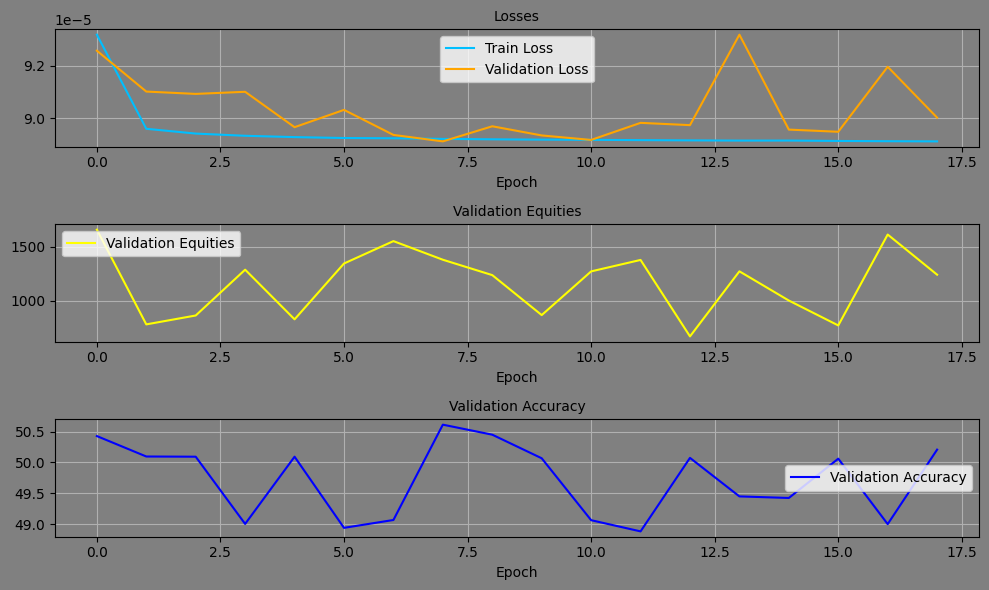

Epoch: 18, Val Equity: 1465.27, Val Accuracy: 49.47 train_losses: 0.00028004556746579726, val_losses: 9.094825509237126e-05, Duration: 0:01:44.698650


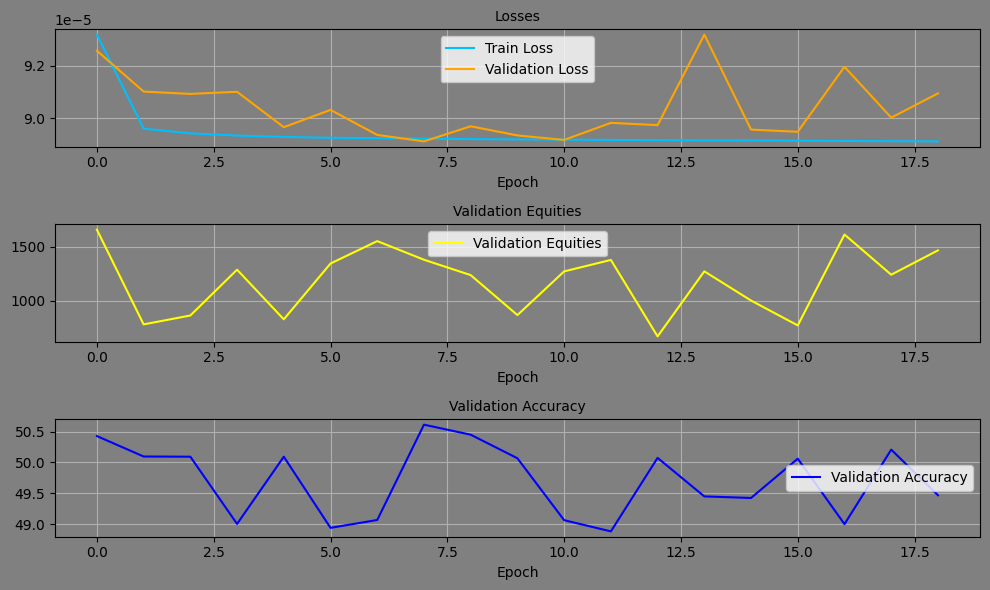

Epoch: 19, Val Equity: 2411.01, Val Accuracy: 49.22 train_losses: 0.00027982360231133466, val_losses: 8.955503290053457e-05, Duration: 0:01:44.317384


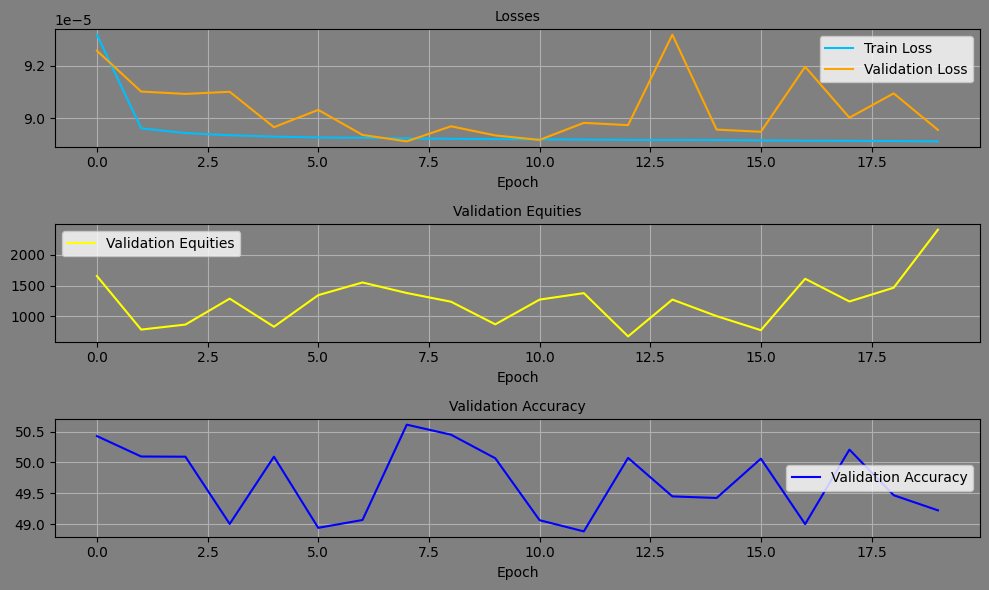

Epoch: 20, Val Equity: 1155.03, Val Accuracy: 48.72 train_losses: 0.00027969920829611615, val_losses: 8.941702981246635e-05, Duration: 0:01:43.884781


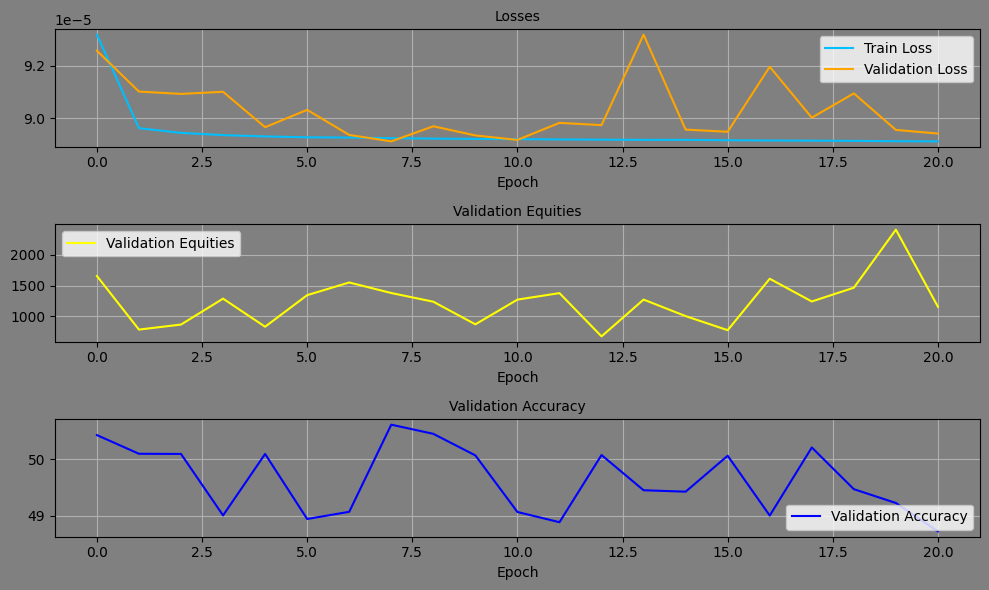

Epoch: 21, Val Equity: 1821.22, Val Accuracy: 49.32 train_losses: 0.00027943431679362004, val_losses: 9.069097723113373e-05, Duration: 0:01:46.874048


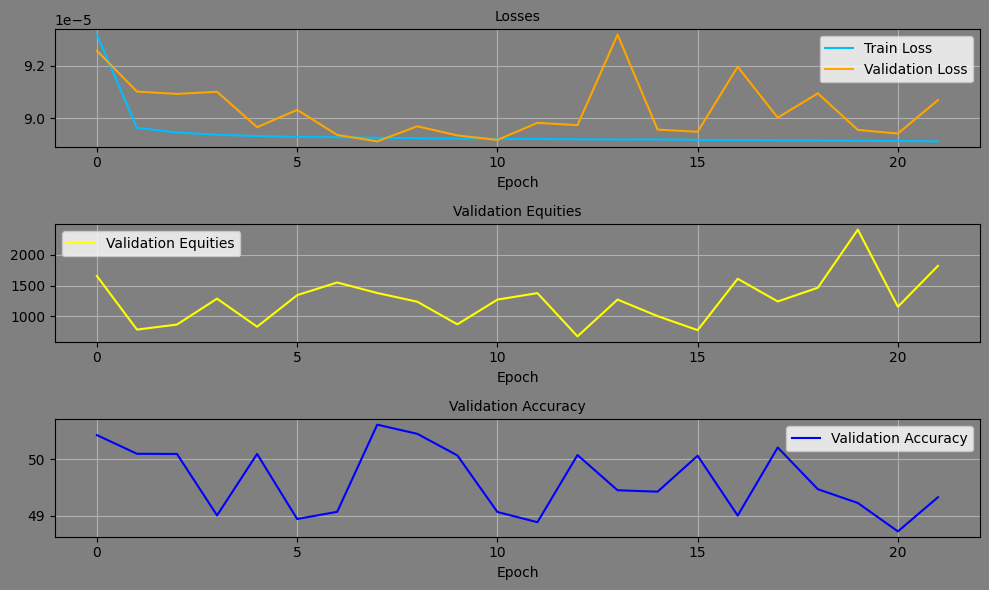

Epoch: 22, Val Equity: 1301.51, Val Accuracy: 48.98 train_losses: 0.0002793663478528066, val_losses: 8.910666656447574e-05, Duration: 0:01:49.886169


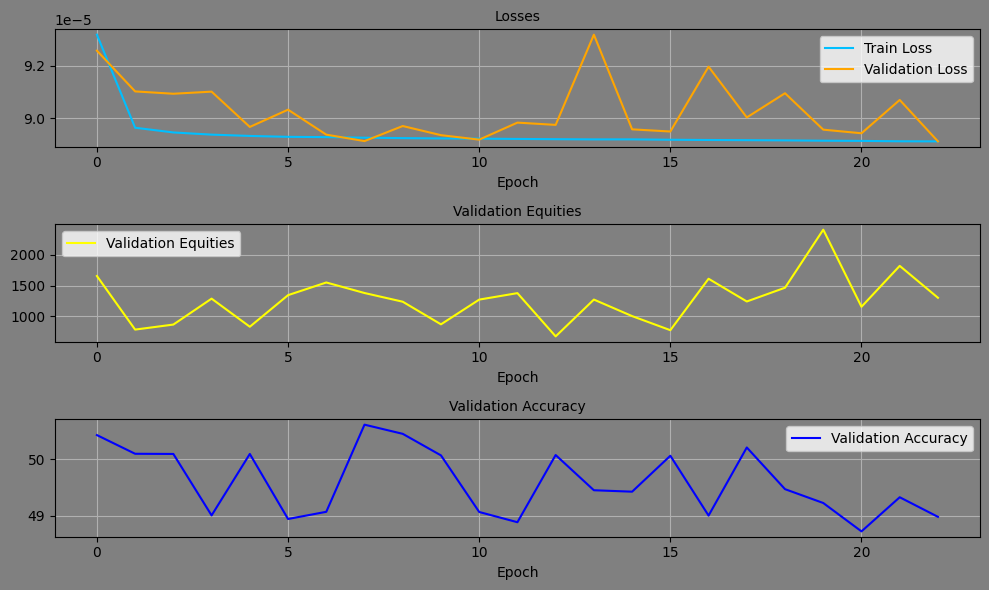

Epoch: 23, Val Equity: 2064.63, Val Accuracy: 49.61 train_losses: 0.00027896748031622795, val_losses: 8.944774162955582e-05, Duration: 0:01:46.342415


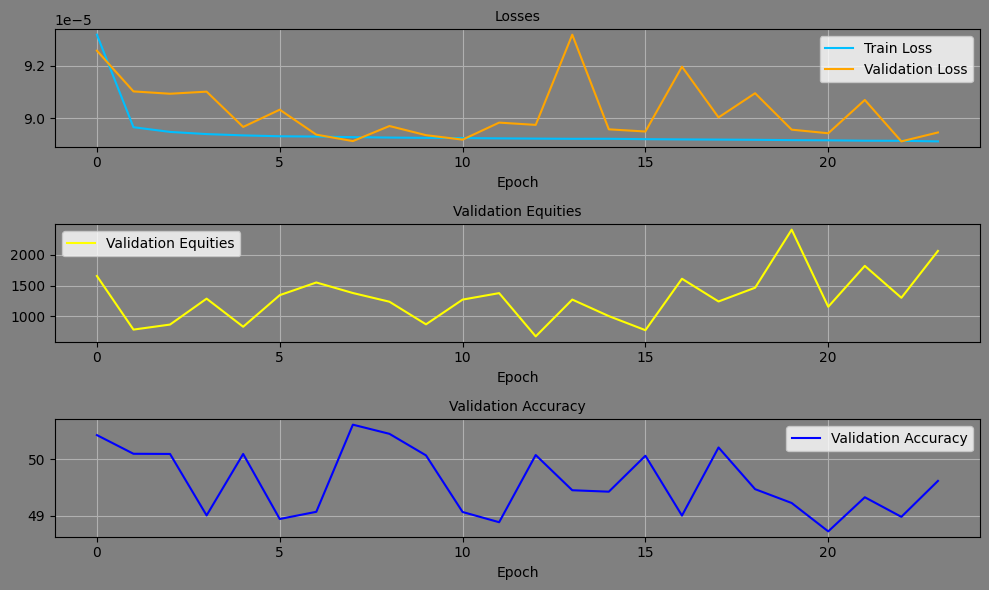

Epoch: 24, Val Equity: 836.41, Val Accuracy: 48.53 train_losses: 0.0002786186235987667, val_losses: 8.916837396100163e-05, Duration: 0:01:46.242221


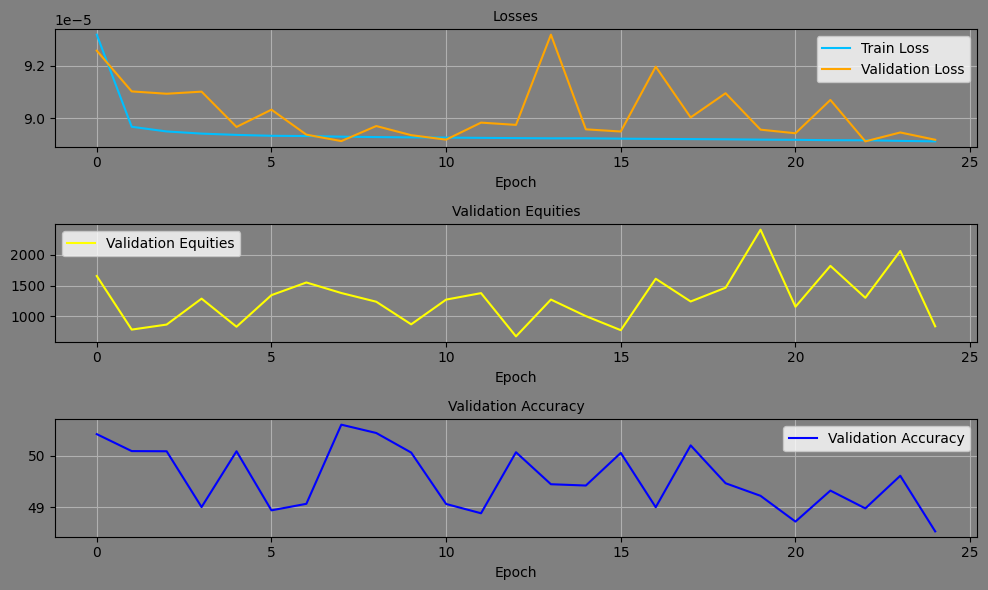

Epoch: 25, Val Equity: 1486.84, Val Accuracy: 48.94 train_losses: 0.0002782920026001326, val_losses: 8.93455944606103e-05, Duration: 0:01:45.102823


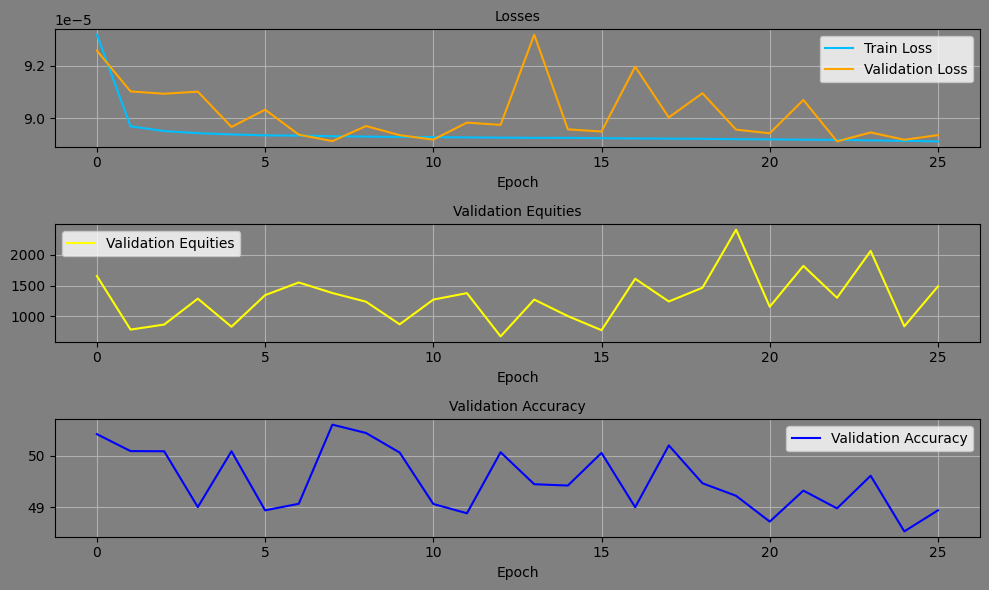

Epoch: 26, Val Equity: 1681.29, Val Accuracy: 49.00 train_losses: 0.0002780575335202592, val_losses: 8.954209624789655e-05, Duration: 0:01:46.278594


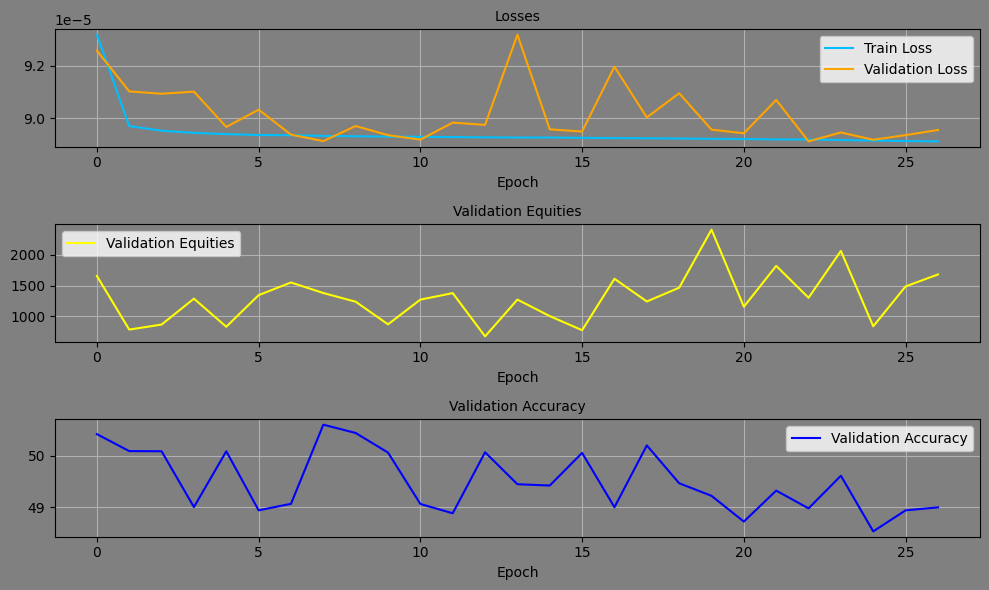

Epoch: 27, Val Equity: 1870.50, Val Accuracy: 49.16 train_losses: 0.00027774986820604014, val_losses: 9.354292706120759e-05, Duration: 0:01:47.276137


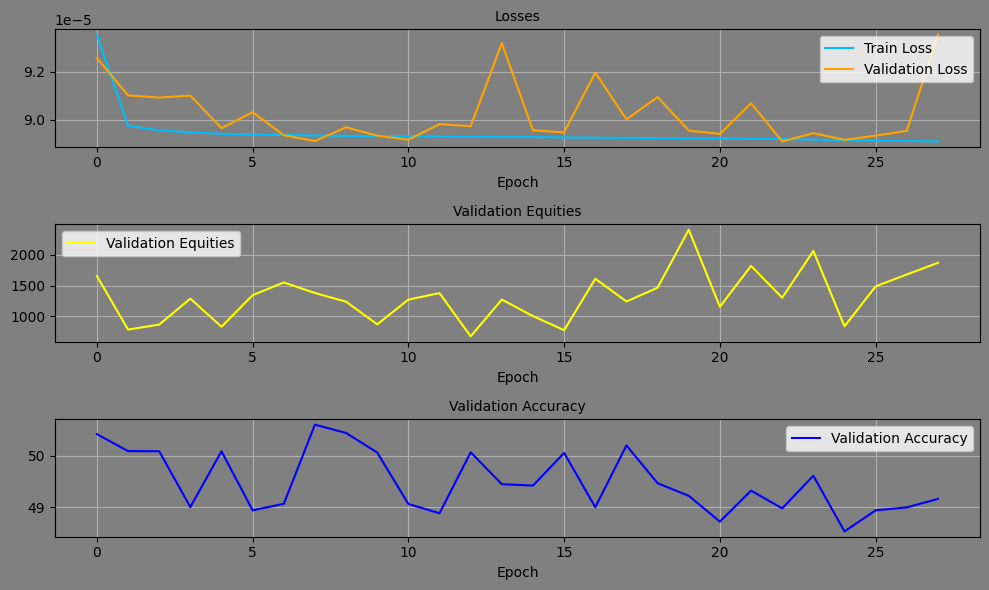

Epoch: 28, Val Equity: 1226.44, Val Accuracy: 50.20 train_losses: 0.00027732341351061334, val_losses: 9.166168456431478e-05, Duration: 0:01:46.096409


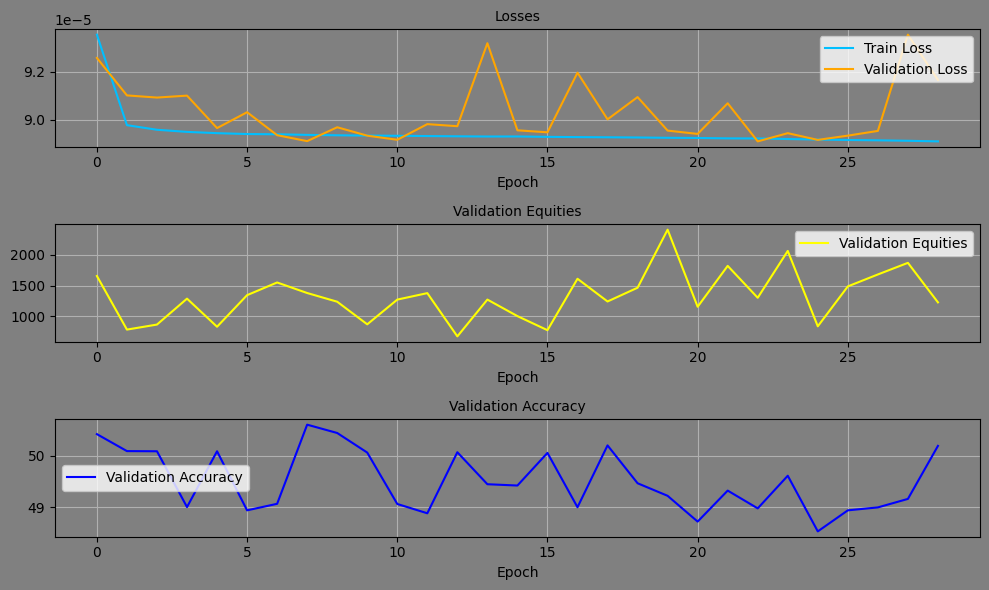

Epoch: 29, Val Equity: 1002.95, Val Accuracy: 49.69 train_losses: 0.0002773299149660163, val_losses: 9.008184133563191e-05, Duration: 0:01:46.458189


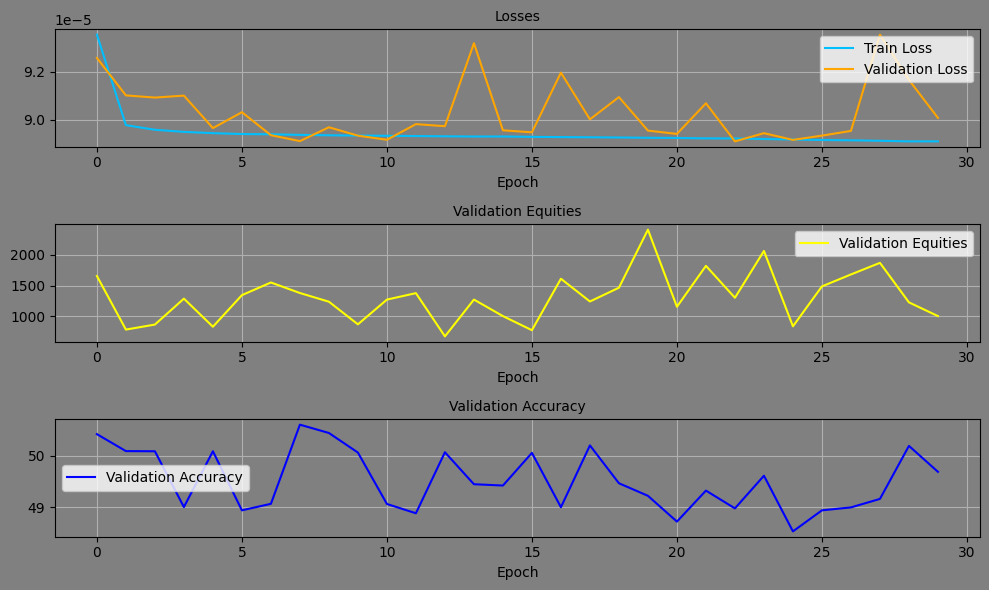

Epoch: 30, Val Equity: 1067.10, Val Accuracy: 50.24 train_losses: 0.0002772392341382987, val_losses: 9.030679939314723e-05, Duration: 0:01:46.857156


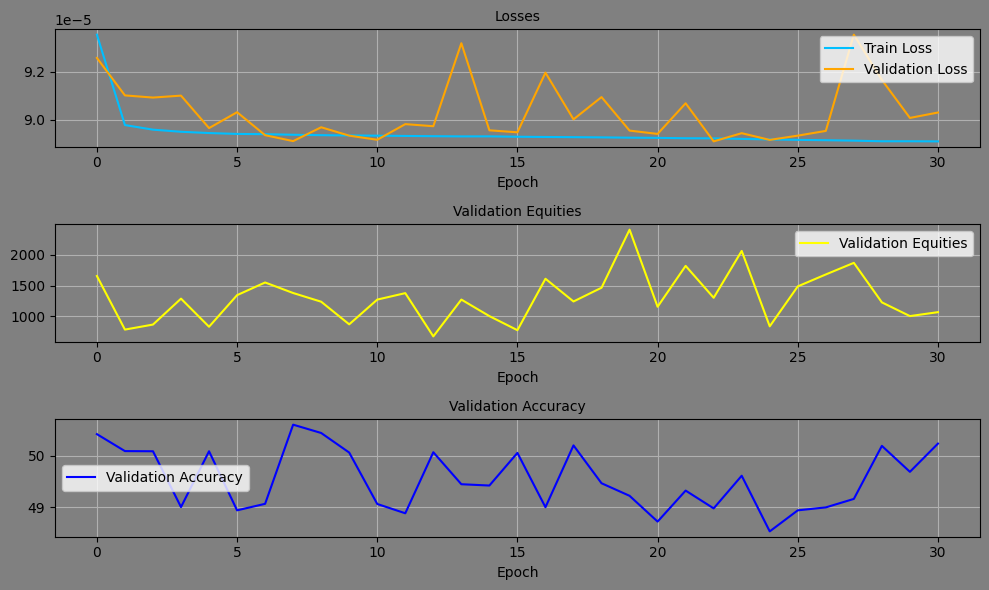

Epoch: 31, Val Equity: 2579.88, Val Accuracy: 49.30 train_losses: 0.00027682612356993264, val_losses: 8.922489359974861e-05, Duration: 0:01:45.600534


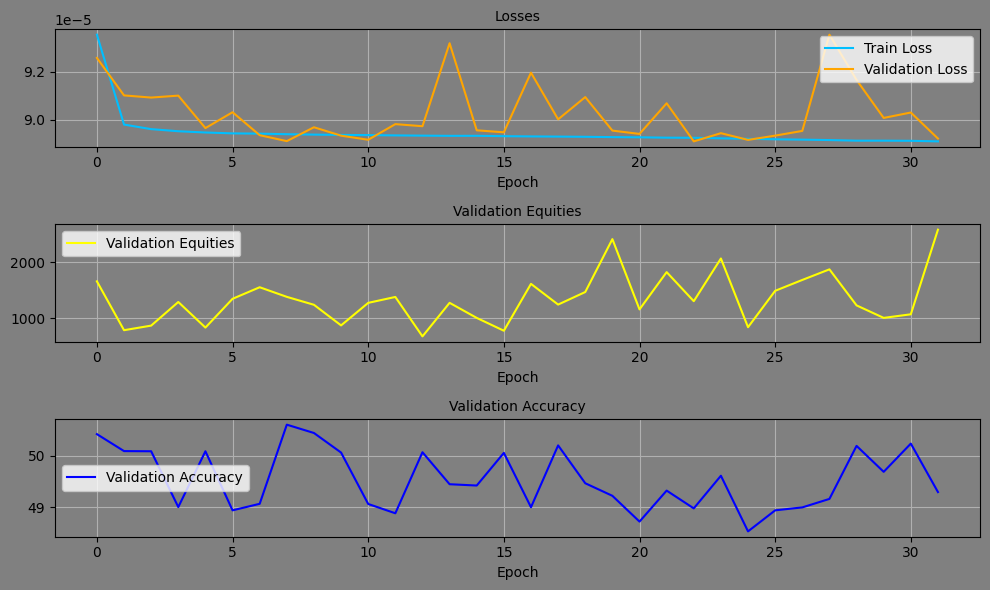

Epoch: 32, Val Equity: 1392.67, Val Accuracy: 50.23 train_losses: 0.0002766545883480468, val_losses: 9.02108004083857e-05, Duration: 0:02:00.157418


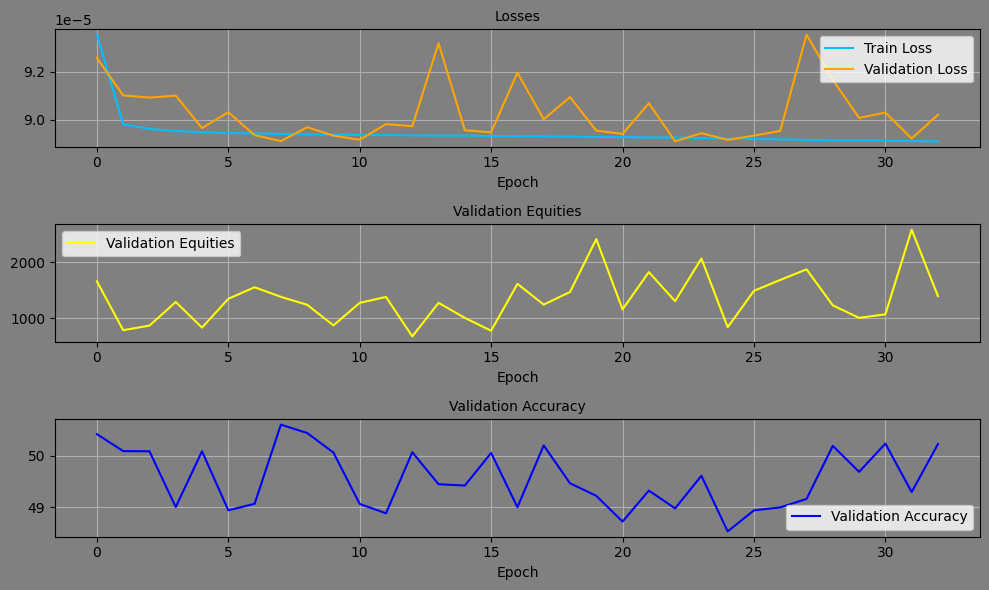

Epoch: 33, Val Equity: 769.20, Val Accuracy: 49.04 train_losses: 0.0002764885361887359, val_losses: 9.223697270499542e-05, Duration: 0:01:45.994256


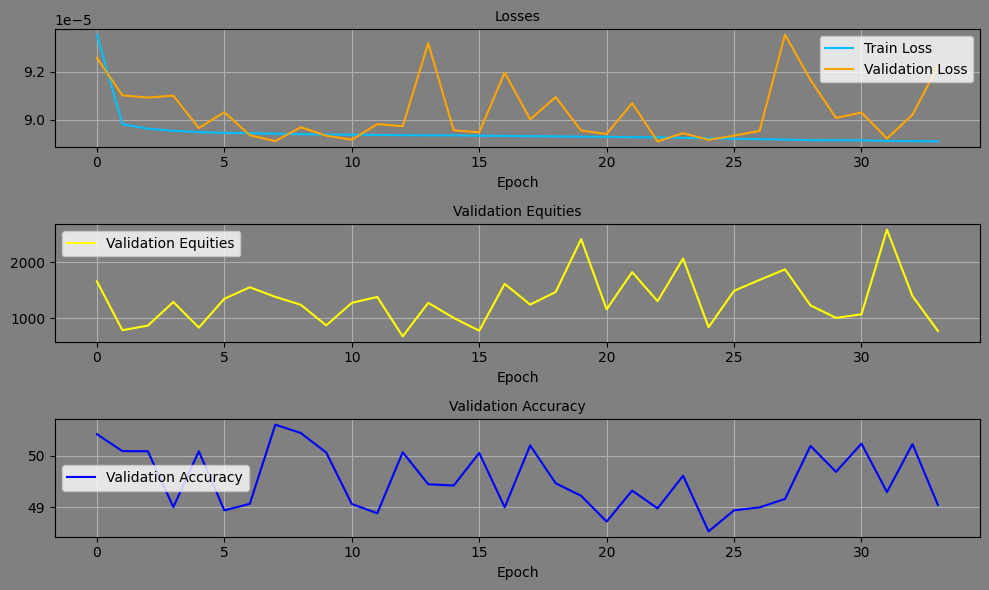

Epoch: 34, Val Equity: 1675.62, Val Accuracy: 48.75 train_losses: 0.0002765040366588755, val_losses: 8.990643254946917e-05, Duration: 0:01:45.527416


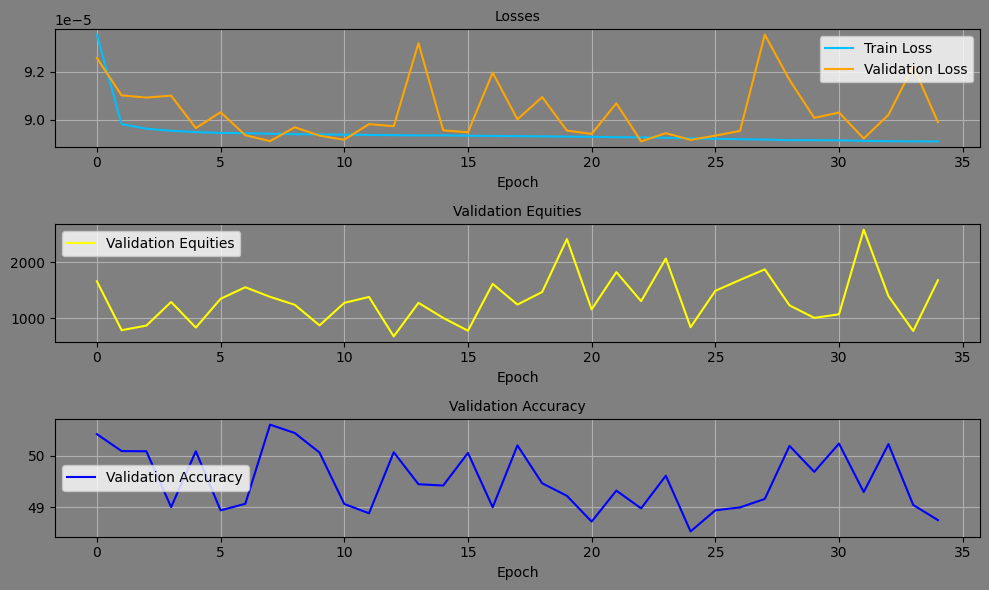

Epoch: 35, Val Equity: 1233.11, Val Accuracy: 50.14 train_losses: 0.0002763027803212026, val_losses: 9.041198063641787e-05, Duration: 0:01:46.494078


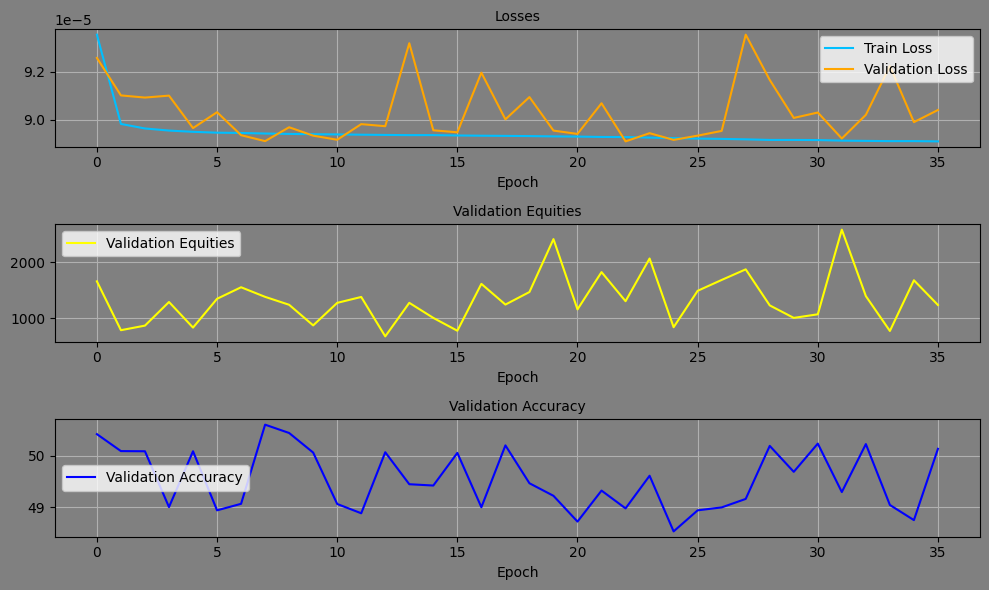

Epoch: 36, Val Equity: 2085.58, Val Accuracy: 49.25 train_losses: 0.0002761808057023818, val_losses: 9.195513121085241e-05, Duration: 0:01:45.842120


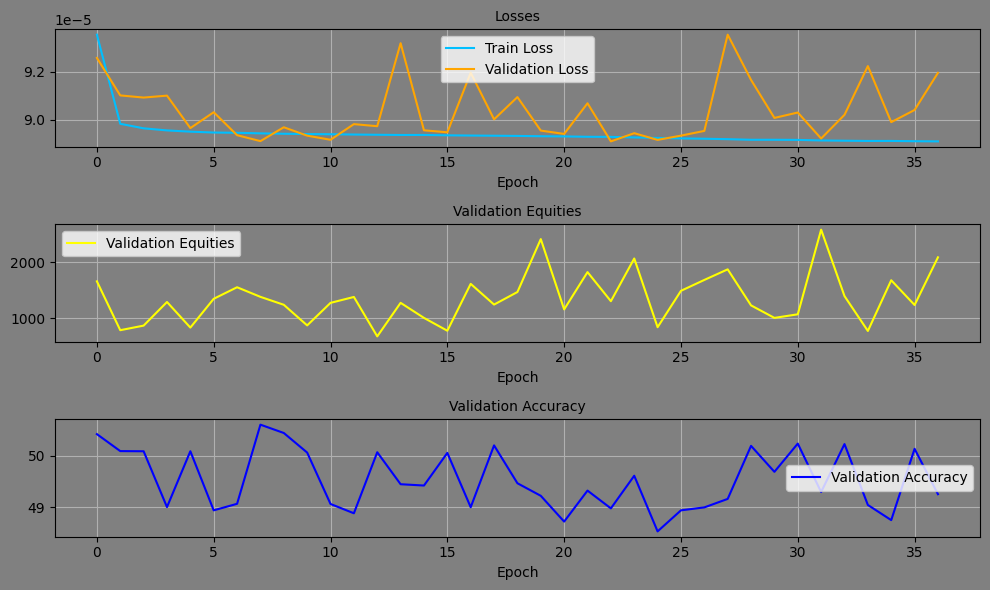

Epoch: 37, Val Equity: 1481.92, Val Accuracy: 49.24 train_losses: 0.00027611432407285784, val_losses: 8.926836017053574e-05, Duration: 0:01:45.864364


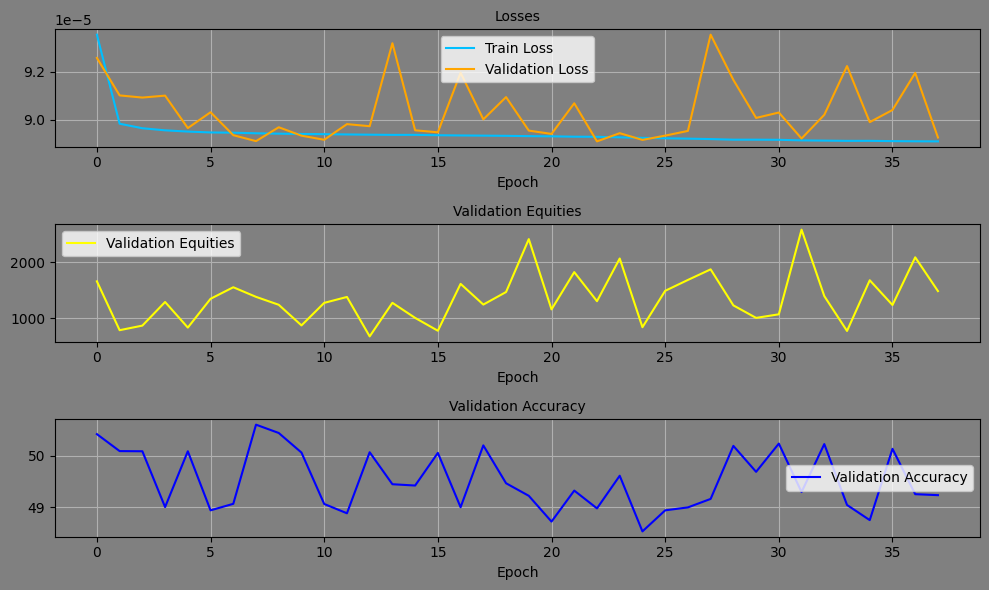

Epoch: 38, Val Equity: 2045.66, Val Accuracy: 49.42 train_losses: 0.00027582970513255375, val_losses: 8.940622501540929e-05, Duration: 0:01:44.289524


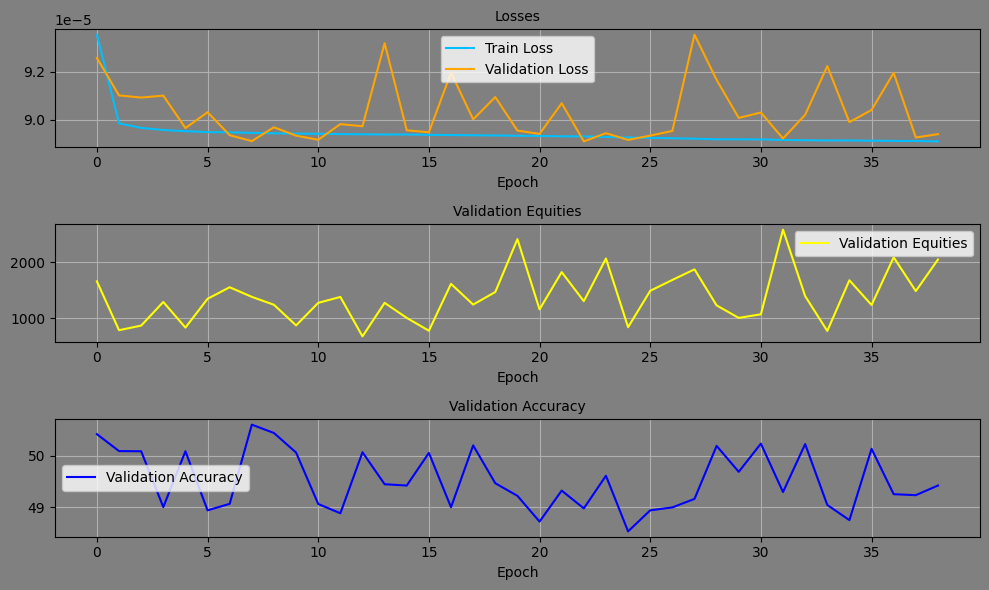

Epoch: 39, Val Equity: 1679.24, Val Accuracy: 49.33 train_losses: 0.0002758121147582006, val_losses: 8.93816541065462e-05, Duration: 0:01:45.883247


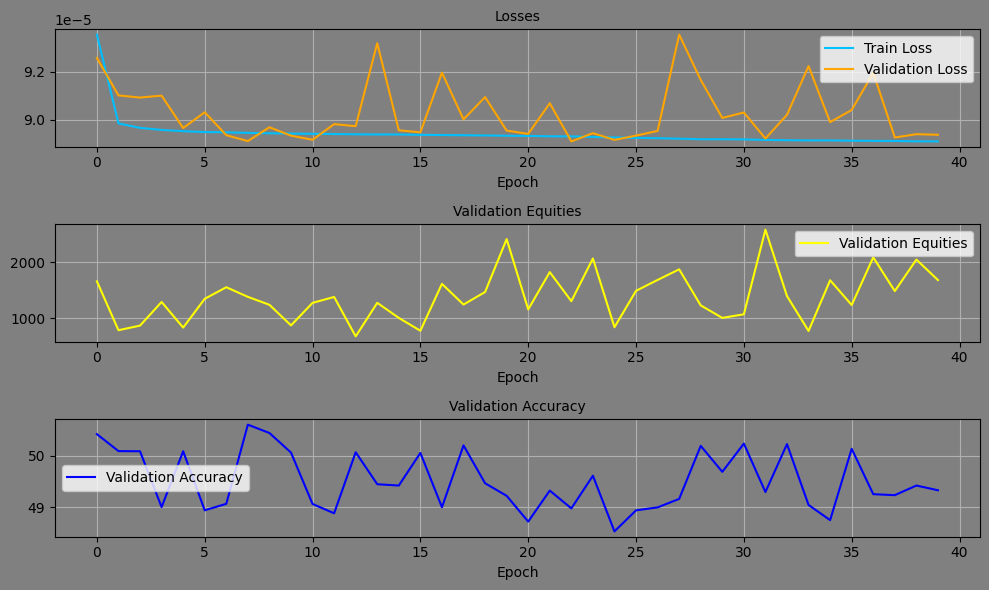

Epoch: 40, Val Equity: 2200.55, Val Accuracy: 48.95 train_losses: 0.0002756614238105095, val_losses: 8.972928480943665e-05, Duration: 0:01:45.129928


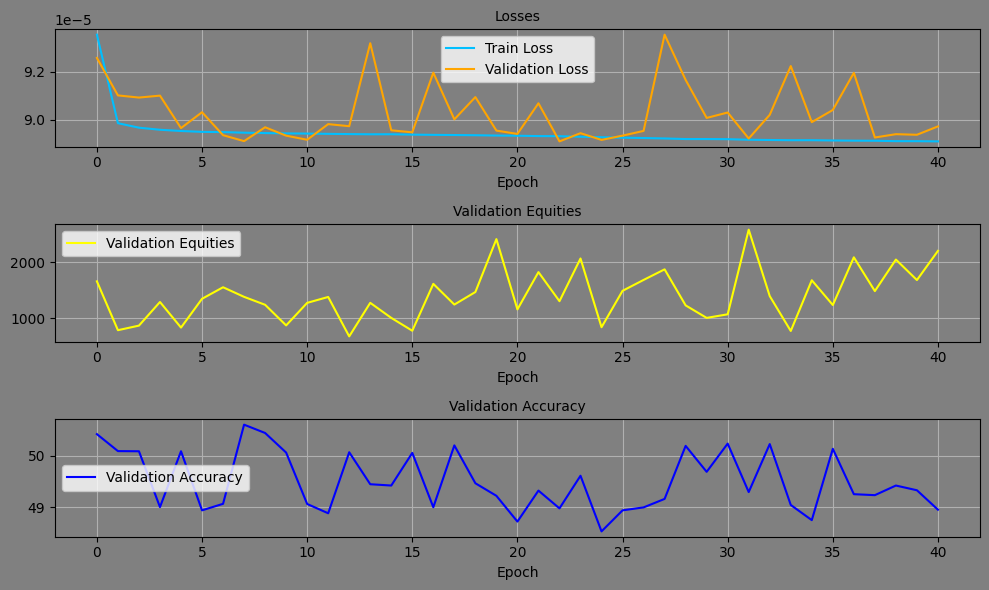

Epoch: 41, Val Equity: 1457.28, Val Accuracy: 48.96 train_losses: 0.0002755629579003956, val_losses: 9.001476428238675e-05, Duration: 0:01:44.203877


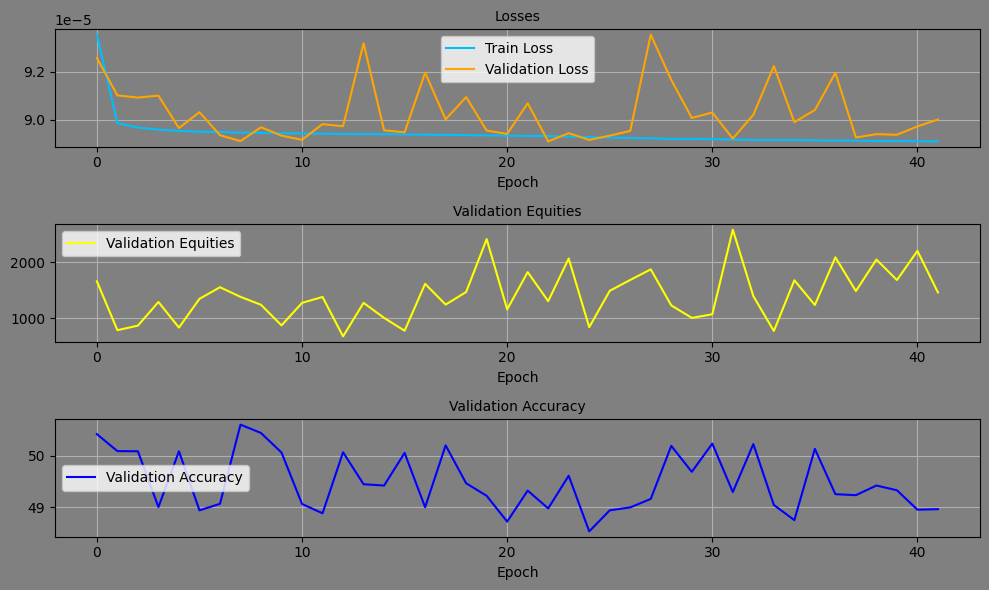

Epoch: 42, Val Equity: 1155.42, Val Accuracy: 48.76 train_losses: 0.0002754651251196753, val_losses: 9.01280072866939e-05, Duration: 0:01:44.779382


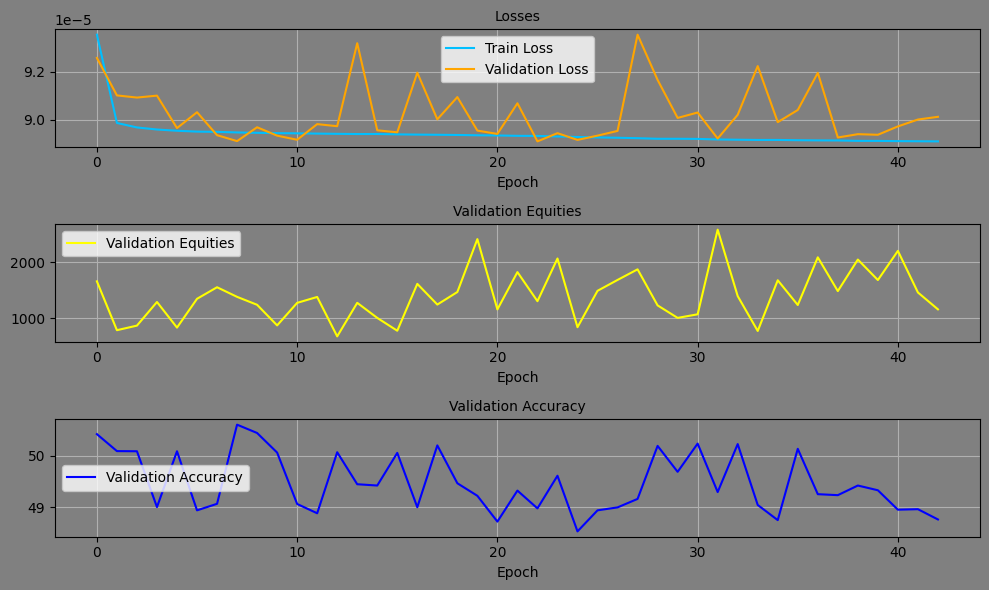

Epoch: 43, Val Equity: 1590.94, Val Accuracy: 49.96 train_losses: 0.00027533343655442315, val_losses: 9.099932503886521e-05, Duration: 0:01:46.608615


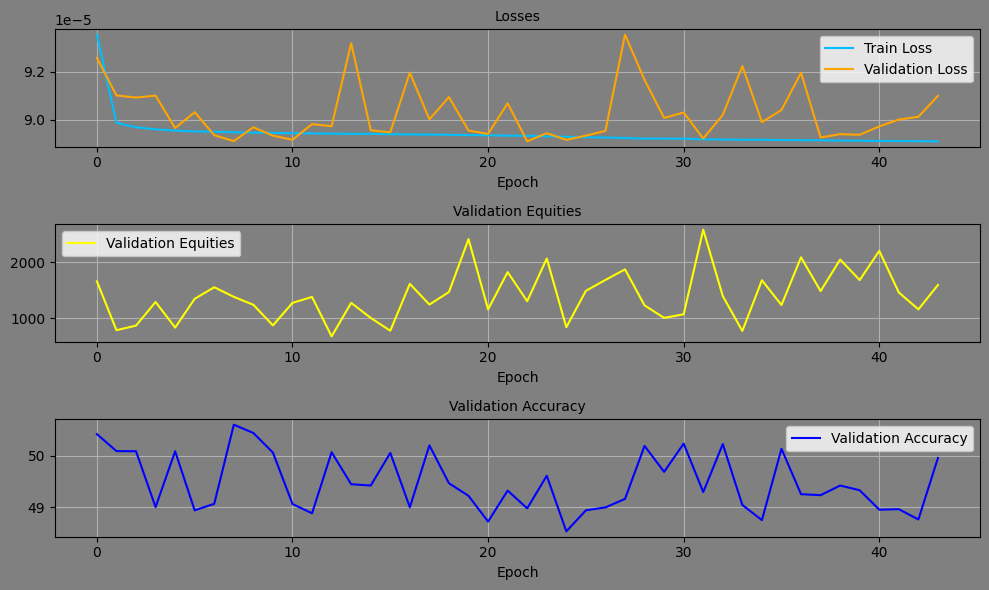

Epoch: 44, Val Equity: 1993.05, Val Accuracy: 49.12 train_losses: 0.00027518907573976766, val_losses: 8.955703378887847e-05, Duration: 0:01:44.575487


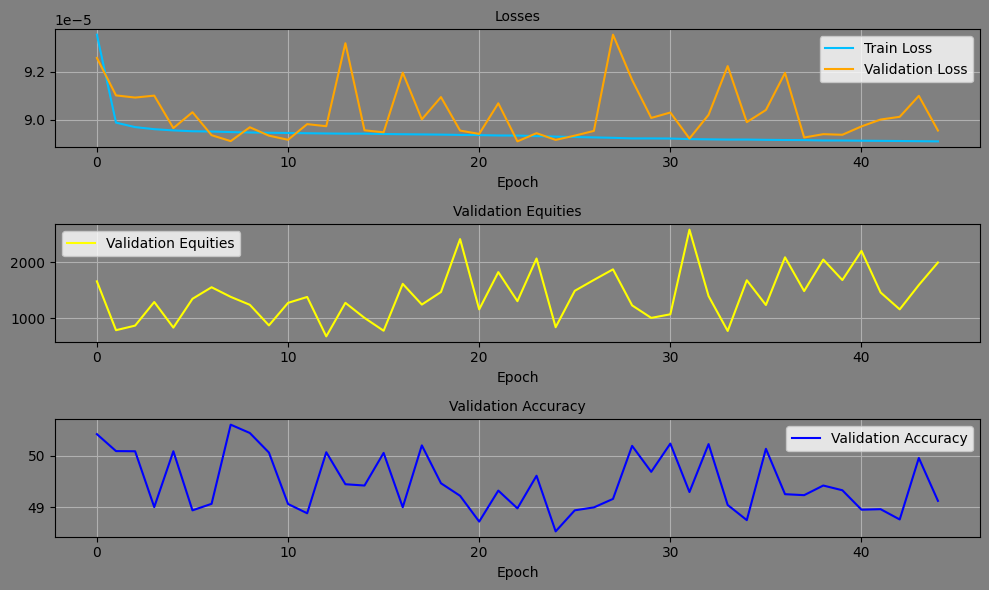

Epoch: 45, Val Equity: 1164.45, Val Accuracy: 49.64 train_losses: 0.000275077021667788, val_losses: 8.908634481485933e-05, Duration: 0:01:44.851965


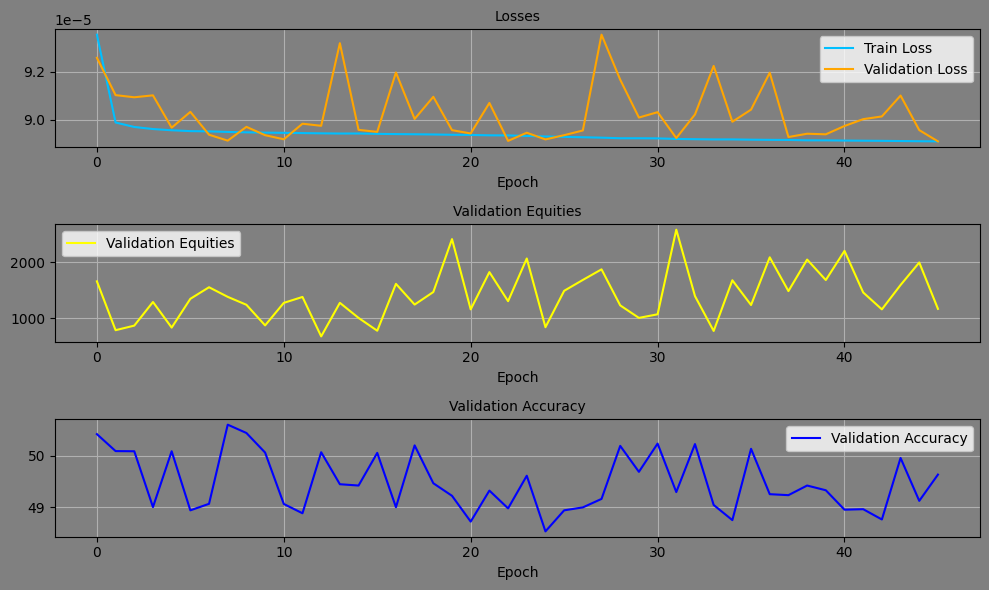

Epoch: 46, Val Equity: 1612.59, Val Accuracy: 50.02 train_losses: 0.0002749054797337573, val_losses: 8.934794459491968e-05, Duration: 0:01:46.230018


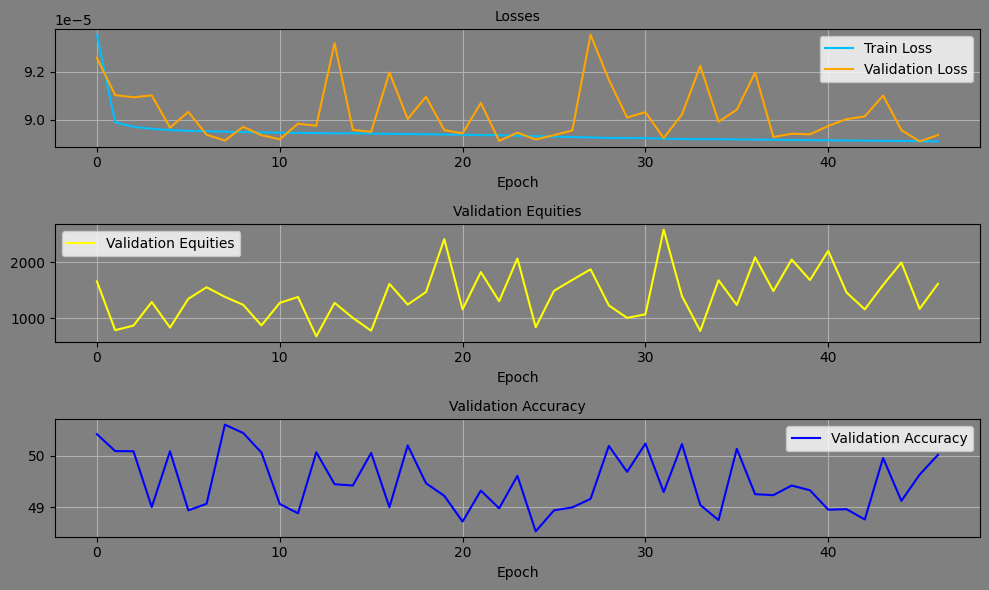

Epoch: 47, Val Equity: 1281.73, Val Accuracy: 50.27 train_losses: 0.00027473327072464495, val_losses: 8.998050179798156e-05, Duration: 0:01:47.007854


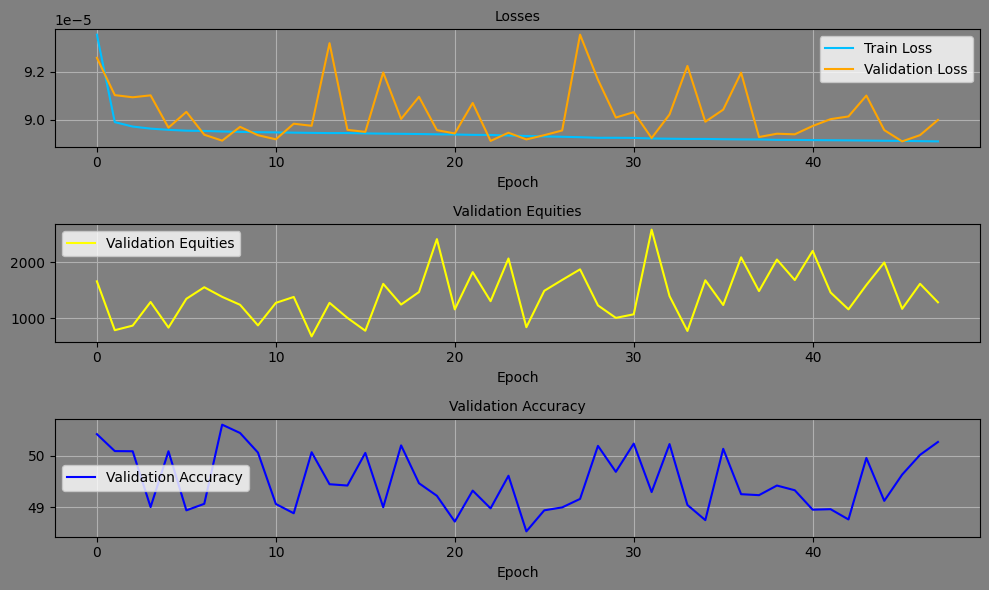

Epoch: 48, Val Equity: 2818.69, Val Accuracy: 49.54 train_losses: 0.0002747841010932276, val_losses: 8.94244440132752e-05, Duration: 0:01:46.513818


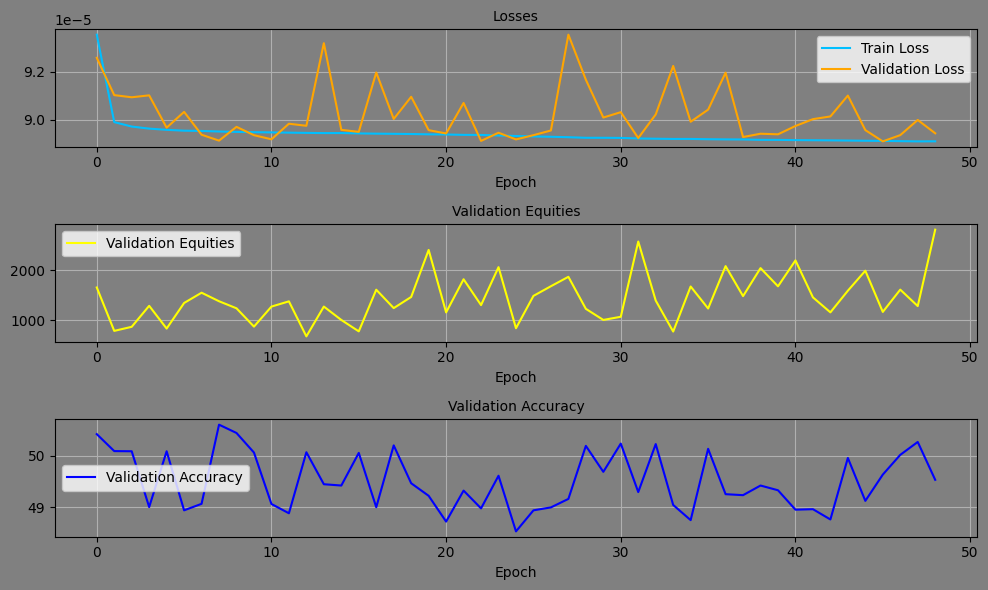

Epoch: 49, Val Equity: 2285.50, Val Accuracy: 50.63 train_losses: 0.00027452239036960223, val_losses: 8.912759949453175e-05, Duration: 0:01:46.769311


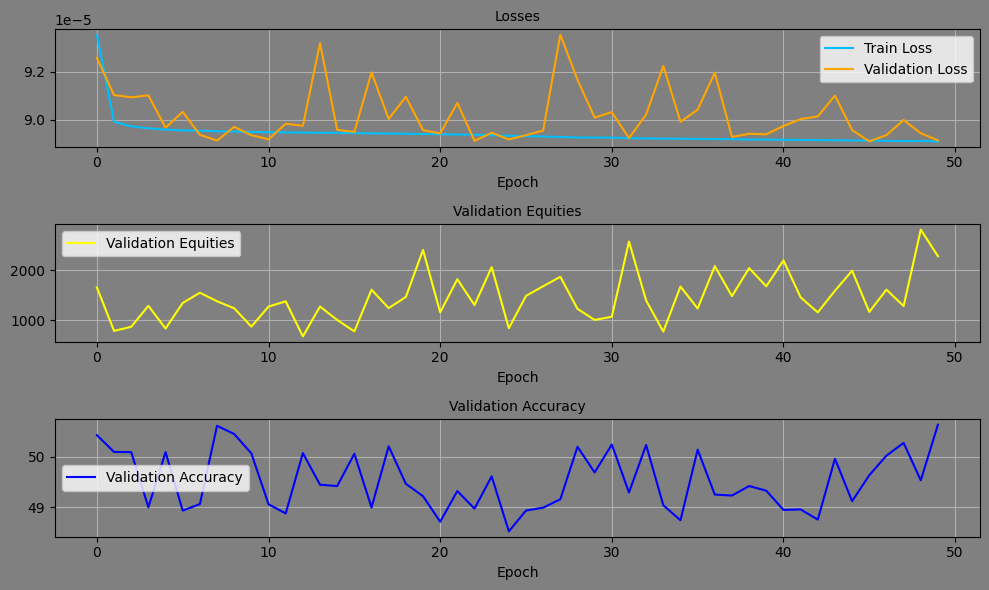

Epoch: 50, Val Equity: 1733.58, Val Accuracy: 50.07 train_losses: 0.000274493829989034, val_losses: 8.943620196077973e-05, Duration: 0:01:46.475786


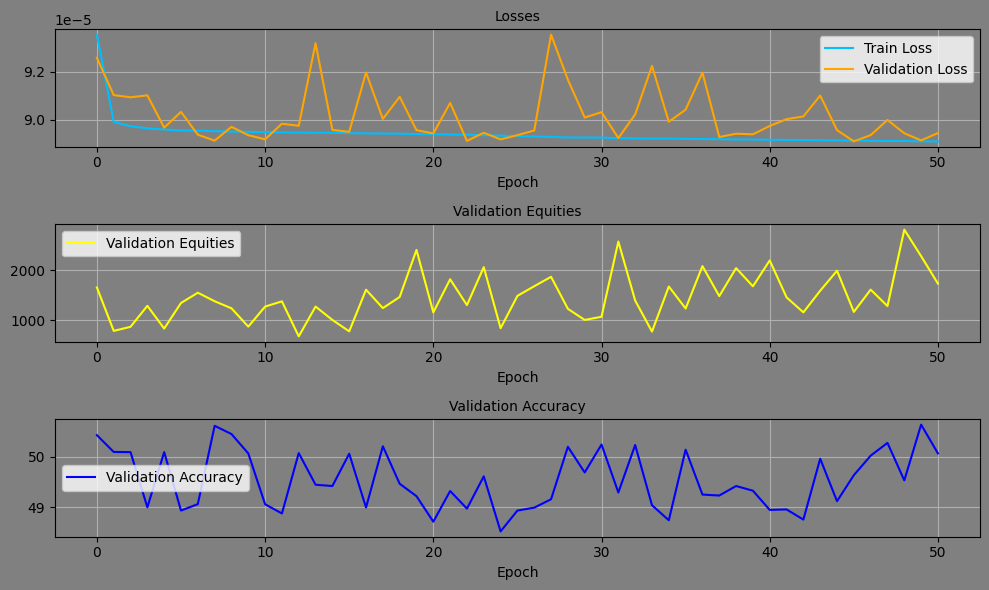

Epoch: 51, Val Equity: 866.76, Val Accuracy: 49.27 train_losses: 0.0002741061087236424, val_losses: 8.952305506682023e-05, Duration: 0:01:46.433084


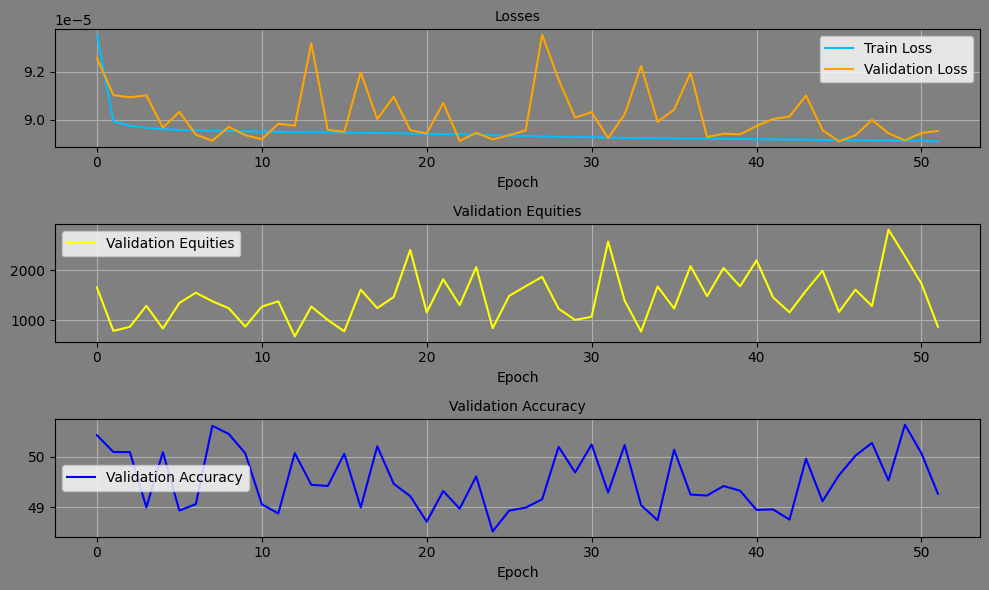

Epoch: 52, Val Equity: 1317.92, Val Accuracy: 50.16 train_losses: 0.00027391015001745564, val_losses: 8.910753967938945e-05, Duration: 0:01:45.205469


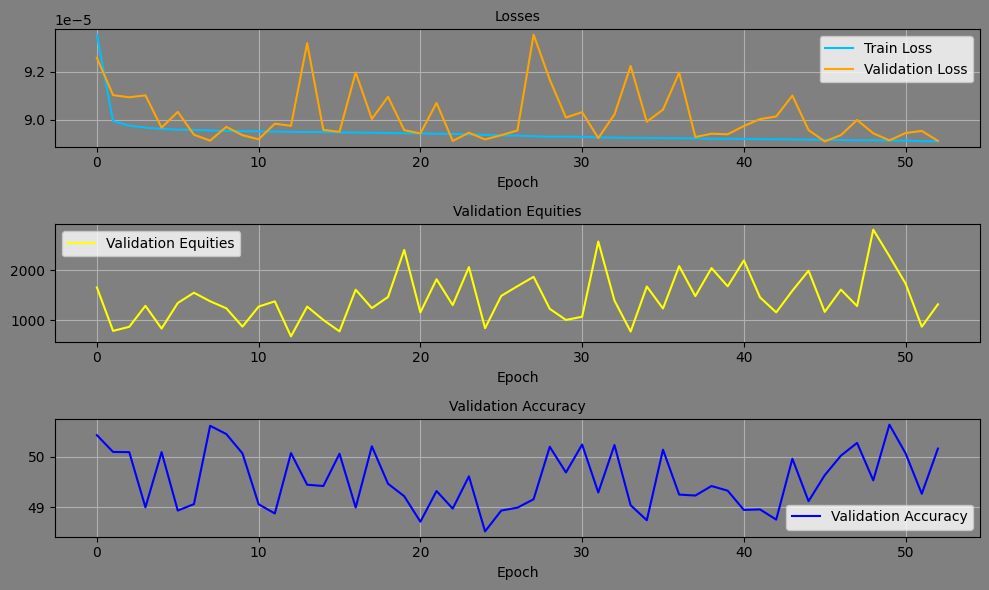

Epoch: 53, Val Equity: 1977.70, Val Accuracy: 49.11 train_losses: 0.0002737092072618175, val_losses: 8.970382623374462e-05, Duration: 0:01:45.368514


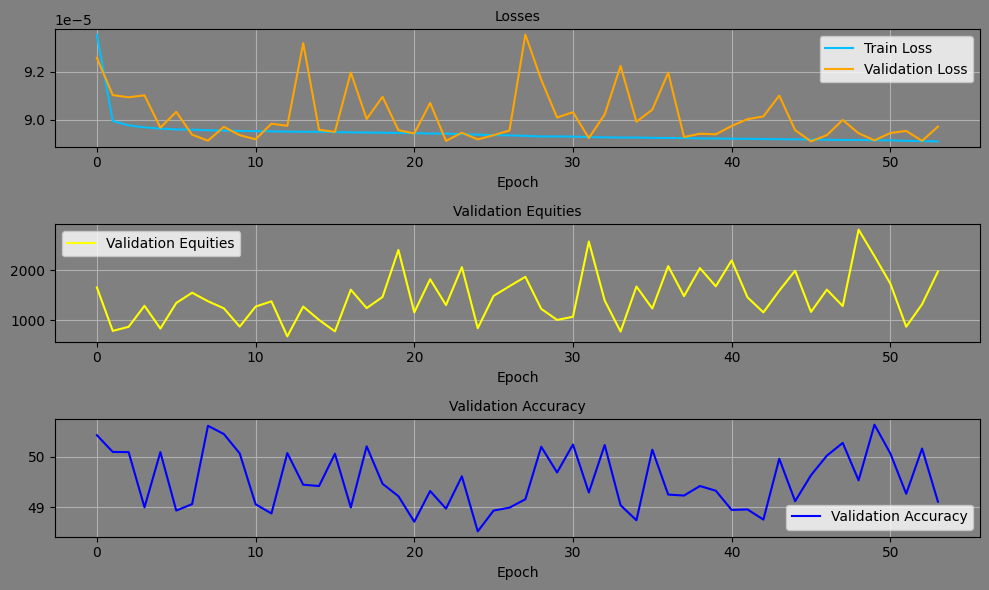

Epoch: 54, Val Equity: 1520.53, Val Accuracy: 49.00 train_losses: 0.00027362774869928446, val_losses: 9.016985859489068e-05, Duration: 0:01:44.886788


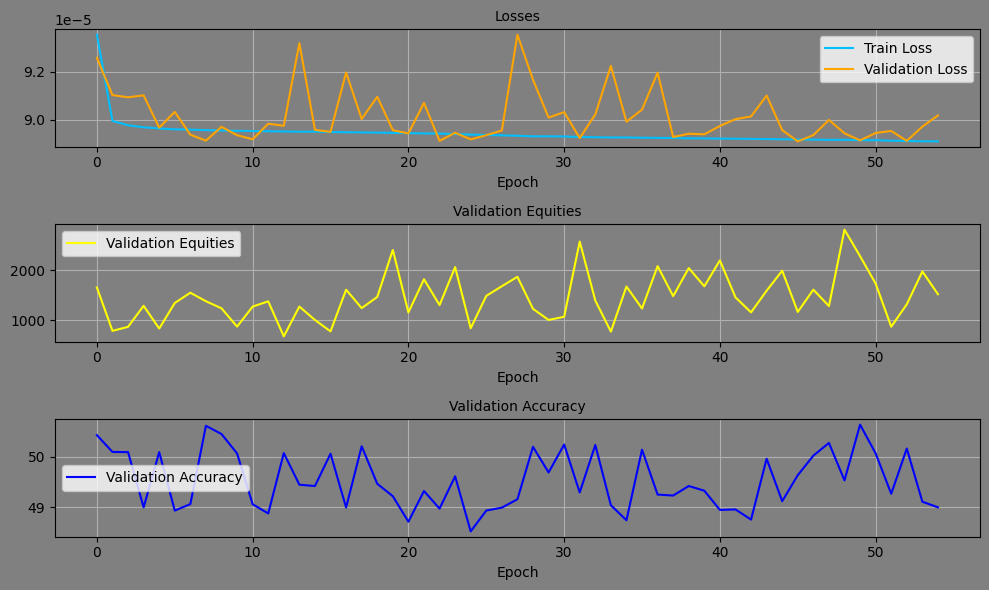

Epoch: 55, Val Equity: 1655.14, Val Accuracy: 50.57 train_losses: 0.0002734500703864774, val_losses: 8.936183439800516e-05, Duration: 0:01:44.657485


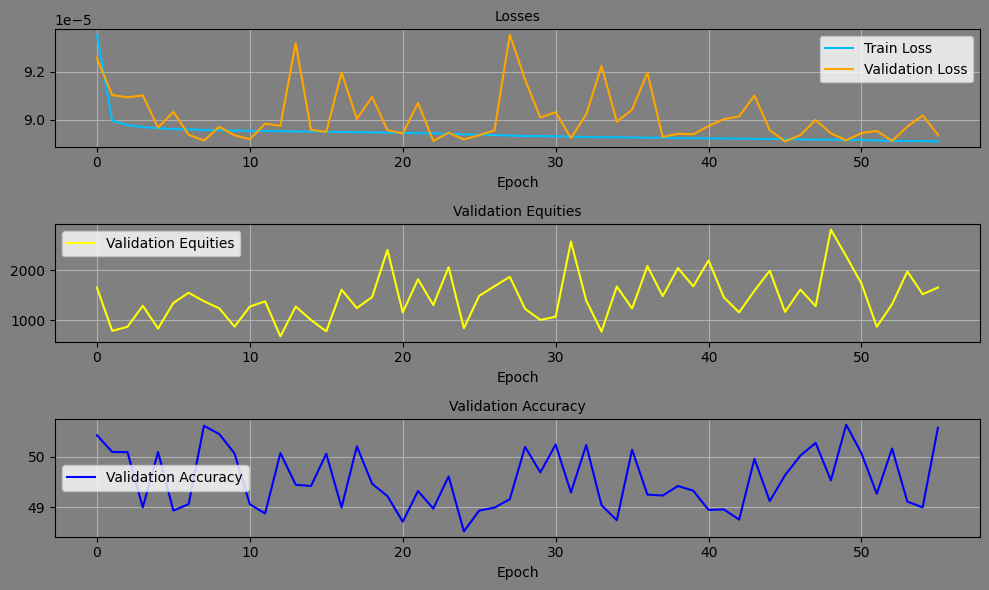

Epoch: 56, Val Equity: 2287.34, Val Accuracy: 50.98 train_losses: 0.00027345192181591176, val_losses: 8.942150452639908e-05, Duration: 0:01:44.861092


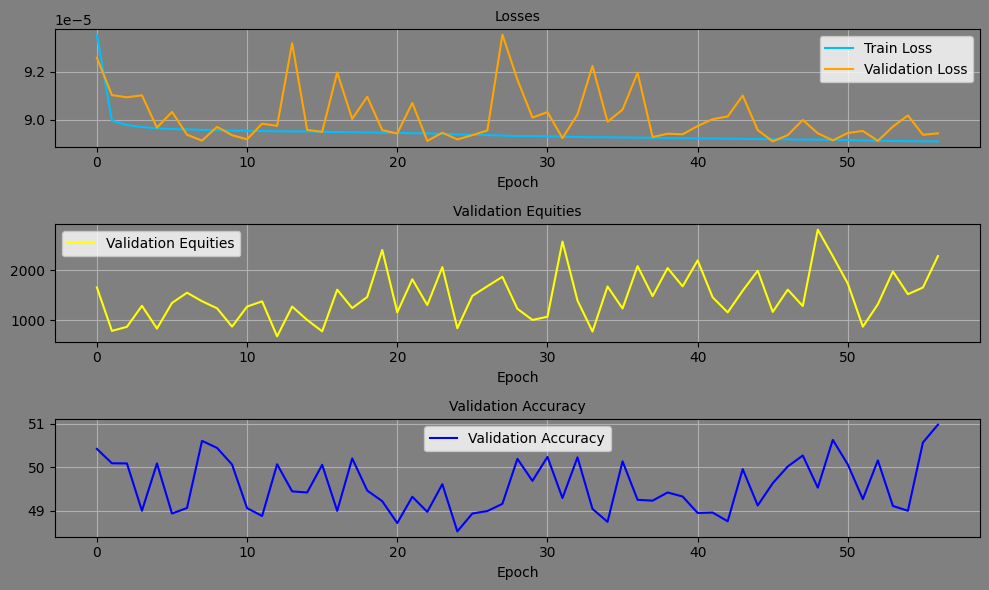

Epoch: 57, Val Equity: 1151.30, Val Accuracy: 49.12 train_losses: 0.00027339966381839437, val_losses: 8.898087253328413e-05, Duration: 0:01:44.625561


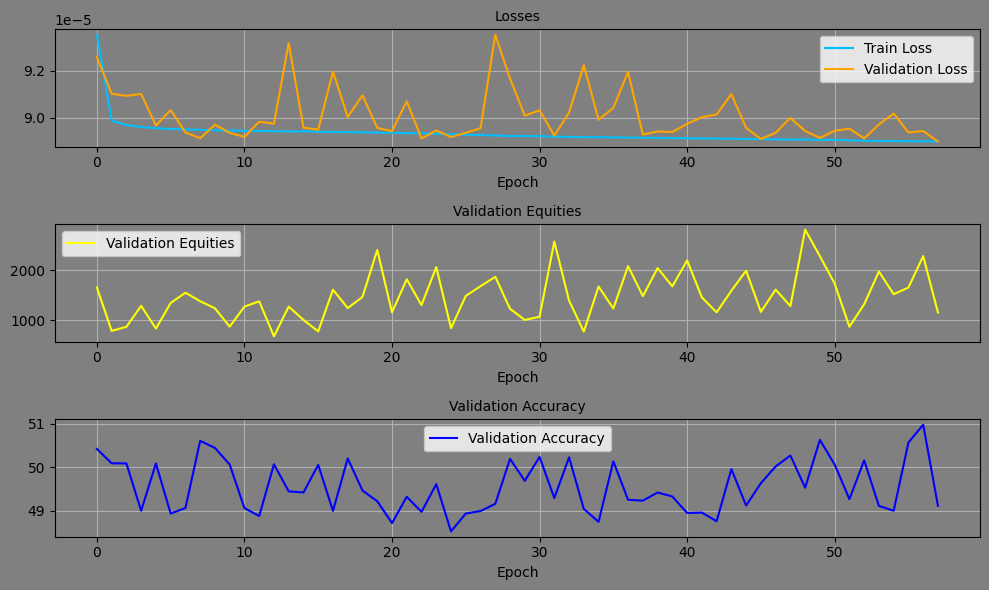

Epoch: 58, Val Equity: 1852.88, Val Accuracy: 50.58 train_losses: 0.00027304379391704224, val_losses: 8.903397247195244e-05, Duration: 0:01:45.488496


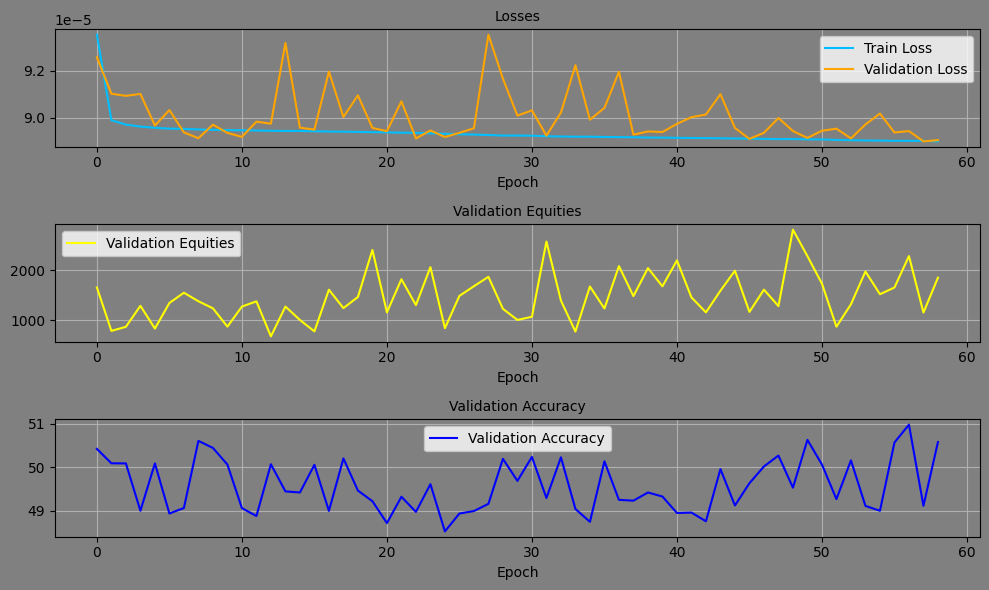

Epoch: 59, Val Equity: 1215.01, Val Accuracy: 50.23 train_losses: 0.0002728811444343614, val_losses: 9.043403406394646e-05, Duration: 0:01:45.121525


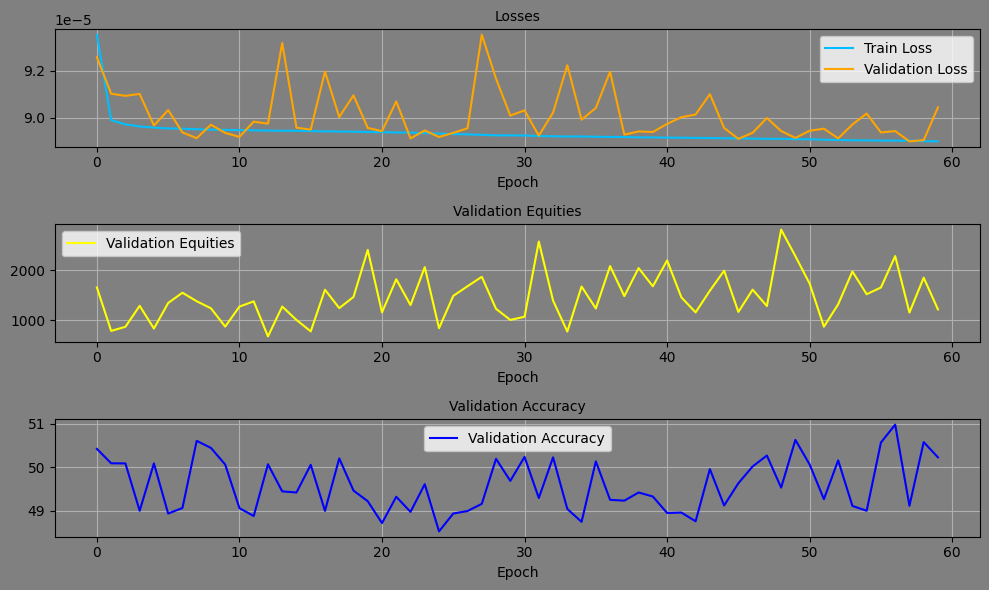

Epoch: 60, Val Equity: 2021.15, Val Accuracy: 50.30 train_losses: 0.0002727176133758781, val_losses: 8.973724470706657e-05, Duration: 0:01:45.454540


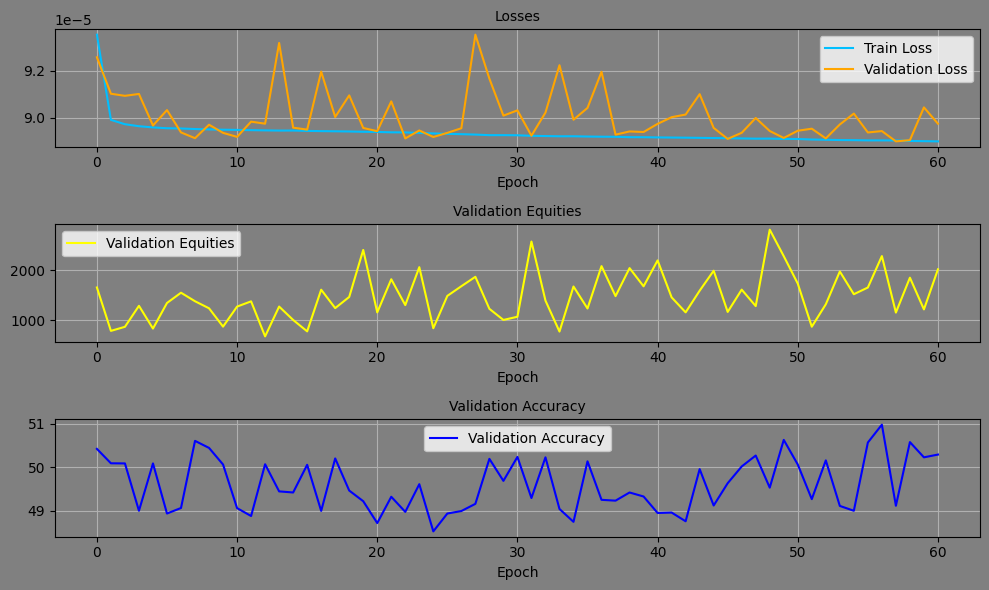

Epoch: 61, Val Equity: 1158.13, Val Accuracy: 50.55 train_losses: 0.0002726557976071431, val_losses: 8.94928743946366e-05, Duration: 0:01:43.925355


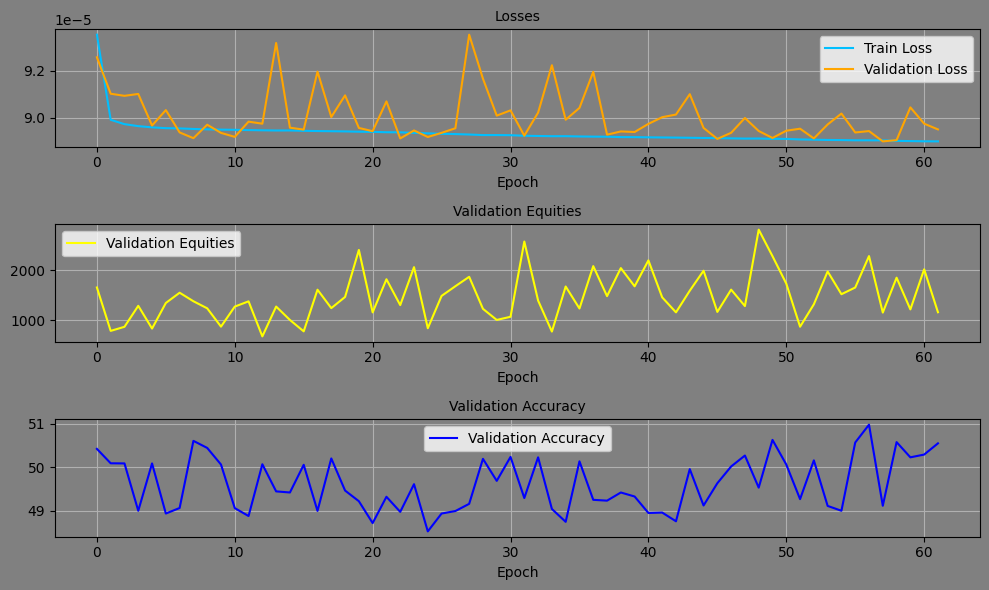

Epoch: 62, Val Equity: 1657.48, Val Accuracy: 48.97 train_losses: 0.00027247425516052095, val_losses: 8.896896906662732e-05, Duration: 0:01:46.057846


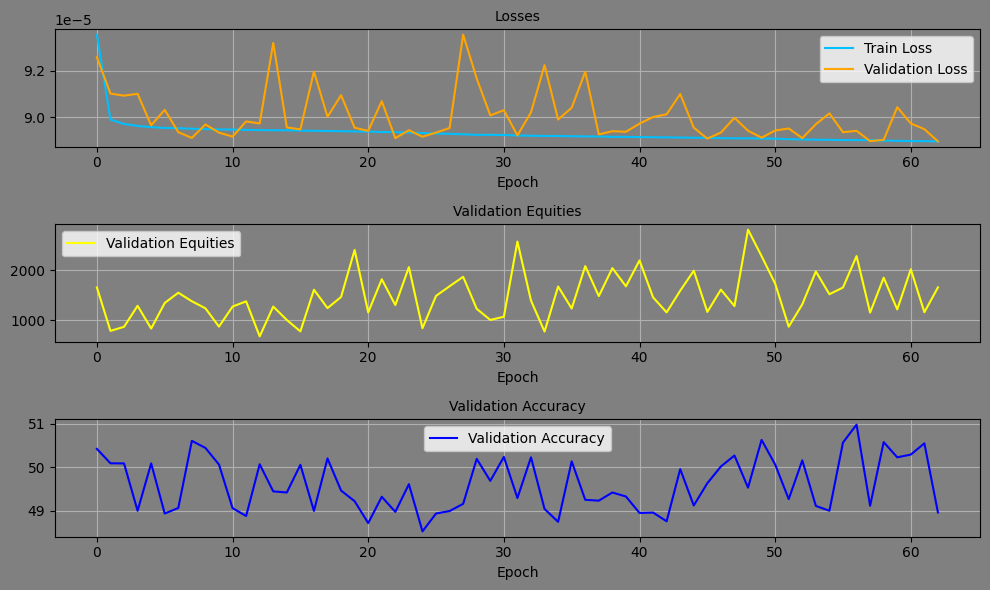

Epoch: 63, Val Equity: 1736.11, Val Accuracy: 51.61 train_losses: 0.0002725520920758695, val_losses: 8.925714791985229e-05, Duration: 0:01:44.992540


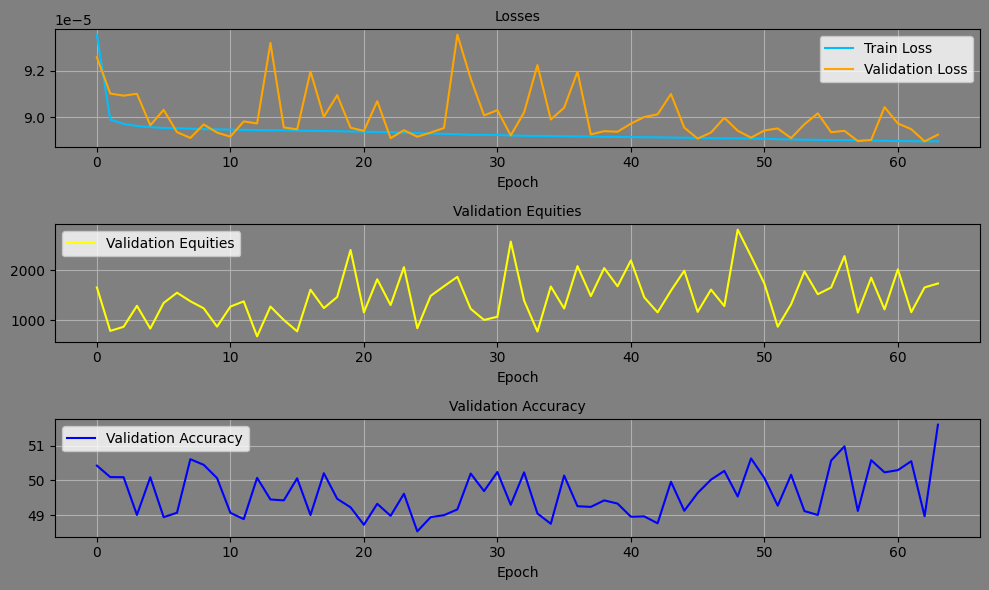

Epoch: 64, Val Equity: 933.95, Val Accuracy: 50.21 train_losses: 0.0002721921177986935, val_losses: 9.001967555377632e-05, Duration: 0:01:45.860458


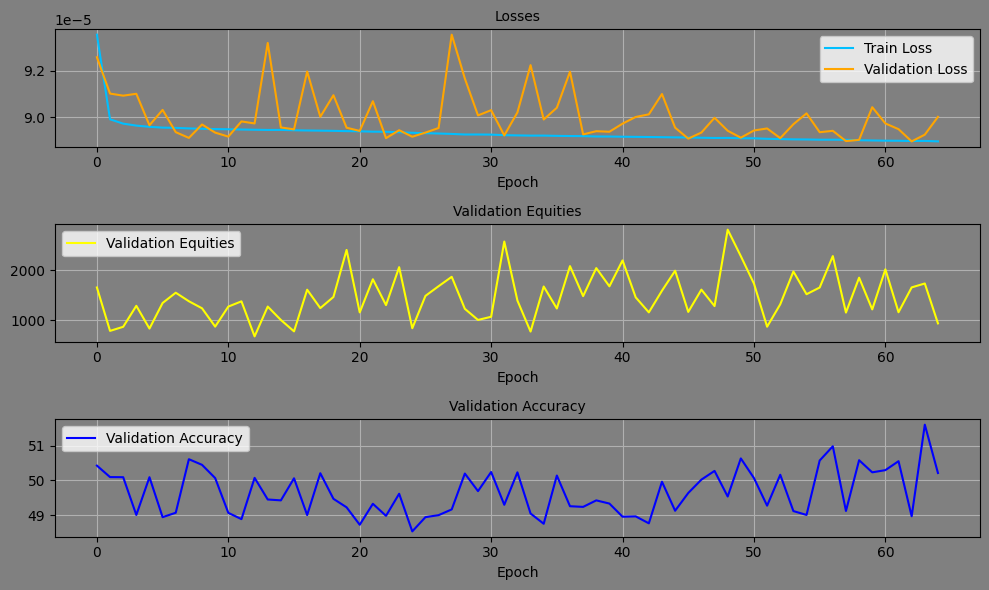

Epoch: 65, Val Equity: 1900.89, Val Accuracy: 49.47 train_losses: 0.0002721990090987408, val_losses: 8.871366298990324e-05, Duration: 0:01:44.768763


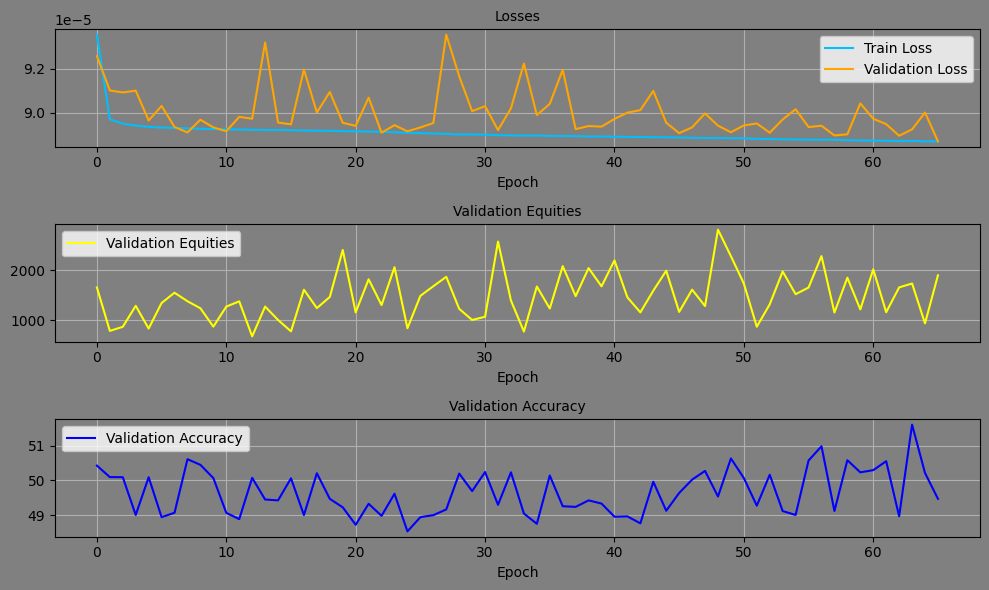

Epoch: 66, Val Equity: 1428.28, Val Accuracy: 49.12 train_losses: 0.0002721127243705076, val_losses: 9.060008596861735e-05, Duration: 0:01:45.148098


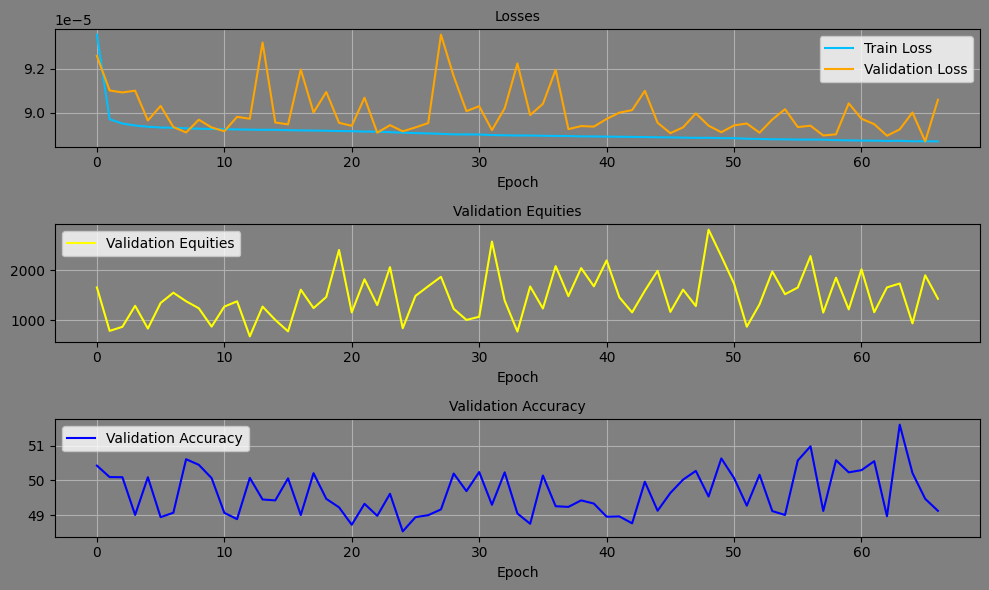

Epoch: 67, Val Equity: 1747.88, Val Accuracy: 49.00 train_losses: 0.0002719107576569321, val_losses: 9.048372157849371e-05, Duration: 0:01:46.625301


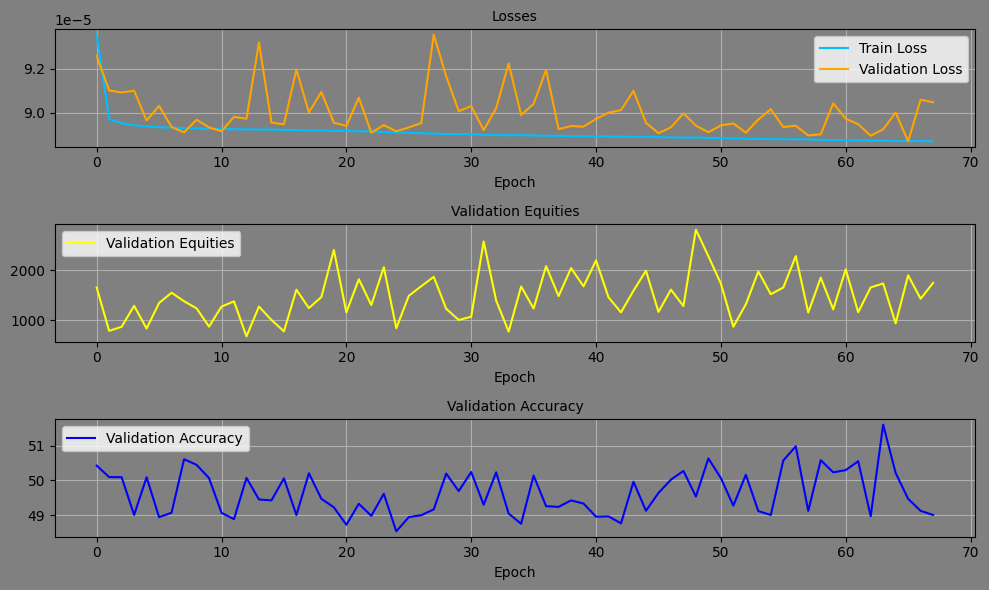

Epoch: 68, Val Equity: 1944.62, Val Accuracy: 49.35 train_losses: 0.00027188256572015424, val_losses: 8.919859828893095e-05, Duration: 0:01:44.932187


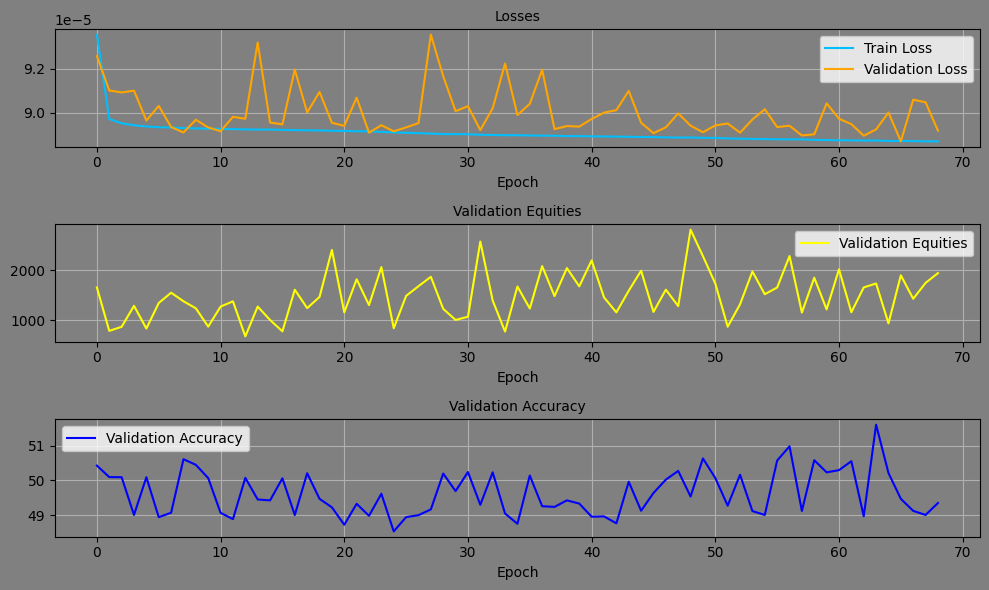

Epoch: 69, Val Equity: 1803.29, Val Accuracy: 49.08 train_losses: 0.0002718470521980583, val_losses: 8.955862722359598e-05, Duration: 0:01:44.606601


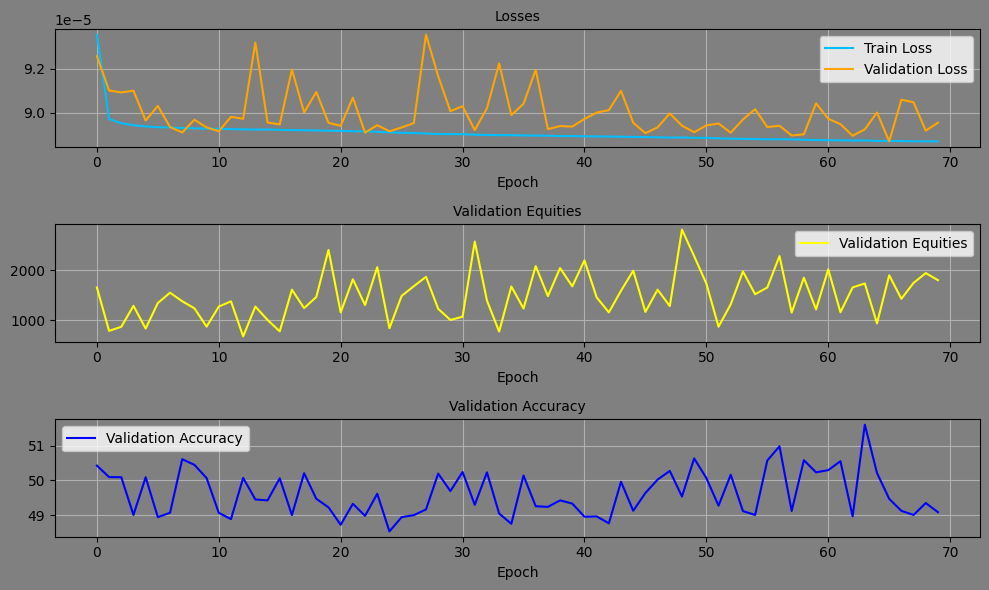

Epoch: 70, Val Equity: 1477.18, Val Accuracy: 50.20 train_losses: 0.00027177873967158985, val_losses: 8.941419946495444e-05, Duration: 0:01:44.815654


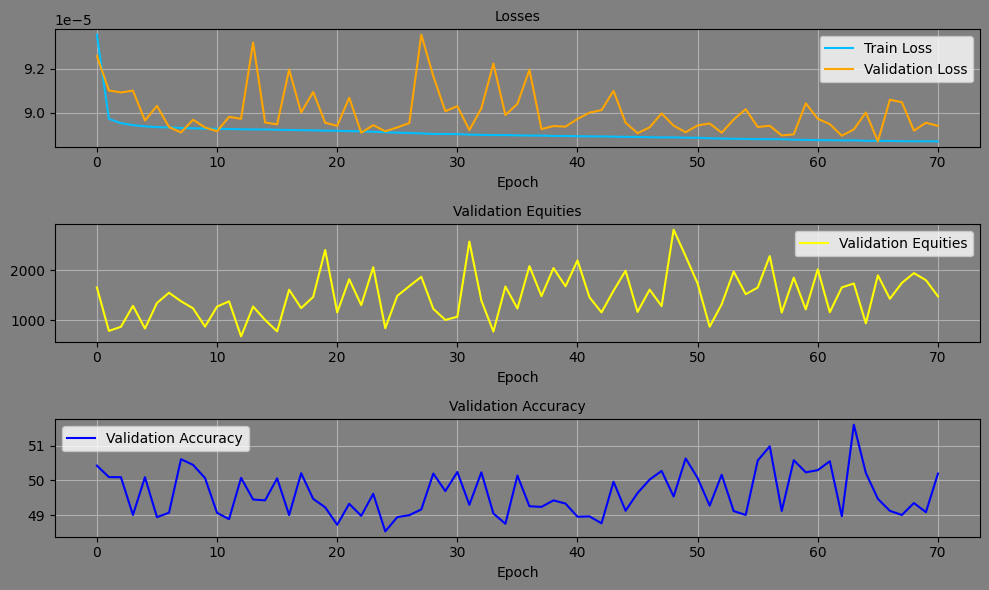

Epoch: 71, Val Equity: 1478.99, Val Accuracy: 49.88 train_losses: 0.00027166172566470836, val_losses: 8.897986845113337e-05, Duration: 0:01:43.675143


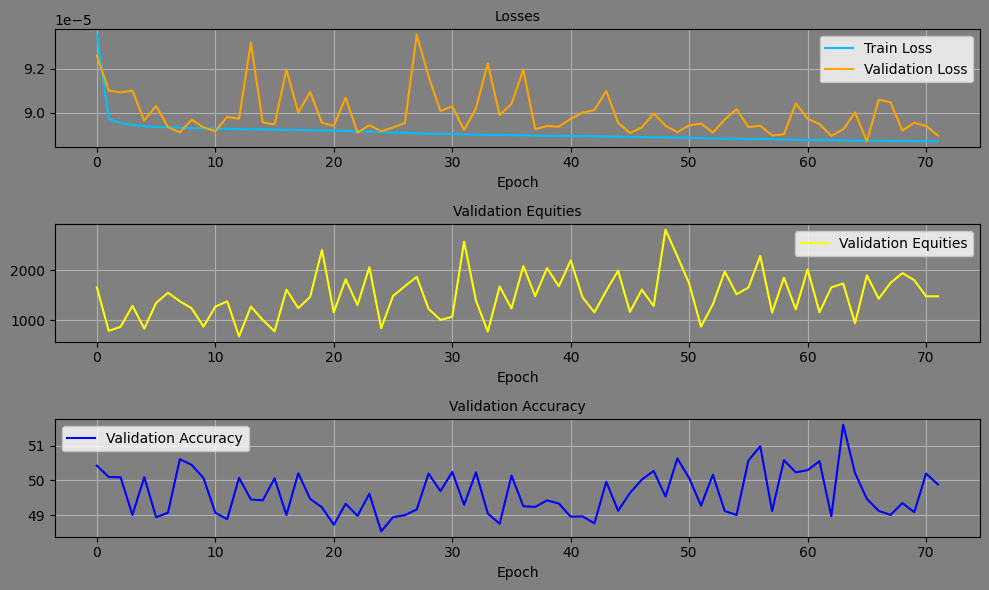

Epoch: 72, Val Equity: 1649.88, Val Accuracy: 50.43 train_losses: 0.0002713939154439804, val_losses: 8.937992242863402e-05, Duration: 0:01:44.679413


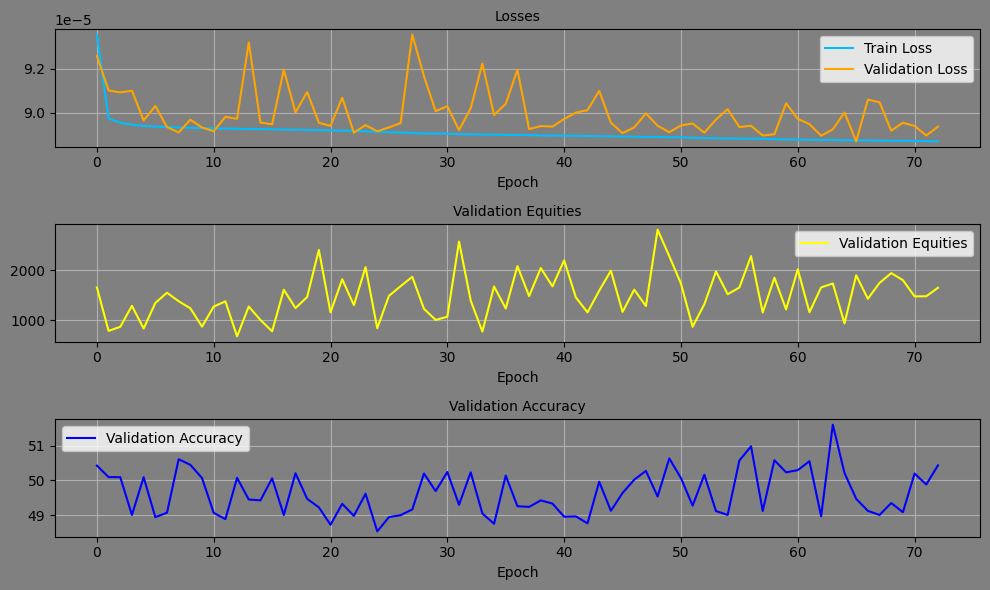

Epoch: 73, Val Equity: 1345.23, Val Accuracy: 49.85 train_losses: 0.000271230575831359, val_losses: 8.924320718506351e-05, Duration: 0:01:44.363500


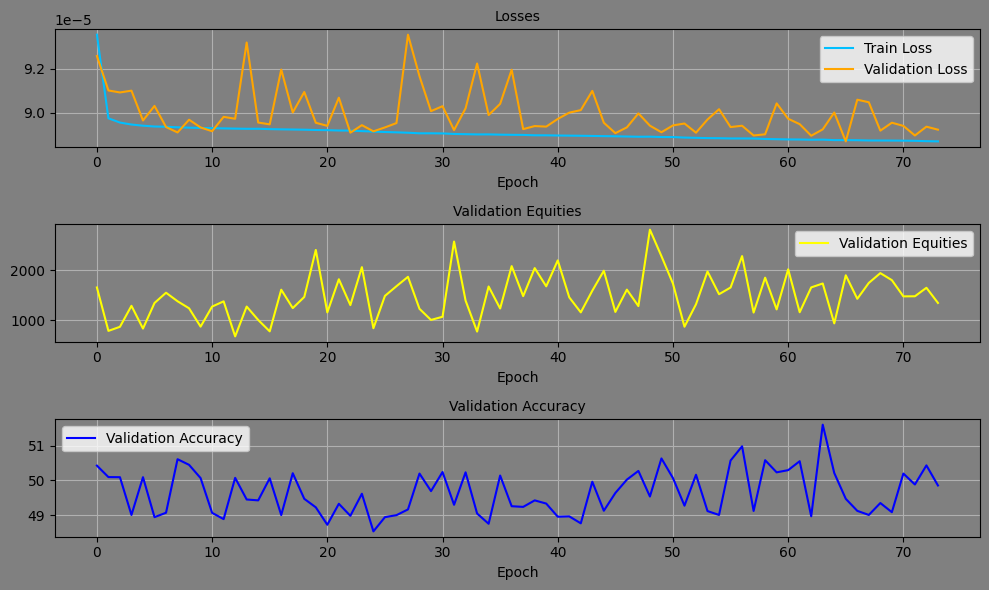

Epoch: 74, Val Equity: 1396.87, Val Accuracy: 50.40 train_losses: 0.0002713286031616843, val_losses: 8.919557149056345e-05, Duration: 0:01:43.710986


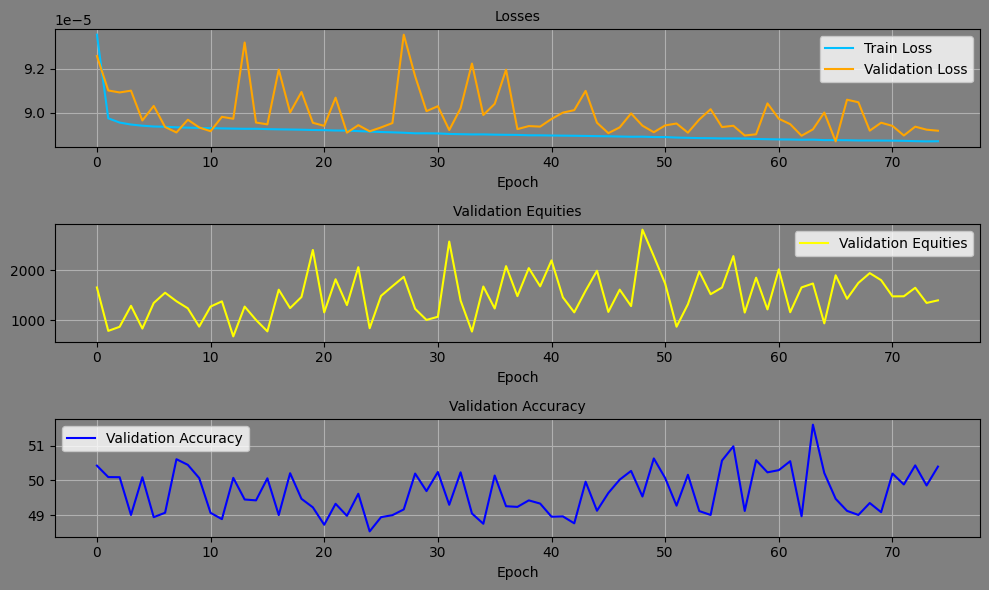

Epoch: 75, Val Equity: 1227.43, Val Accuracy: 50.67 train_losses: 0.0002711941654019125, val_losses: 8.880127279553562e-05, Duration: 0:01:45.314999


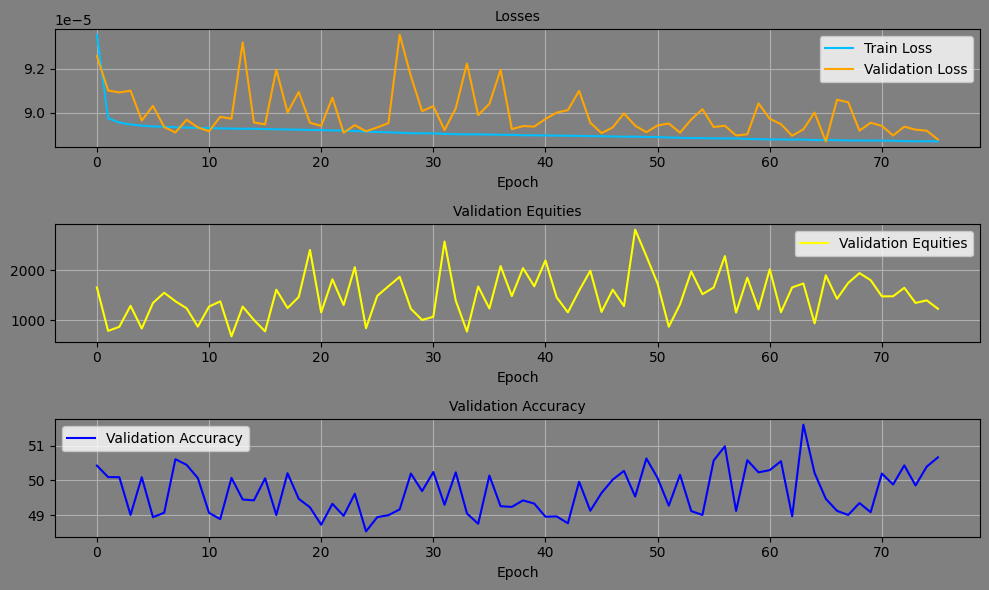

Epoch: 76, Val Equity: 974.13, Val Accuracy: 50.11 train_losses: 0.0002709874249992795, val_losses: 8.926271402742714e-05, Duration: 0:01:45.666887


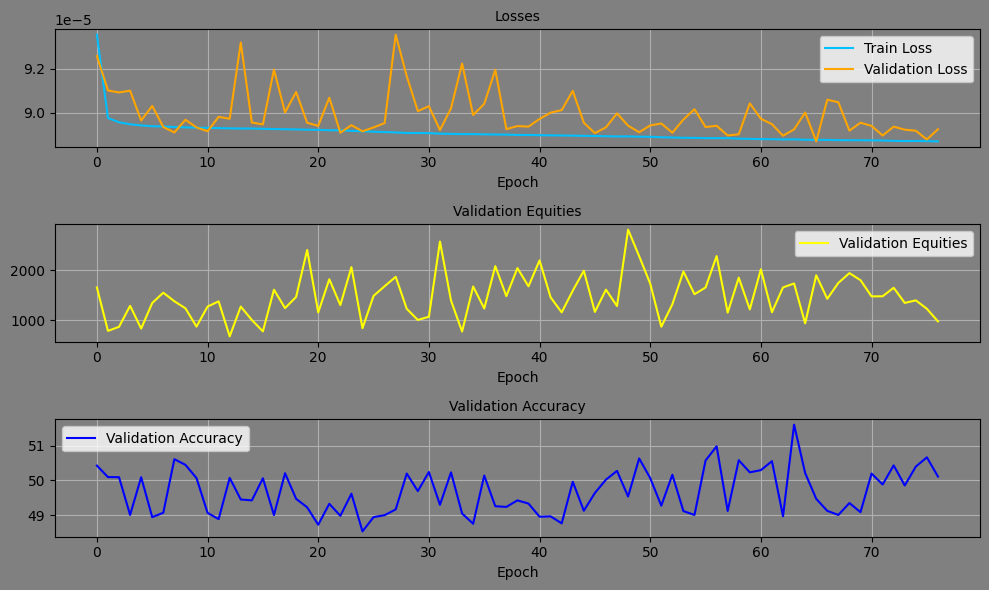

Epoch: 77, Val Equity: 1134.61, Val Accuracy: 50.14 train_losses: 0.00027102640646626614, val_losses: 8.906862058211118e-05, Duration: 0:01:44.778458


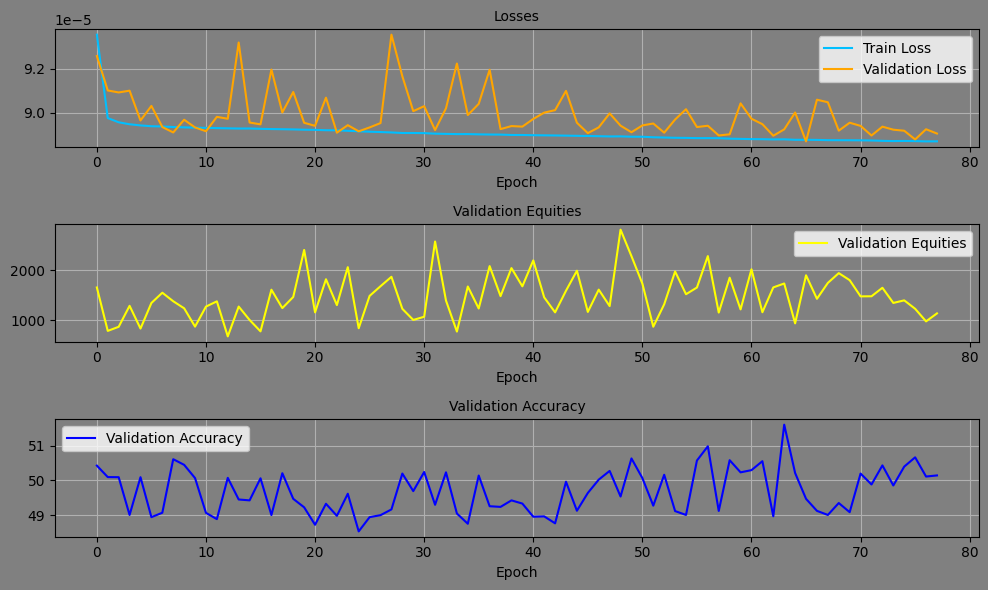

Epoch: 78, Val Equity: 1086.10, Val Accuracy: 48.83 train_losses: 0.00027086761347357803, val_losses: 8.909929601941258e-05, Duration: 0:01:44.874098


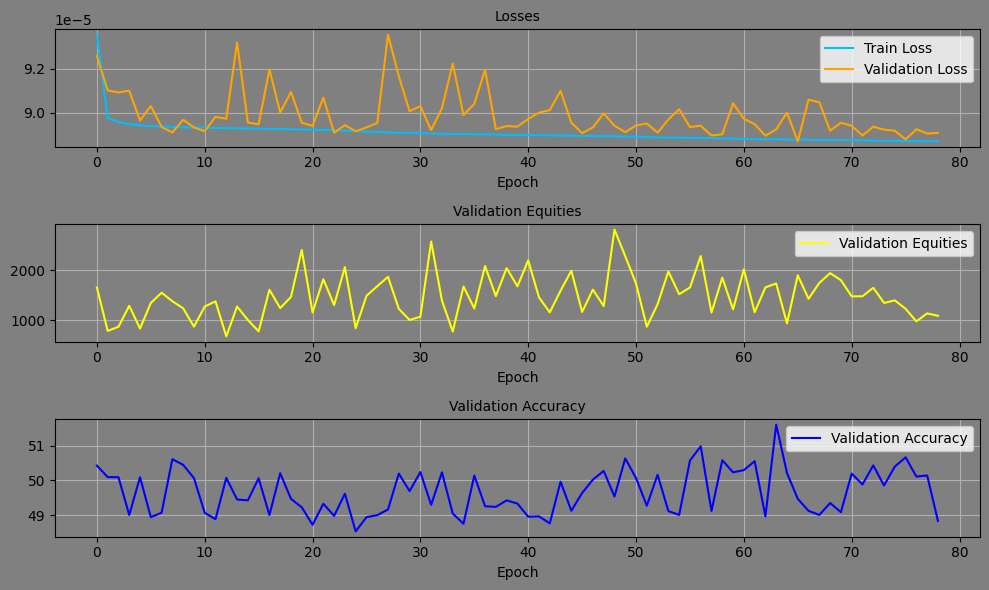

Epoch: 79, Val Equity: 1984.25, Val Accuracy: 50.20 train_losses: 0.00027081751329614405, val_losses: 8.924214489525184e-05, Duration: 0:01:48.199271


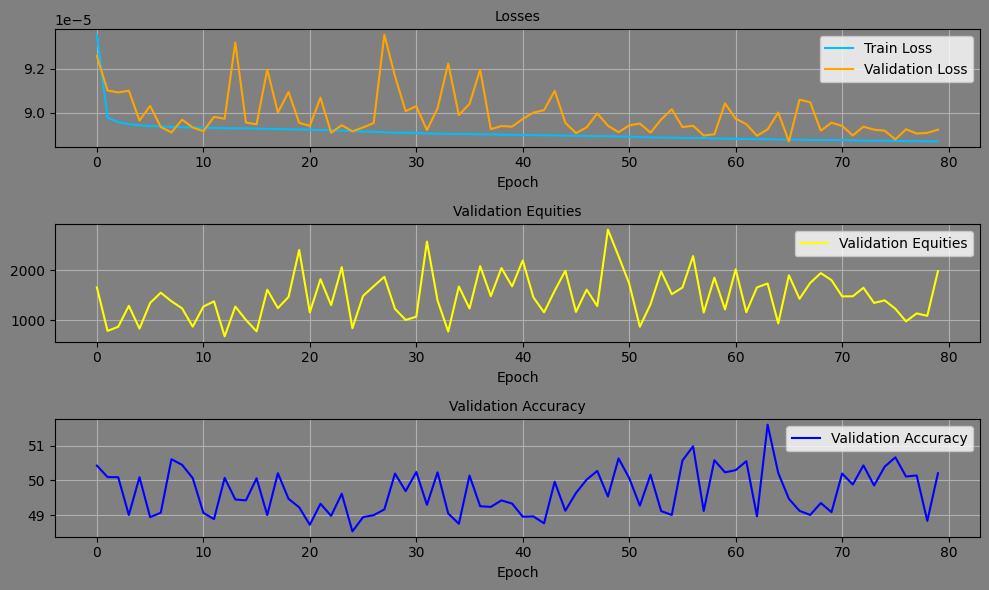

Epoch: 80, Val Equity: 1441.18, Val Accuracy: 49.47 train_losses: 0.00027055165014320946, val_losses: 9.008916822494939e-05, Duration: 0:01:44.522228


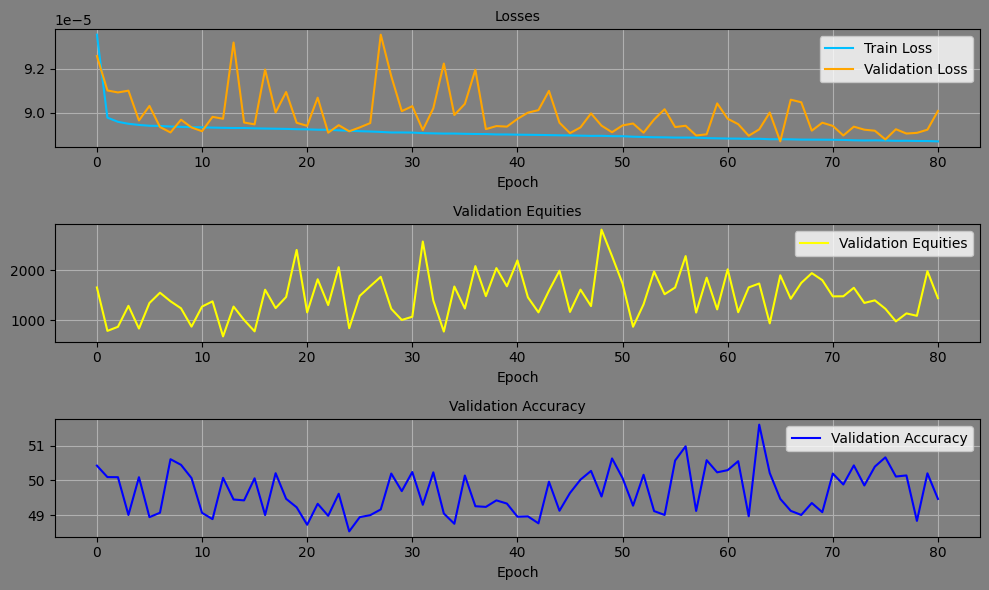

Epoch: 81, Val Equity: 1688.57, Val Accuracy: 50.07 train_losses: 0.000270547314300984, val_losses: 8.991397771751508e-05, Duration: 0:01:45.061251


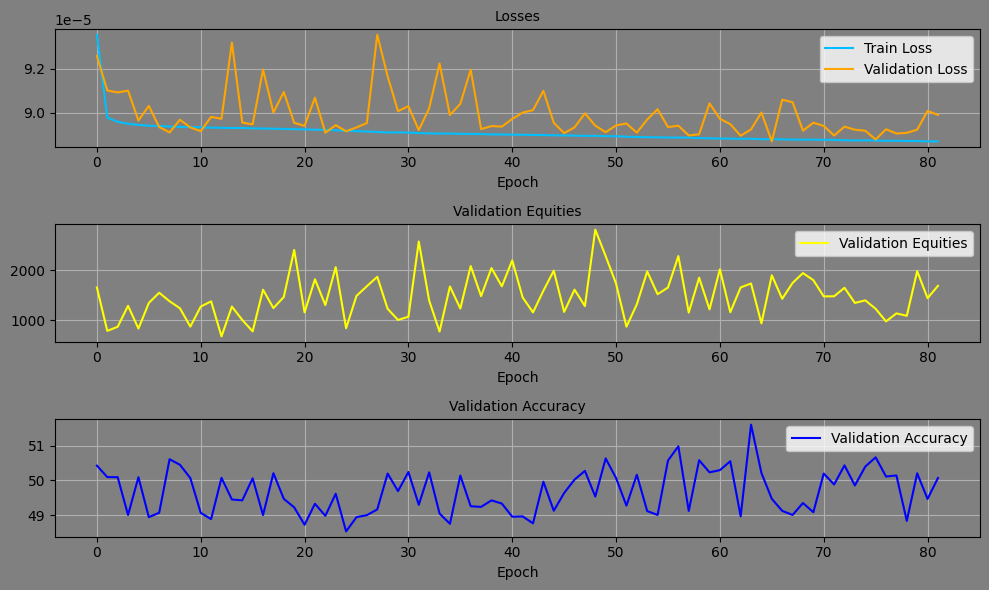

Epoch: 82, Val Equity: 1353.60, Val Accuracy: 50.30 train_losses: 0.00027055631789323336, val_losses: 9.003411832964048e-05, Duration: 0:01:46.085252


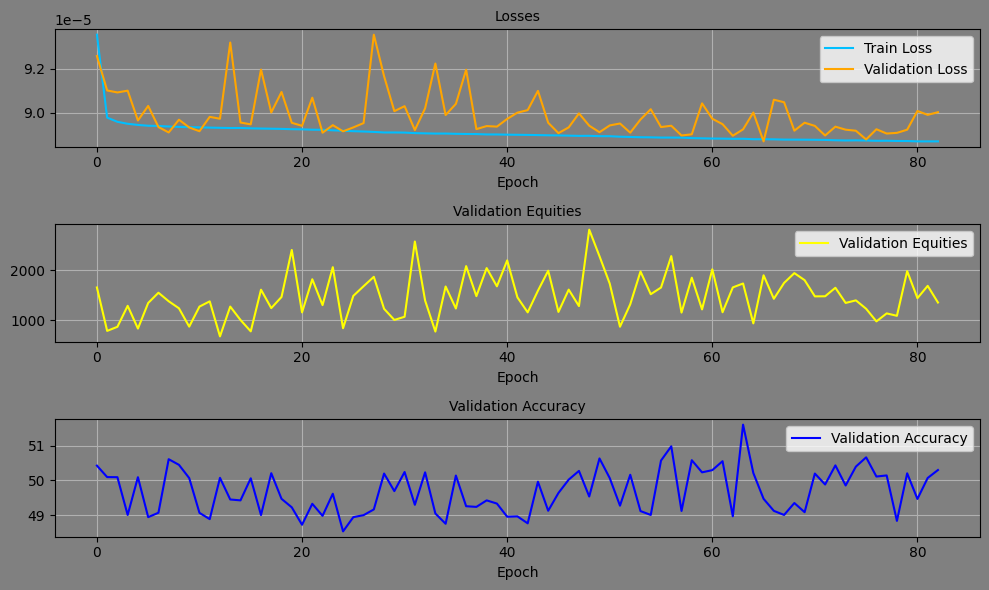

Epoch: 83, Val Equity: 1691.63, Val Accuracy: 49.20 train_losses: 0.00027027283132975217, val_losses: 8.904792775865644e-05, Duration: 0:01:45.165963


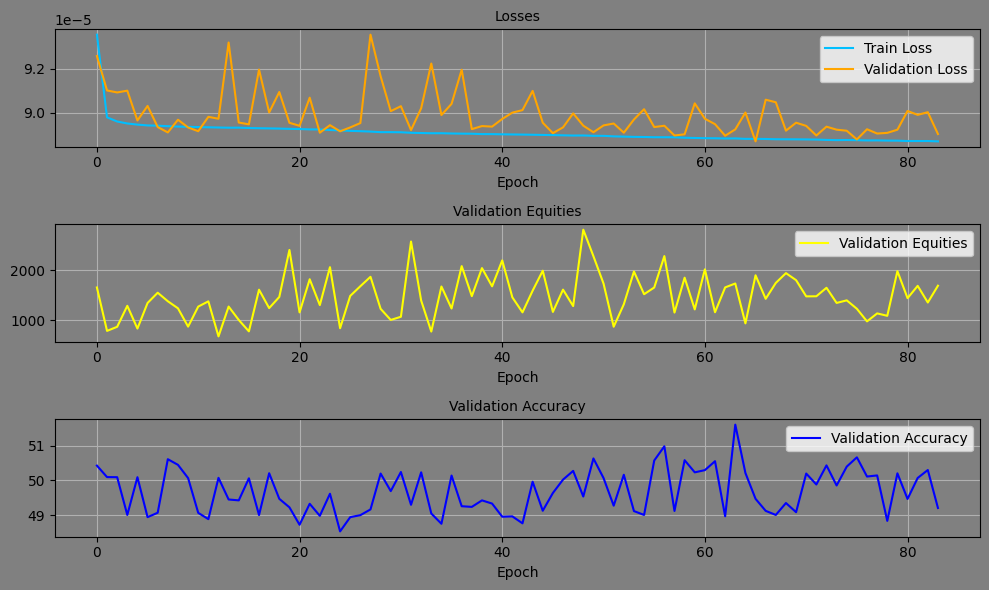

Epoch: 84, Val Equity: 2485.30, Val Accuracy: 51.25 train_losses: 0.0002701930295393695, val_losses: 8.970382623374462e-05, Duration: 0:01:44.014854


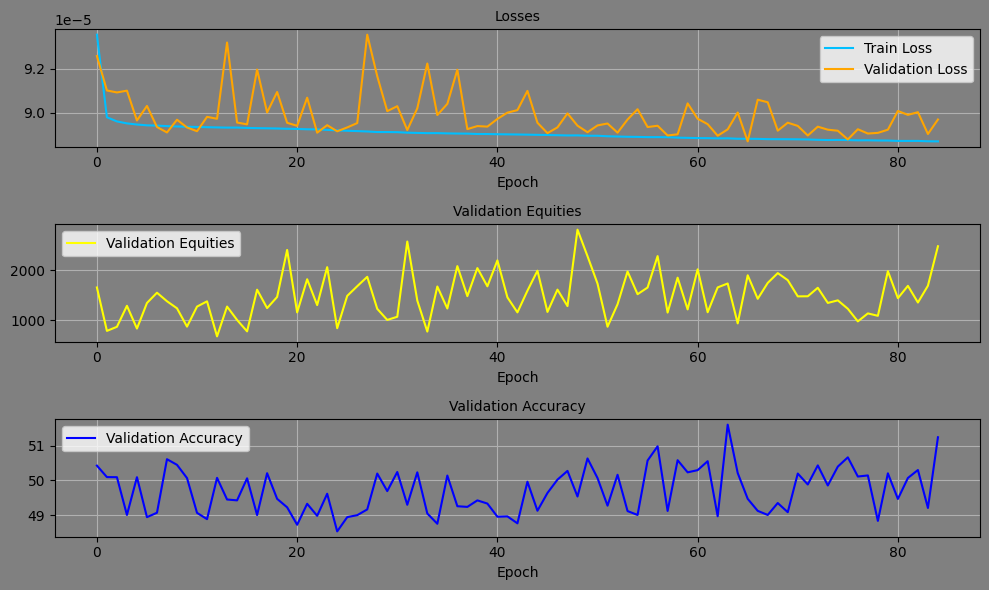

Epoch: 85, Val Equity: 2065.05, Val Accuracy: 50.91 train_losses: 0.0002703555187078963, val_losses: 9.014079842017964e-05, Duration: 0:01:46.328537


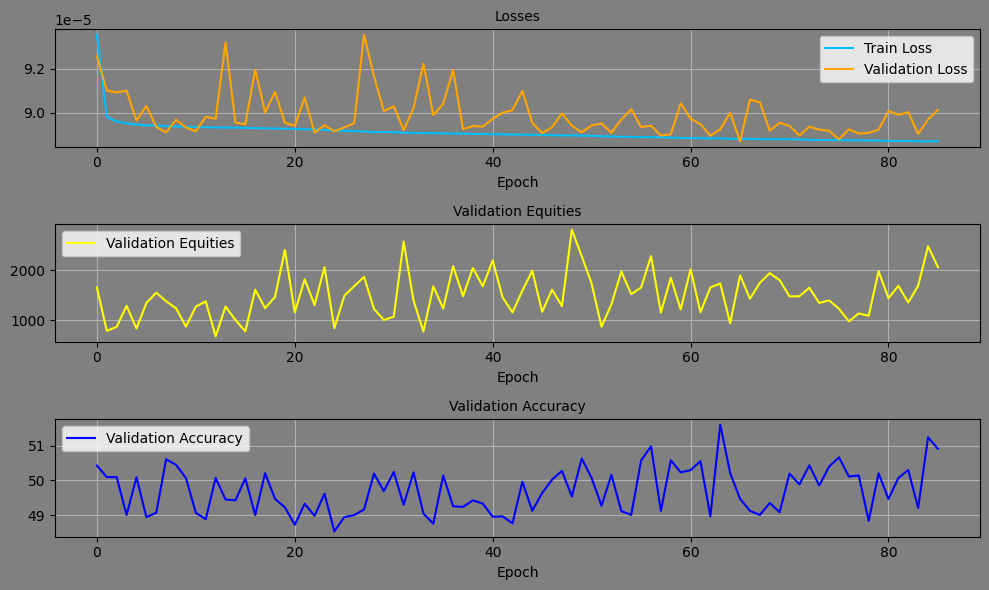

Epoch: 86, Val Equity: 1878.88, Val Accuracy: 50.32 train_losses: 0.0002701518498902371, val_losses: 8.879415690898895e-05, Duration: 0:01:45.034875


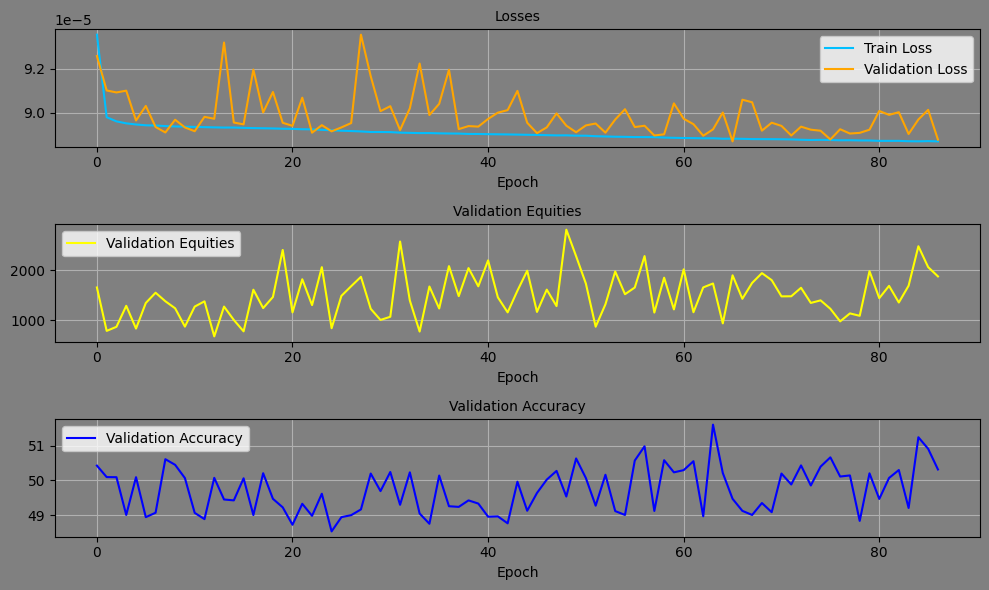

Epoch: 87, Val Equity: 955.71, Val Accuracy: 50.51 train_losses: 0.00026997696305605917, val_losses: 8.935380901675671e-05, Duration: 0:01:45.397148


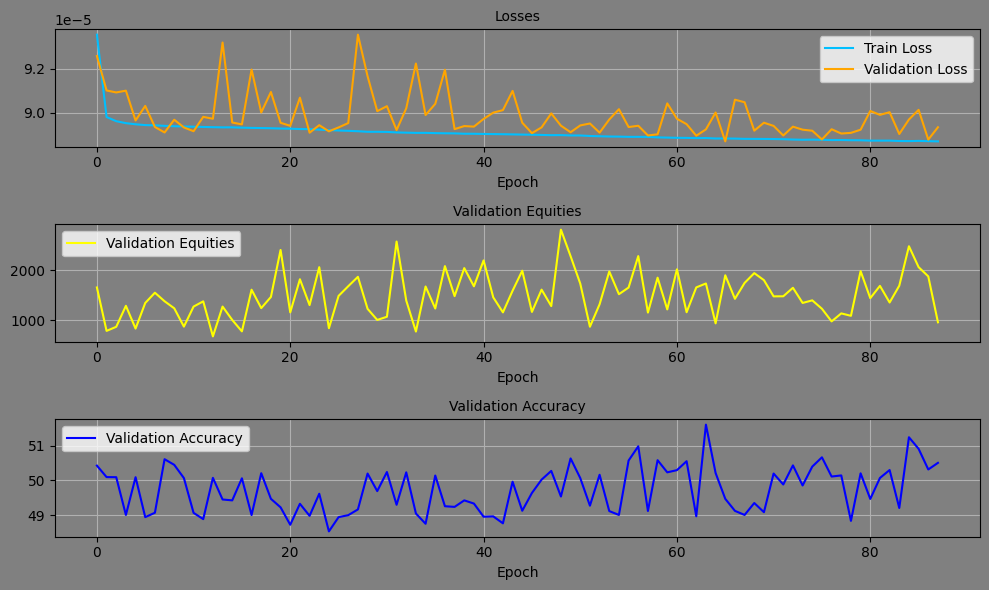

Epoch: 88, Val Equity: 1359.70, Val Accuracy: 49.72 train_losses: 0.00027005481731558255, val_losses: 8.882705878932029e-05, Duration: 0:01:45.427094


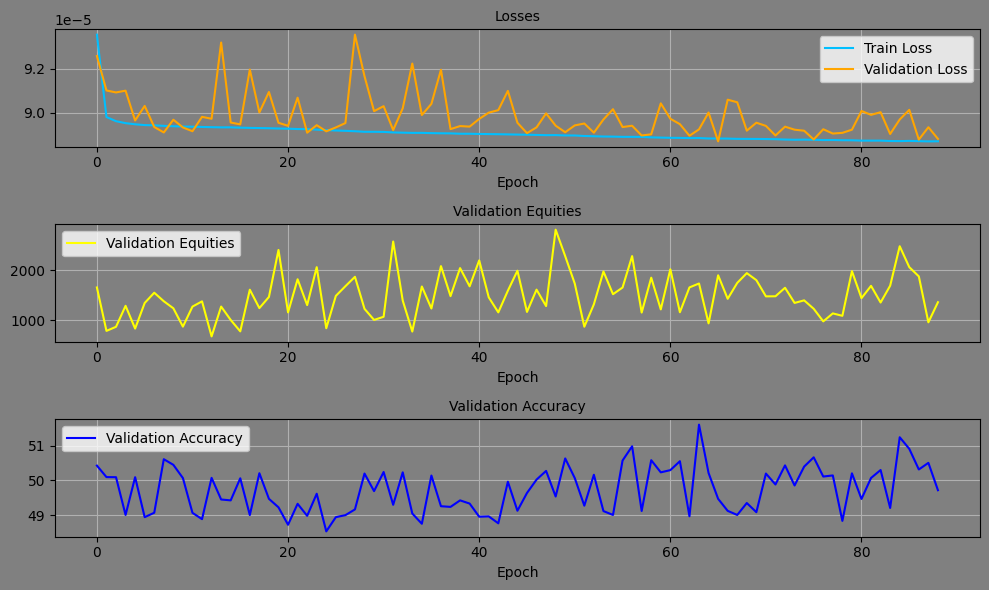

Epoch: 89, Val Equity: 1204.47, Val Accuracy: 48.88 train_losses: 0.00026982703294643805, val_losses: 8.884644194040447e-05, Duration: 0:01:45.073405


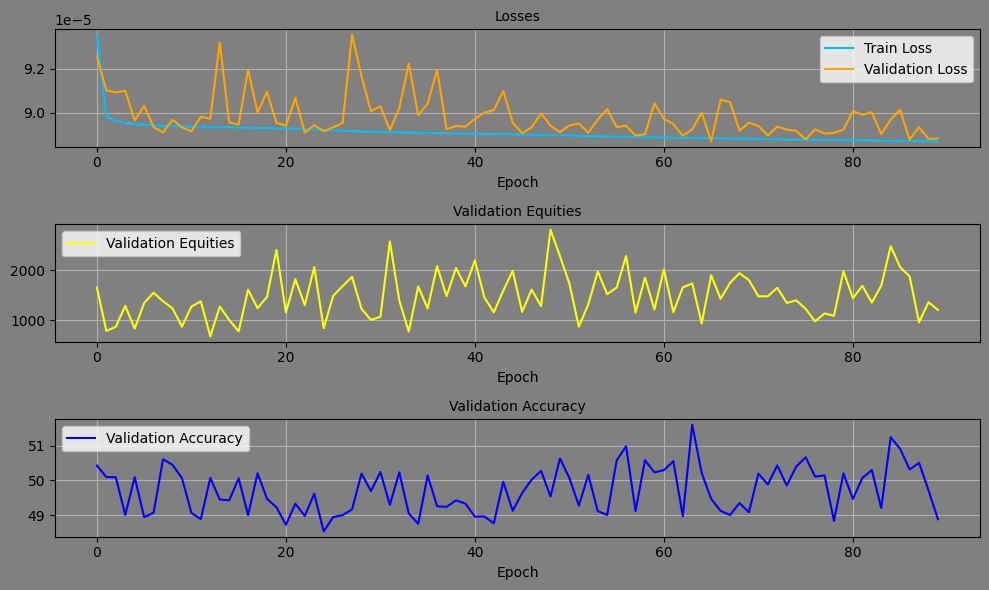

Epoch: 90, Val Equity: 1707.58, Val Accuracy: 49.47 train_losses: 0.000269920268639512, val_losses: 8.978648111224174e-05, Duration: 0:01:45.927414


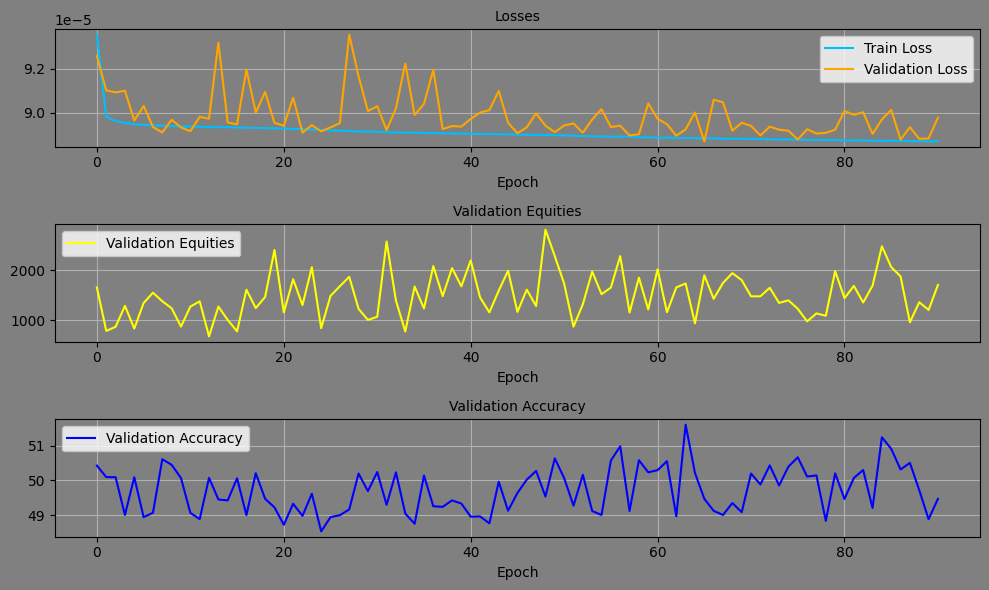

Epoch: 91, Val Equity: 1224.08, Val Accuracy: 50.48 train_losses: 0.00026960857663963417, val_losses: 8.886463183443993e-05, Duration: 0:01:43.543961


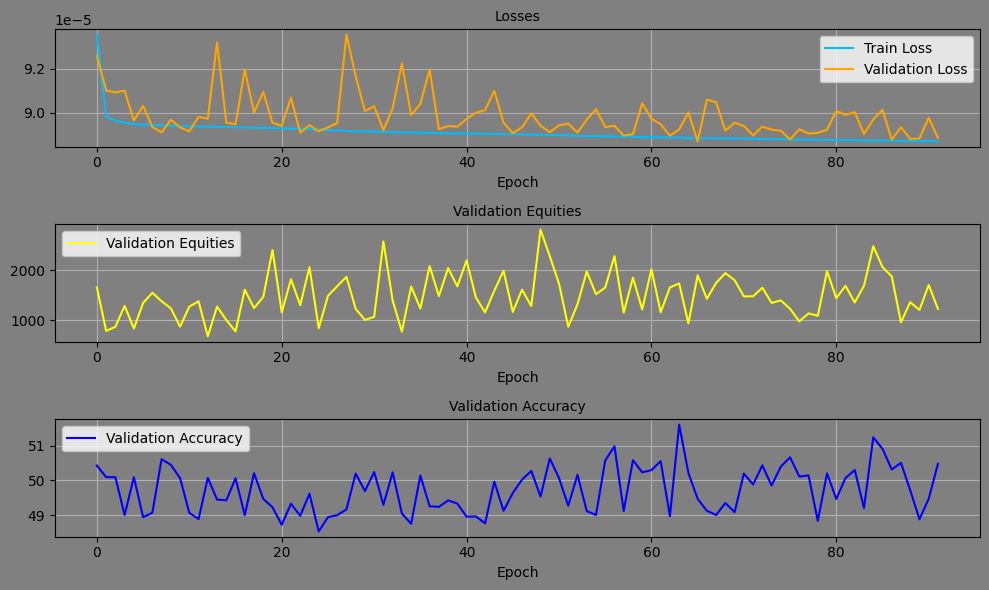

Epoch: 92, Val Equity: 1886.04, Val Accuracy: 50.36 train_losses: 0.0002696349234889471, val_losses: 9.079667506739497e-05, Duration: 0:01:45.429458


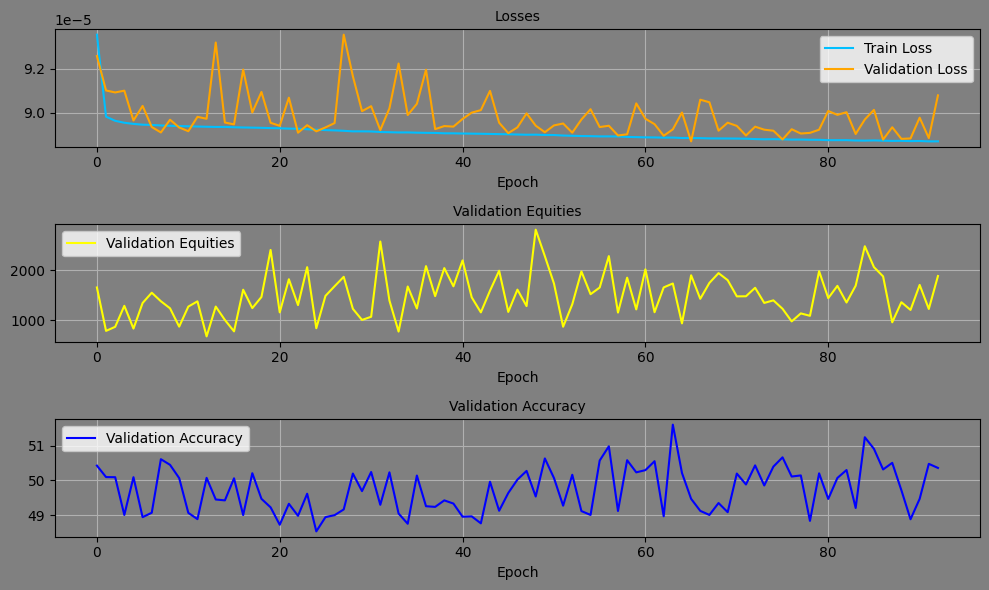

Epoch: 93, Val Equity: 2295.95, Val Accuracy: 50.70 train_losses: 0.000269571246126435, val_losses: 8.871300087776035e-05, Duration: 0:01:45.729235


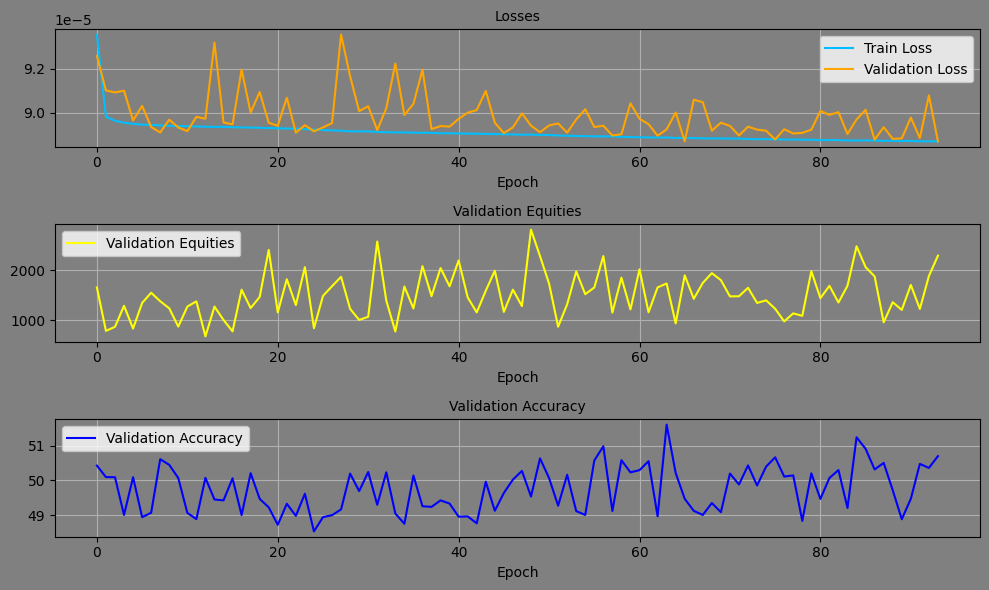

Epoch: 94, Val Equity: 2325.62, Val Accuracy: 51.57 train_losses: 0.0002694247368389724, val_losses: 8.959387196227908e-05, Duration: 0:01:48.252173


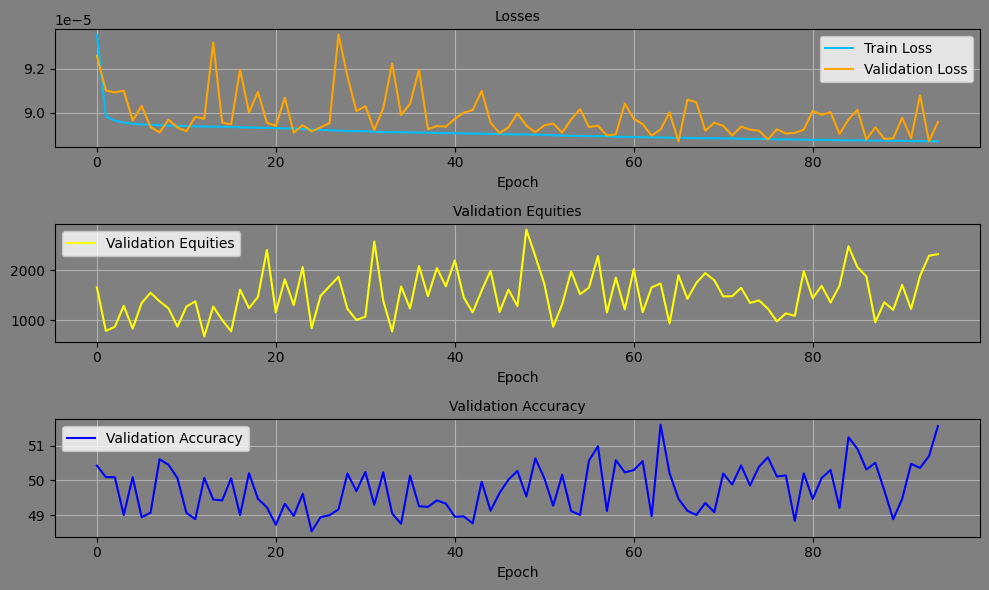

Epoch: 95, Val Equity: 2634.07, Val Accuracy: 51.76 train_losses: 0.0002694233374949533, val_losses: 8.984326268546283e-05, Duration: 0:01:45.934640


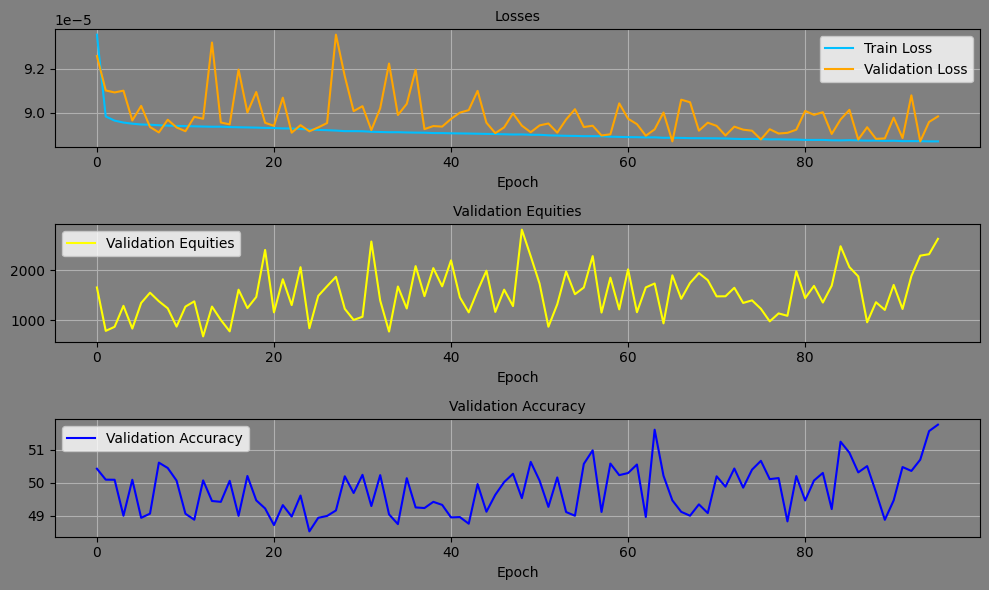

Epoch: 96, Val Equity: 1769.19, Val Accuracy: 50.55 train_losses: 0.0002692827510930151, val_losses: 9.017459524329752e-05, Duration: 0:01:44.244261


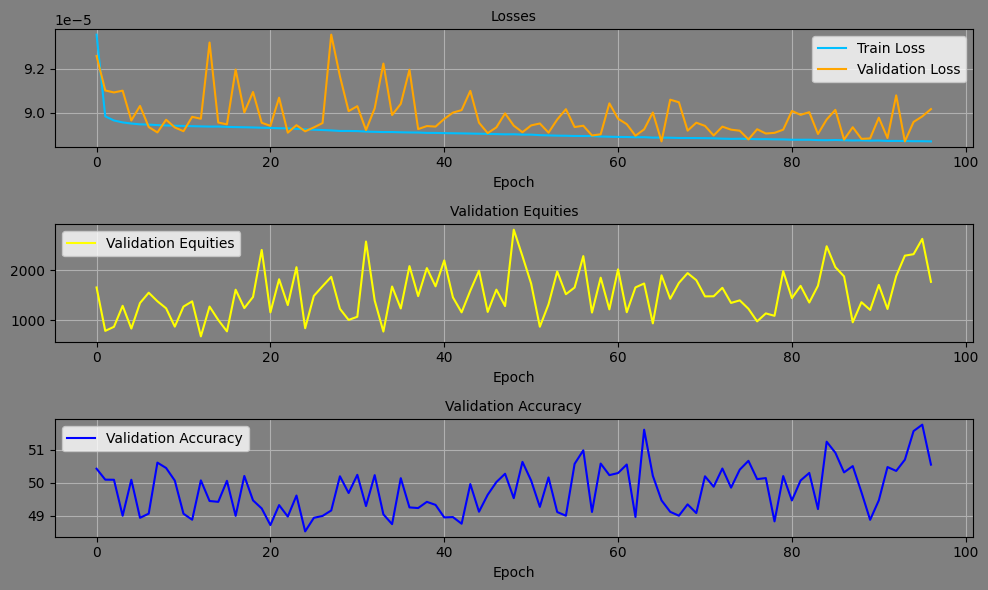

Epoch: 97, Val Equity: 1560.65, Val Accuracy: 49.54 train_losses: 0.00026915525476132963, val_losses: 8.901231922209263e-05, Duration: 0:01:45.413715


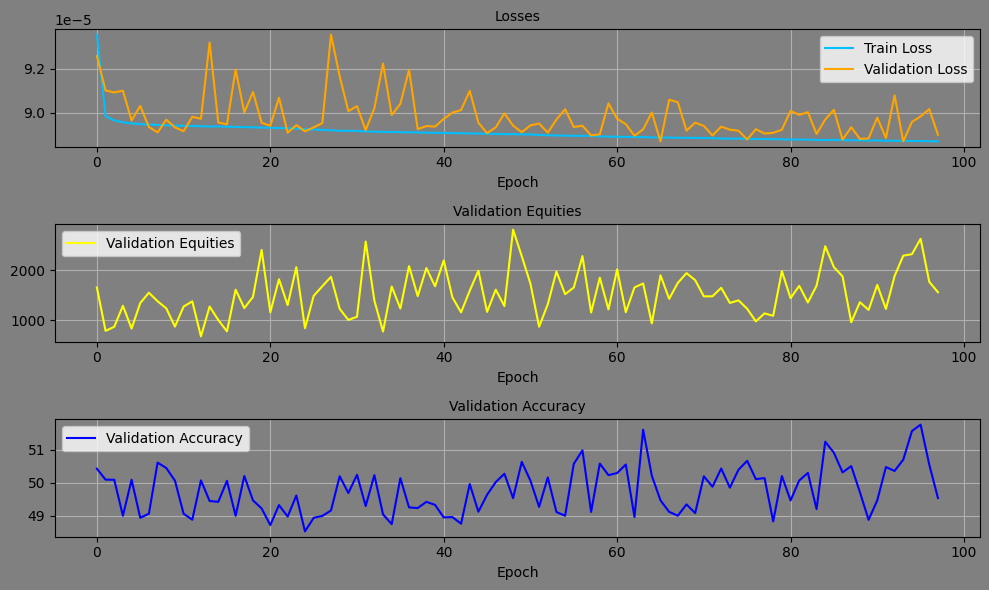

Epoch: 98, Val Equity: 2073.70, Val Accuracy: 50.09 train_losses: 0.00026914455248392024, val_losses: 8.90285664354451e-05, Duration: 0:01:45.256273


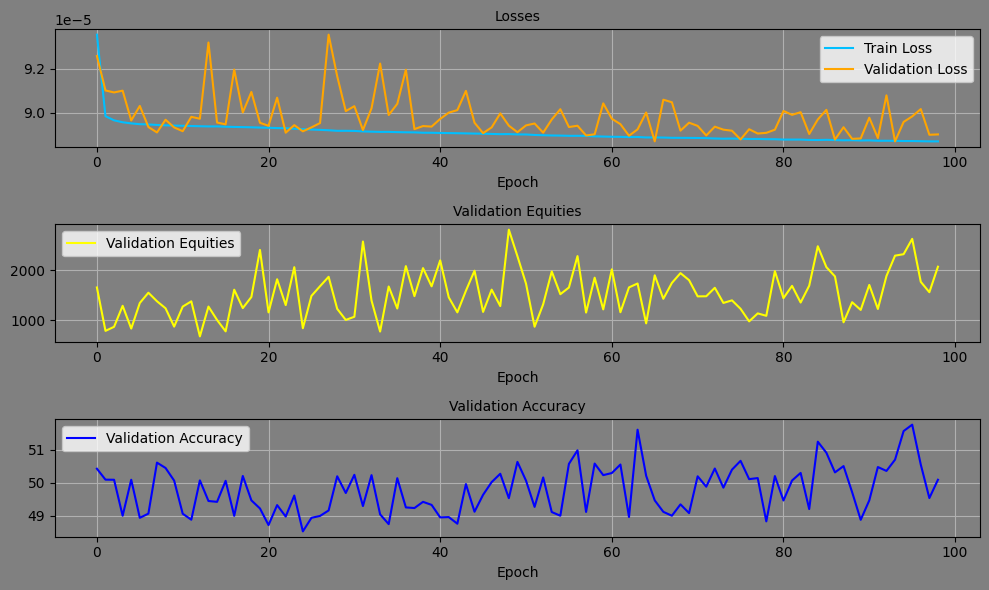

Epoch: 99, Val Equity: 1226.57, Val Accuracy: 50.10 train_losses: 0.00026910365127511194, val_losses: 8.936382801039144e-05, Duration: 0:01:45.715784


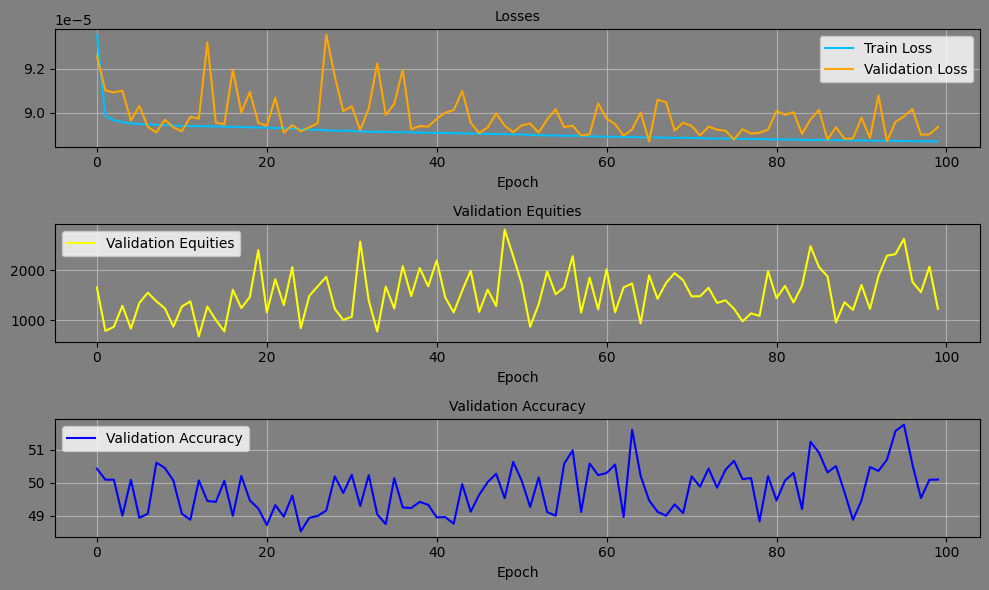

Epoch: 100, Val Equity: 1813.71, Val Accuracy: 49.27 train_losses: 0.0002689774849236861, val_losses: 8.89391012606211e-05, Duration: 0:01:47.586936


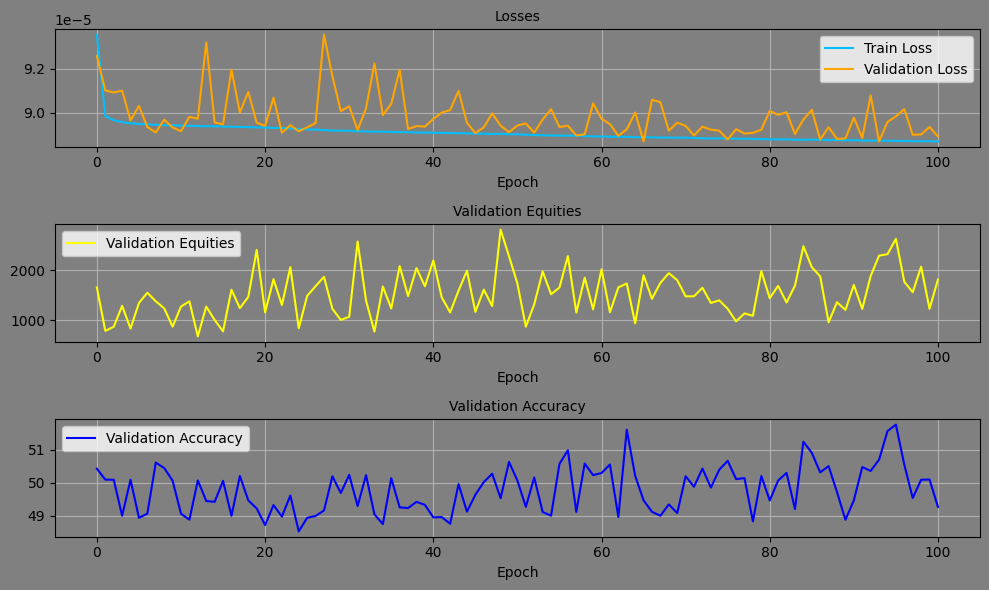

Epoch: 101, Val Equity: 1142.81, Val Accuracy: 50.22 train_losses: 0.000268746067172195, val_losses: 8.89318689587526e-05, Duration: 0:01:46.450445


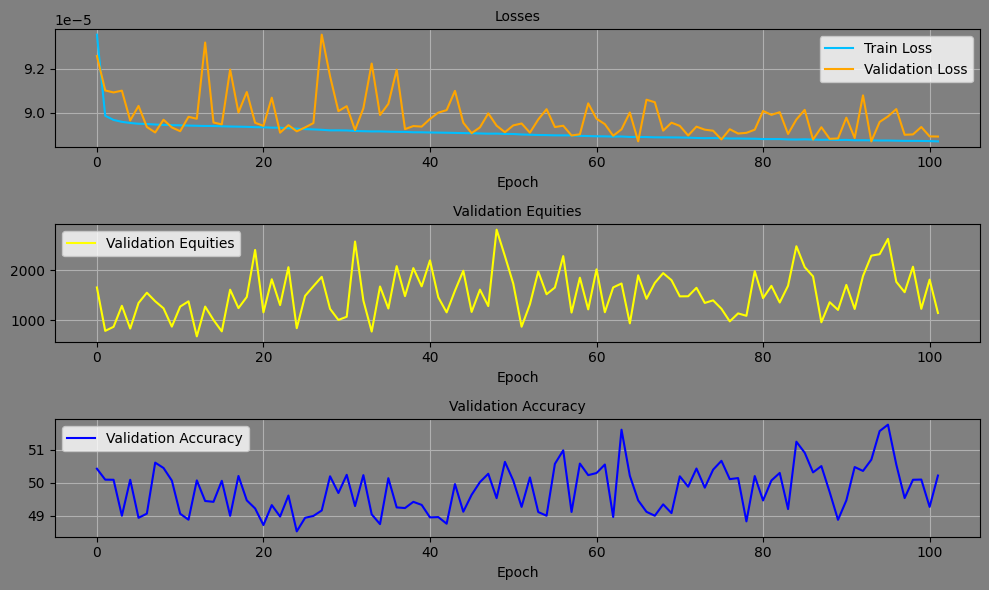

Epoch: 102, Val Equity: 1374.04, Val Accuracy: 48.90 train_losses: 0.00026879151164255346, val_losses: 8.972454816102982e-05, Duration: 0:01:46.395127


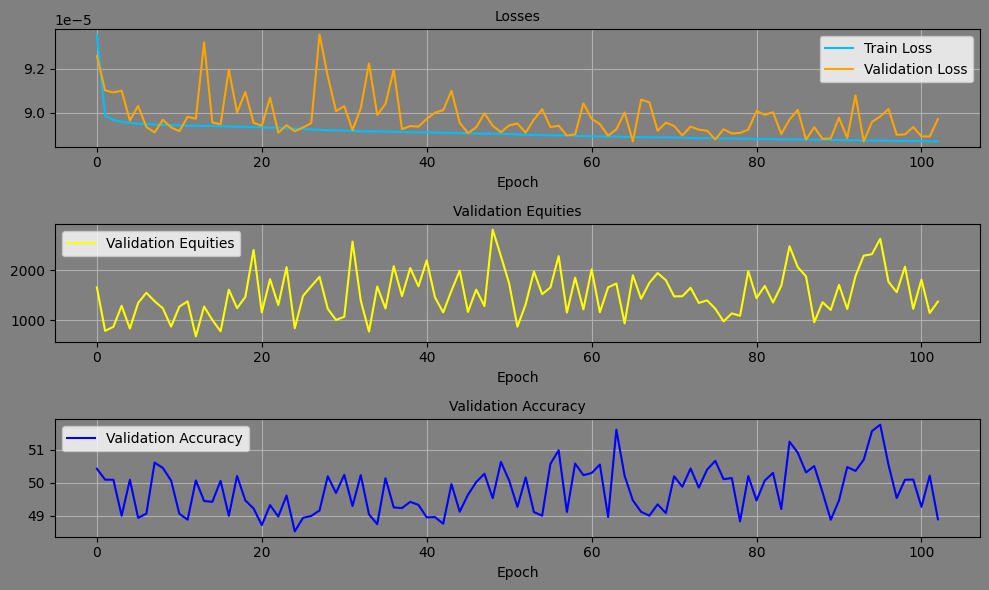

Epoch: 103, Val Equity: 1865.55, Val Accuracy: 49.64 train_losses: 0.00026858560217285813, val_losses: 8.918453386286274e-05, Duration: 0:01:45.109046


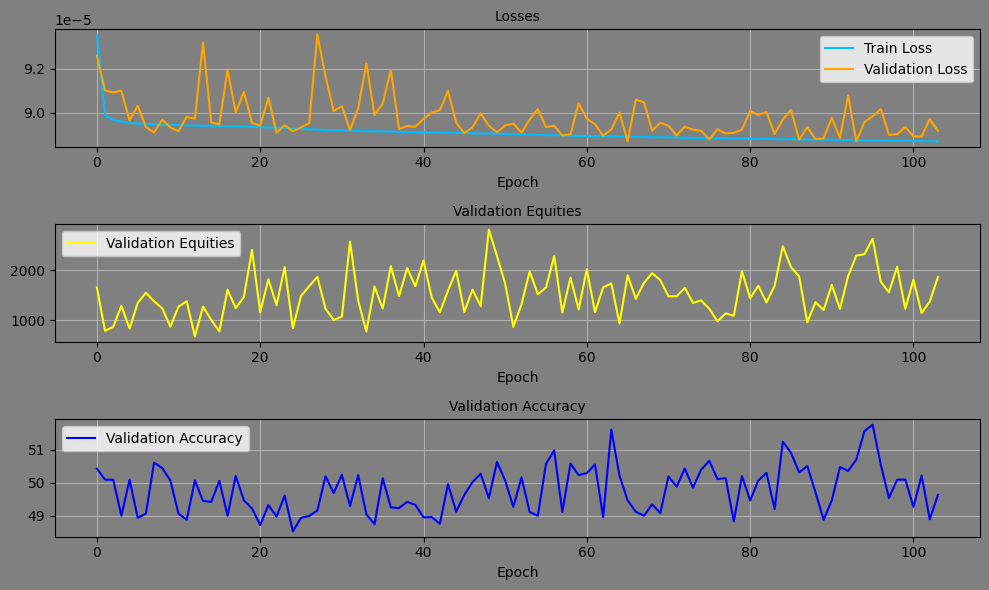

Epoch: 104, Val Equity: 1630.29, Val Accuracy: 50.48 train_losses: 0.0002686151418754157, val_losses: 8.964959852164611e-05, Duration: 0:01:46.818338


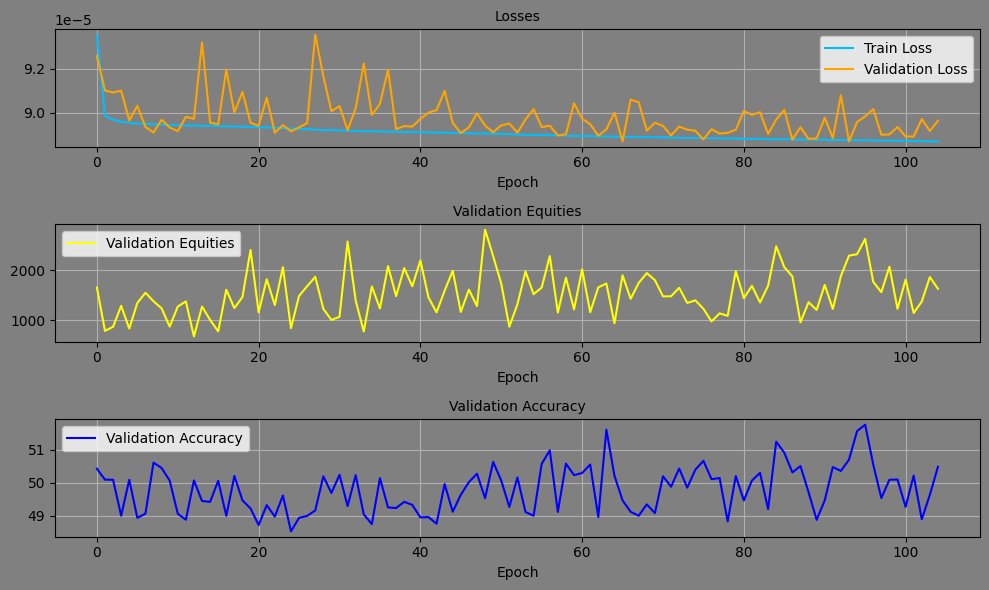

Epoch: 105, Val Equity: 1565.26, Val Accuracy: 49.21 train_losses: 0.0002684829601796407, val_losses: 8.924116991693154e-05, Duration: 0:01:45.293016


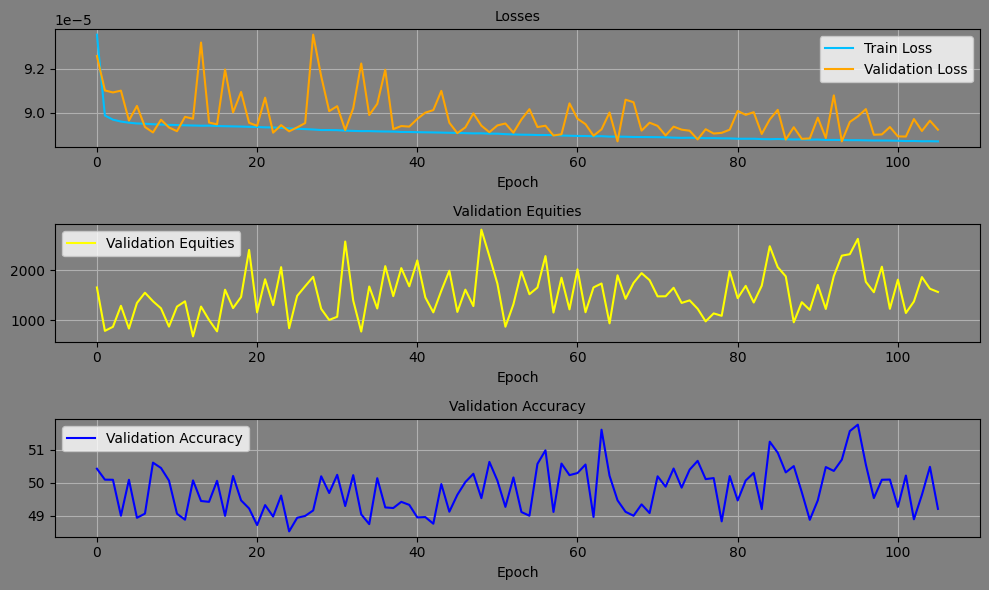

Epoch: 106, Val Equity: 1448.38, Val Accuracy: 49.20 train_losses: 0.00026847640885961947, val_losses: 8.929044270189479e-05, Duration: 0:01:44.910430


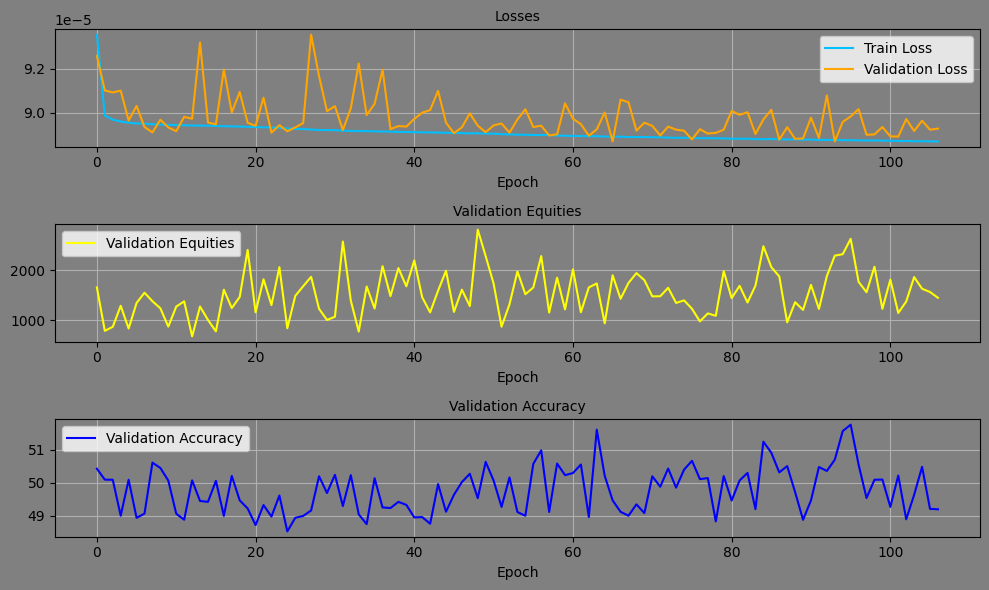

Epoch: 107, Val Equity: 1056.86, Val Accuracy: 50.22 train_losses: 0.0002683822550626076, val_losses: 8.967550820671022e-05, Duration: 0:01:44.623940


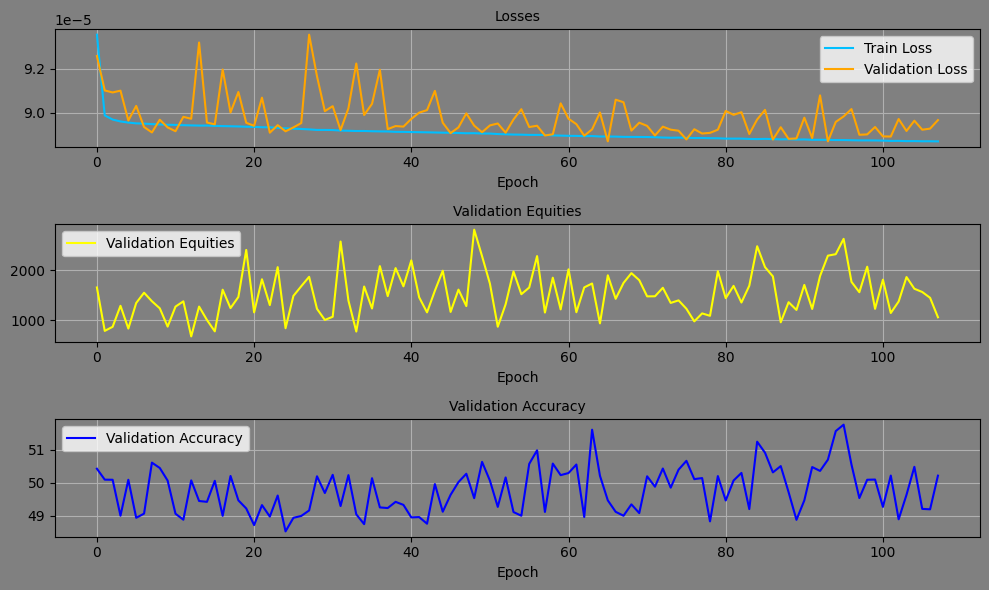

Epoch: 108, Val Equity: 1309.04, Val Accuracy: 50.29 train_losses: 0.0002681506099452975, val_losses: 8.928871102398261e-05, Duration: 0:01:44.936616


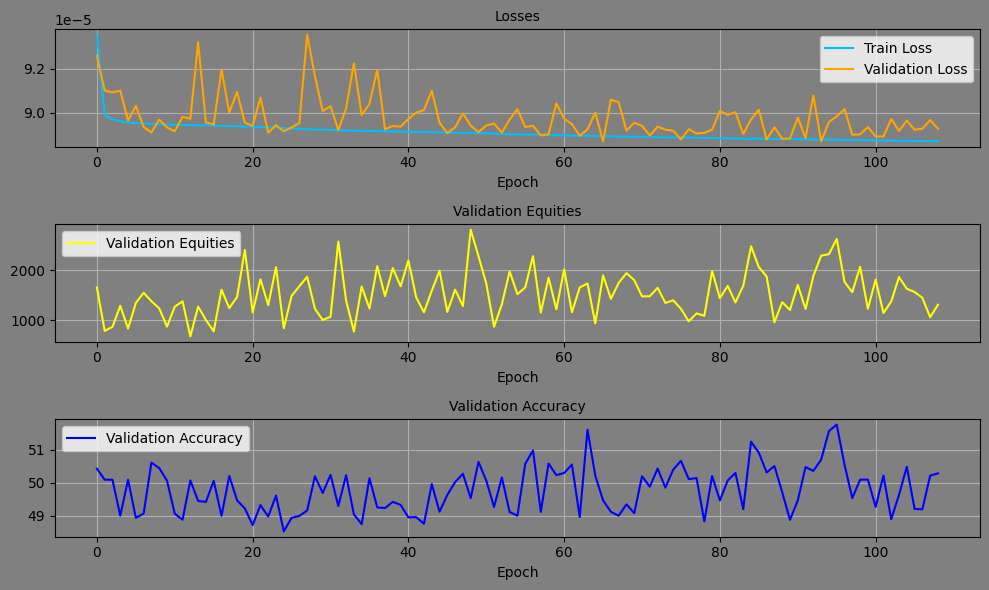

Epoch: 109, Val Equity: 1579.79, Val Accuracy: 49.60 train_losses: 0.0002681495248561913, val_losses: 8.973230433184654e-05, Duration: 0:01:44.685188


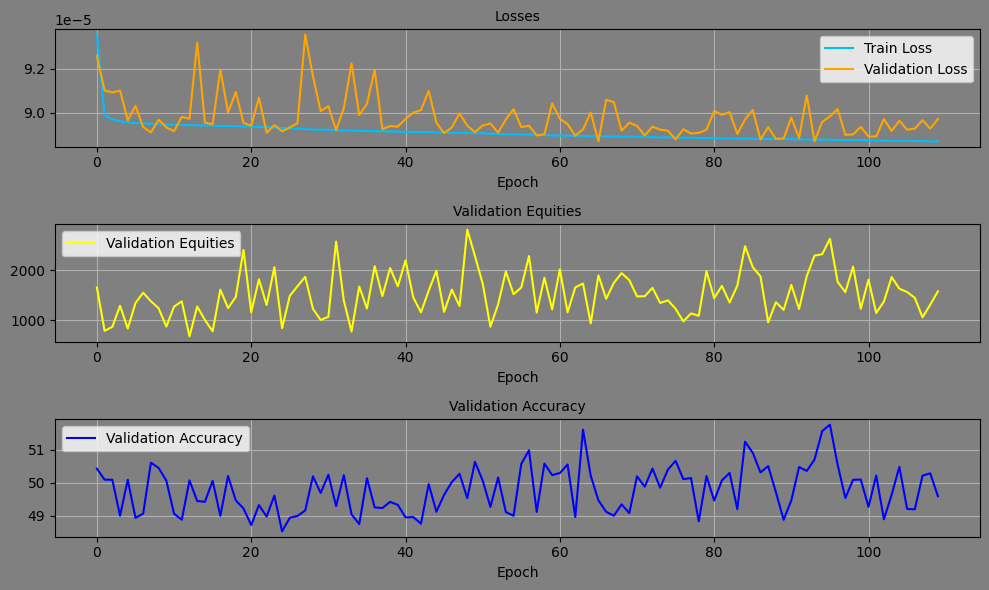

Epoch: 110, Val Equity: 1897.84, Val Accuracy: 50.40 train_losses: 0.00026792886776446, val_losses: 9.199706983054057e-05, Duration: 0:01:44.763740


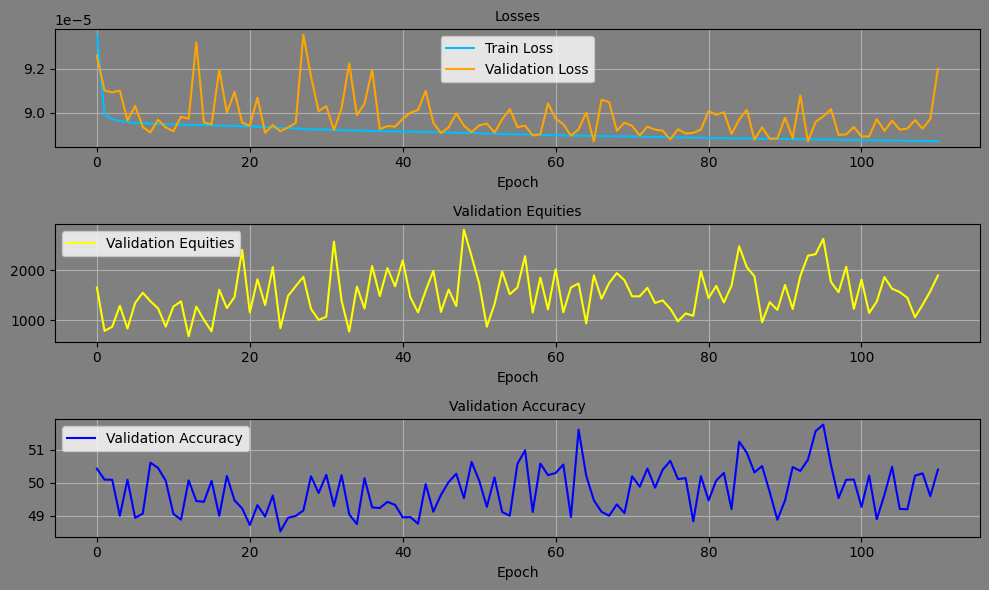

Epoch: 111, Val Equity: 1064.43, Val Accuracy: 50.21 train_losses: 0.00026798961912631266, val_losses: 9.013902308652177e-05, Duration: 0:01:44.489503


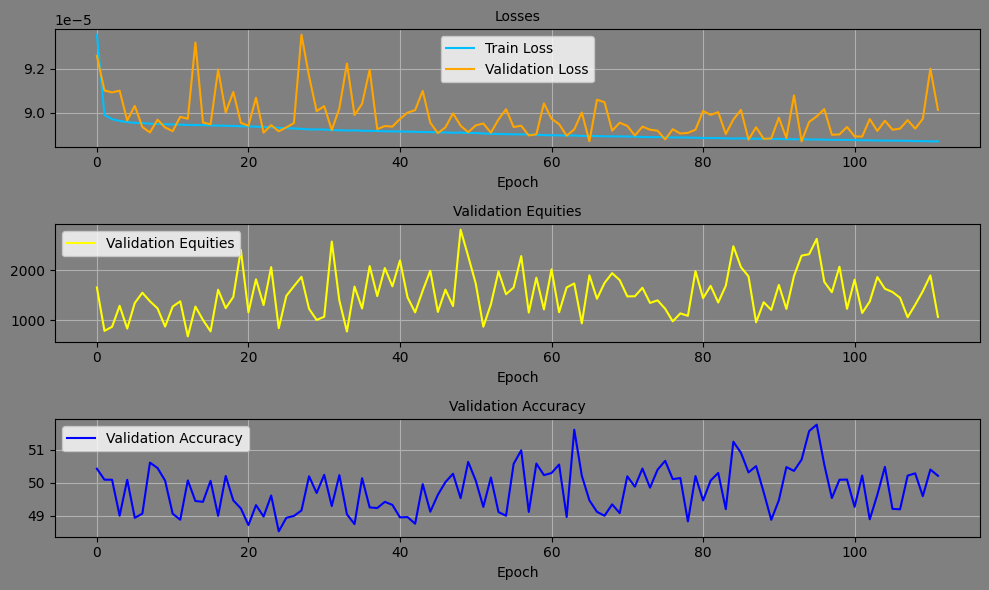

Epoch: 112, Val Equity: 1095.69, Val Accuracy: 50.18 train_losses: 0.0002678033308212634, val_losses: 8.96608762559481e-05, Duration: 0:01:45.046066


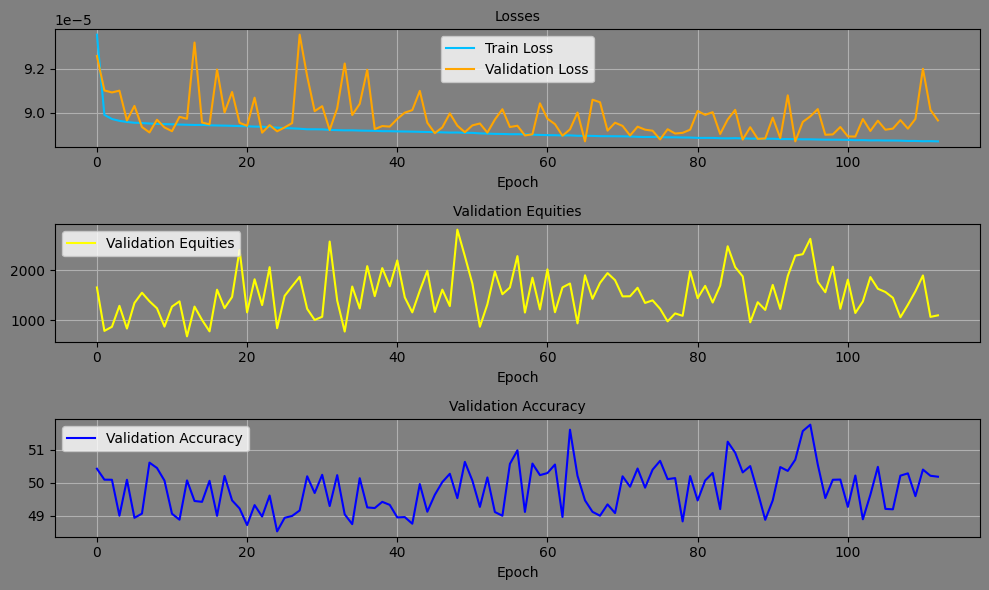

Epoch: 113, Val Equity: 808.35, Val Accuracy: 50.16 train_losses: 0.0002678625106215612, val_losses: 9.034327376866713e-05, Duration: 0:01:46.472613


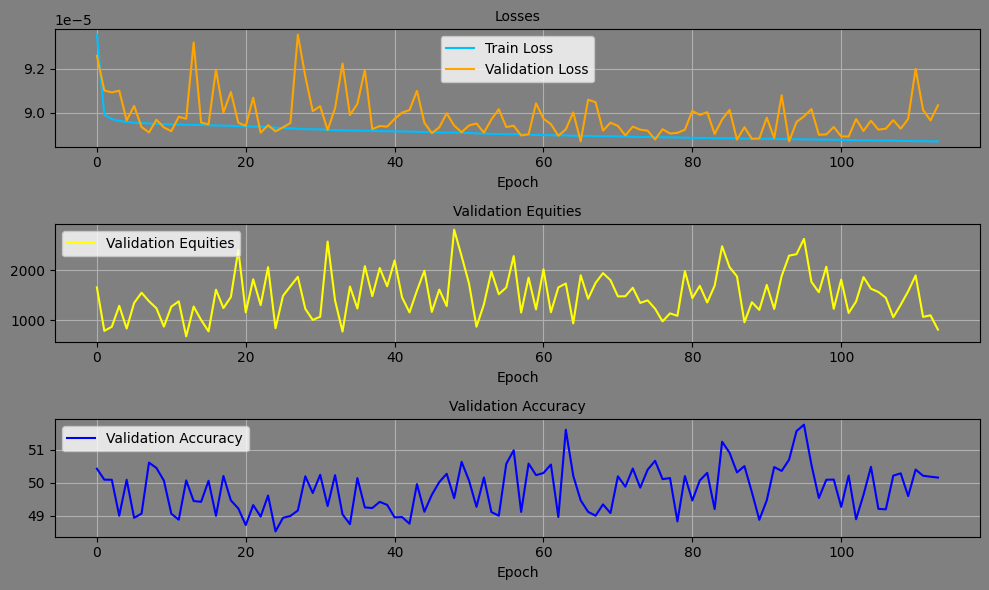

Epoch: 114, Val Equity: 1505.35, Val Accuracy: 49.55 train_losses: 0.00026773329803917497, val_losses: 8.89633156475611e-05, Duration: 0:01:45.219837


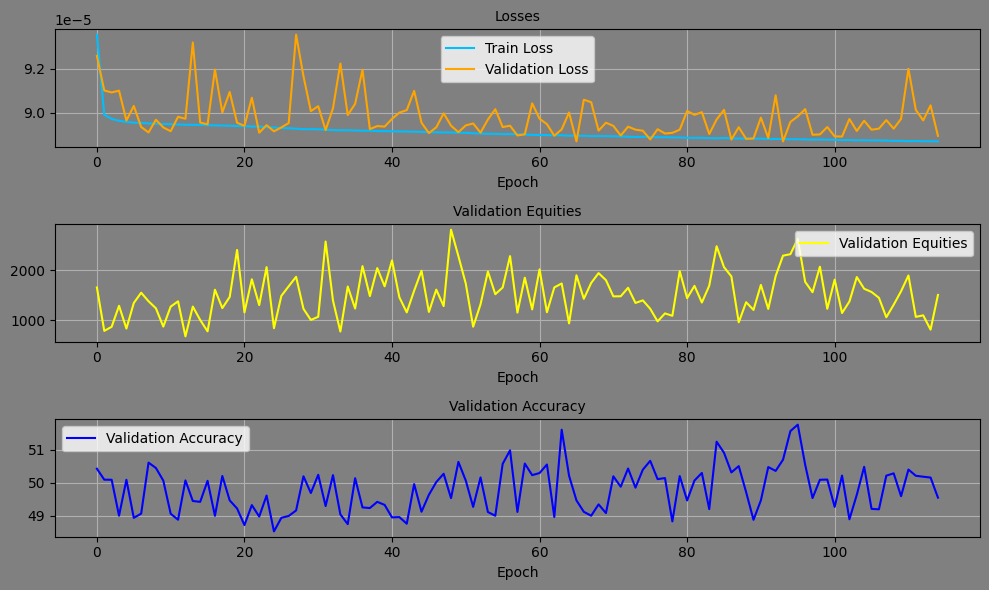

Epoch: 115, Val Equity: 2890.21, Val Accuracy: 50.11 train_losses: 0.0002677898571951895, val_losses: 8.896113286027685e-05, Duration: 0:01:44.889613


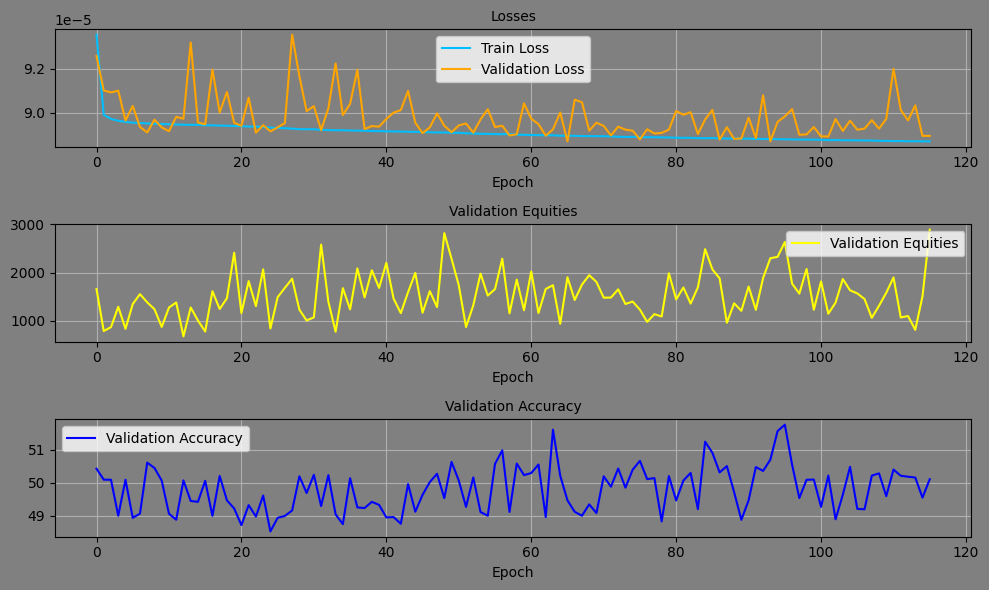

Epoch: 116, Val Equity: 1397.37, Val Accuracy: 50.74 train_losses: 0.00026758361429771193, val_losses: 9.082671749638394e-05, Duration: 0:01:46.041841


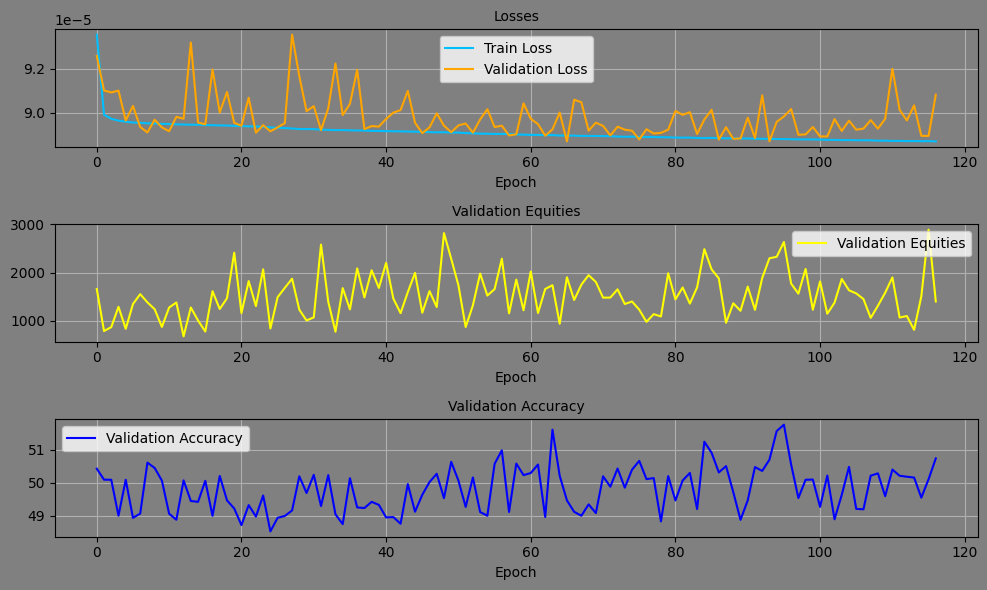

Epoch: 117, Val Equity: 1354.37, Val Accuracy: 48.99 train_losses: 0.0002675318408441262, val_losses: 8.922164124669507e-05, Duration: 0:01:47.808783


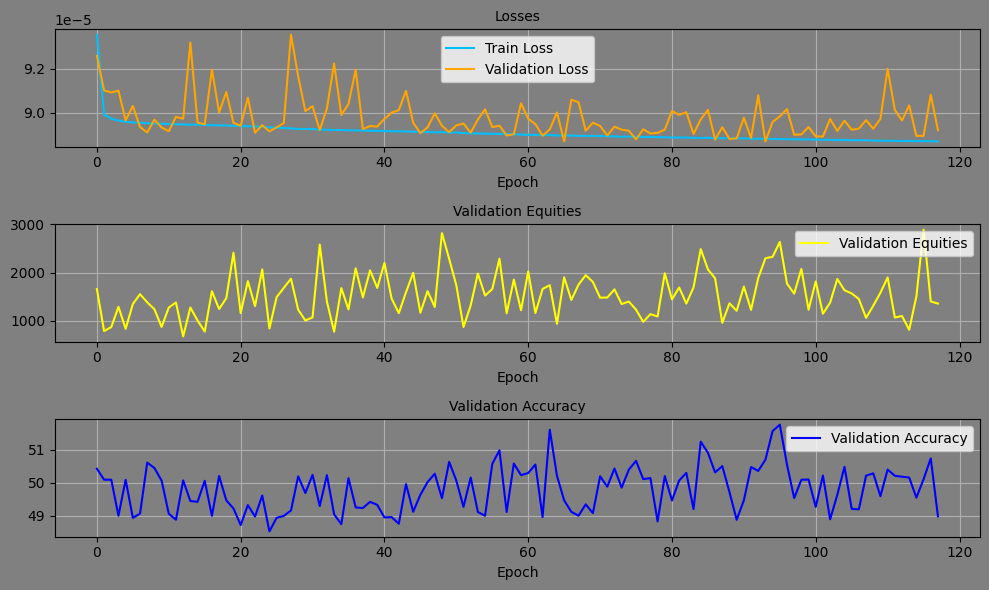

Epoch: 118, Val Equity: 1248.54, Val Accuracy: 50.34 train_losses: 0.0002674302076224105, val_losses: 8.930242620408535e-05, Duration: 0:01:45.938357


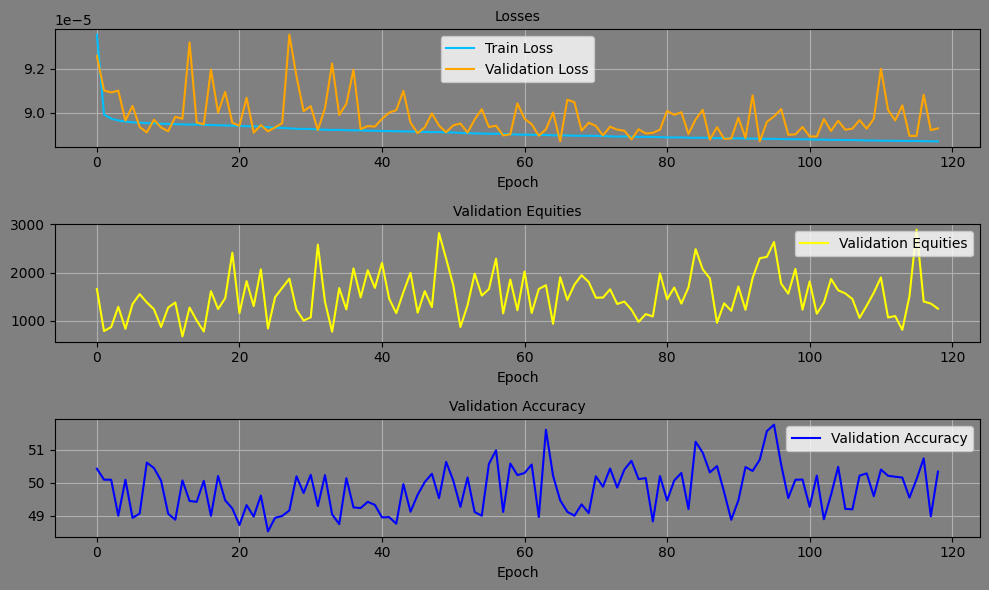

Epoch: 119, Val Equity: 1038.79, Val Accuracy: 49.34 train_losses: 0.0002672331614942267, val_losses: 8.912758494261652e-05, Duration: 0:01:45.834335


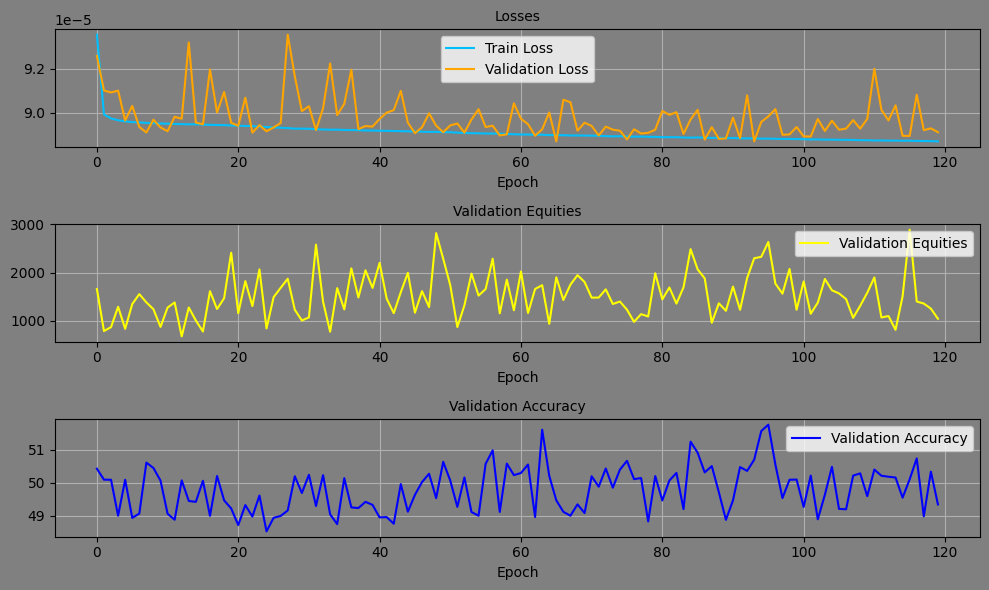

Epoch: 120, Val Equity: 1308.73, Val Accuracy: 50.47 train_losses: 0.00026732871027680016, val_losses: 8.976402023108676e-05, Duration: 0:01:45.258855


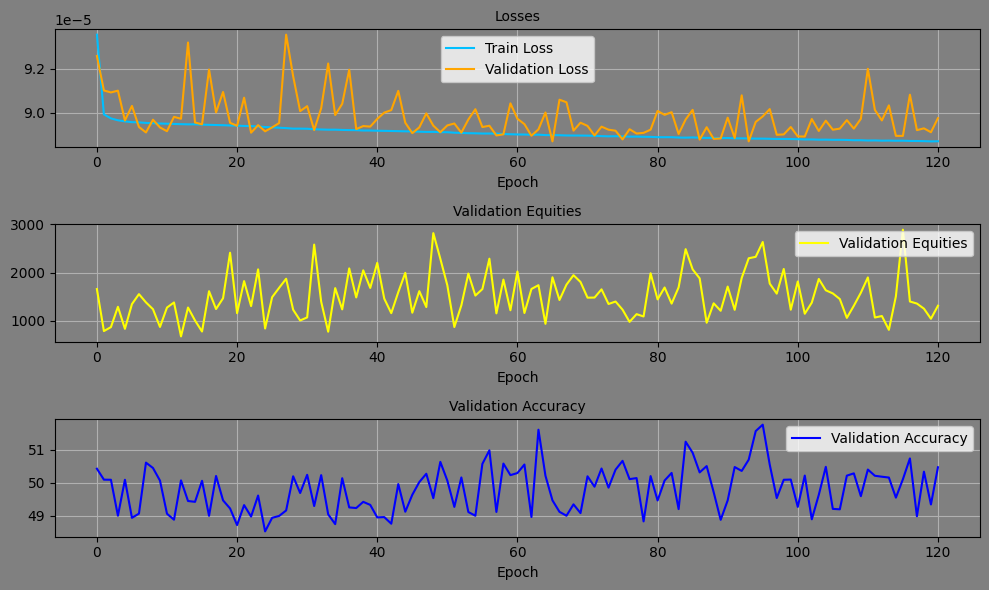

Epoch: 121, Val Equity: 2243.07, Val Accuracy: 50.83 train_losses: 0.00026746535867435865, val_losses: 8.867312863003463e-05, Duration: 0:01:45.180942


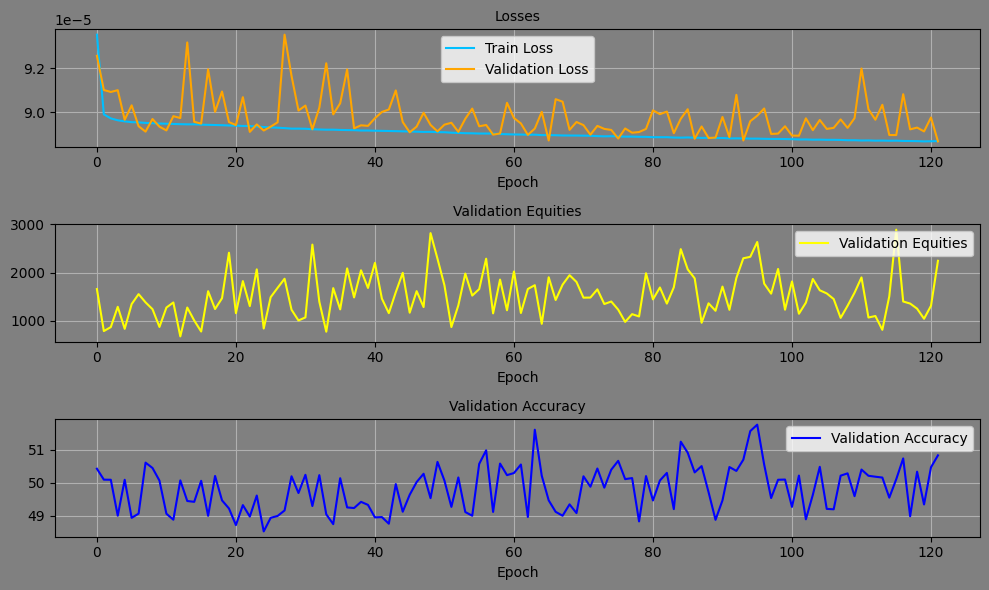

Epoch: 122, Val Equity: 2254.38, Val Accuracy: 50.92 train_losses: 0.0002671093970434413, val_losses: 8.91866729944013e-05, Duration: 0:01:45.986809


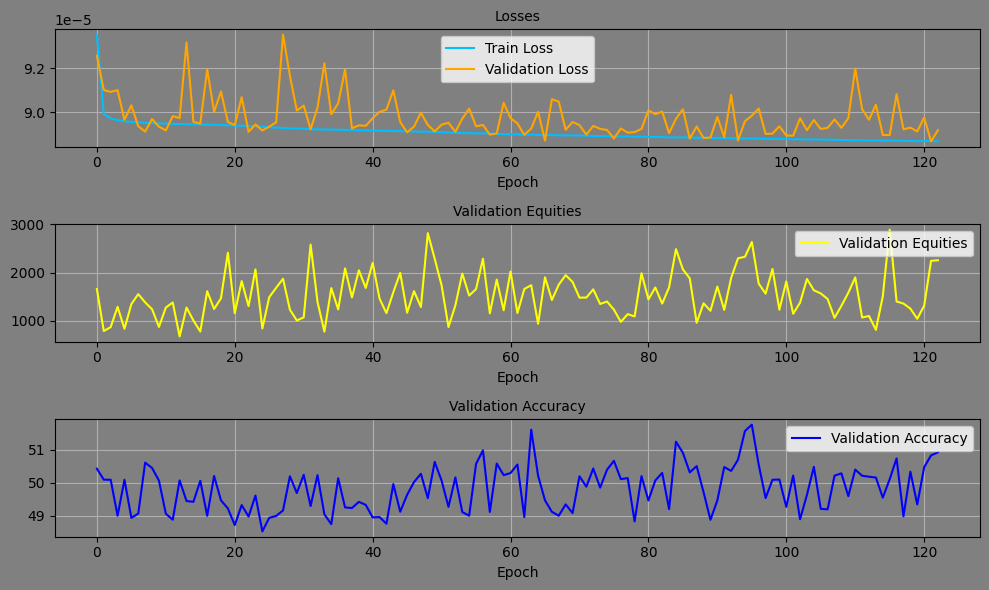

Epoch: 123, Val Equity: 1373.77, Val Accuracy: 50.32 train_losses: 0.00026709505685747035, val_losses: 8.962498395703733e-05, Duration: 0:01:46.679656


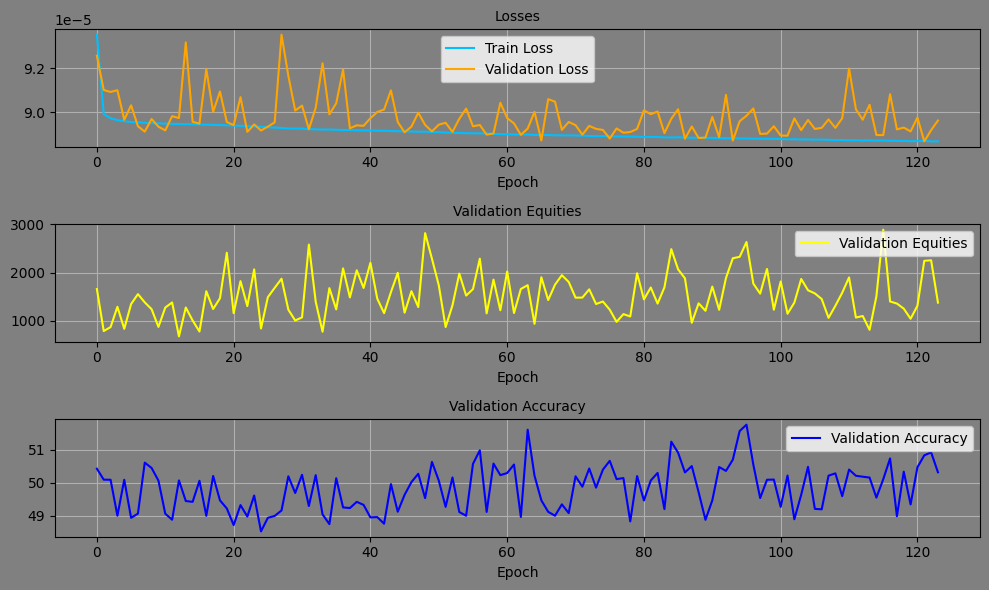

Epoch: 124, Val Equity: 1416.59, Val Accuracy: 49.00 train_losses: 0.00026706909811653577, val_losses: 8.92796233529225e-05, Duration: 0:01:44.732800


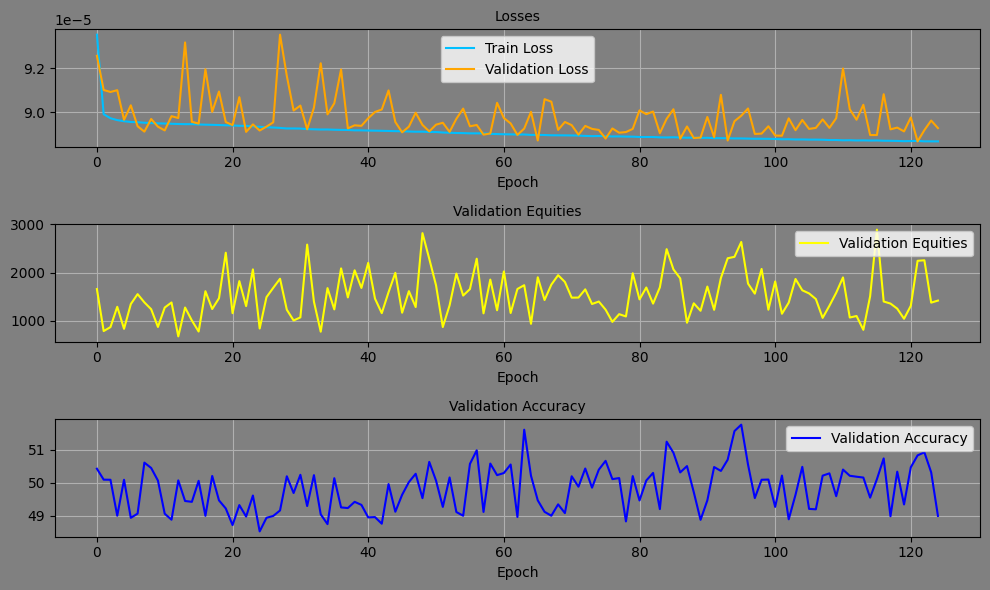

Epoch: 125, Val Equity: 1507.11, Val Accuracy: 50.44 train_losses: 0.0002669055763605011, val_losses: 8.937372331274673e-05, Duration: 0:01:46.484157


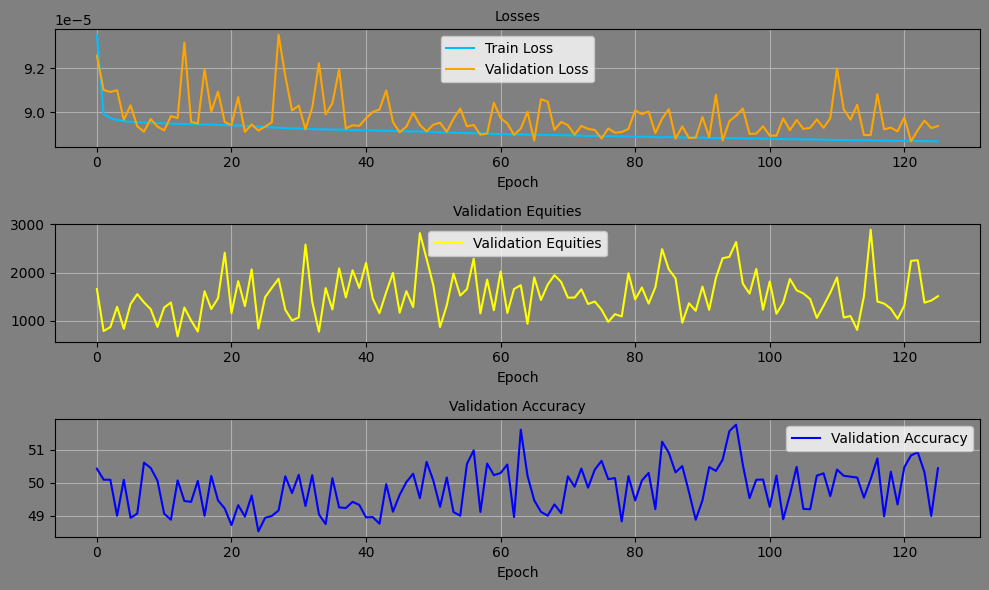

Epoch: 126, Val Equity: 1642.45, Val Accuracy: 50.69 train_losses: 0.00026653430254980305, val_losses: 8.893966878531501e-05, Duration: 0:01:45.658106


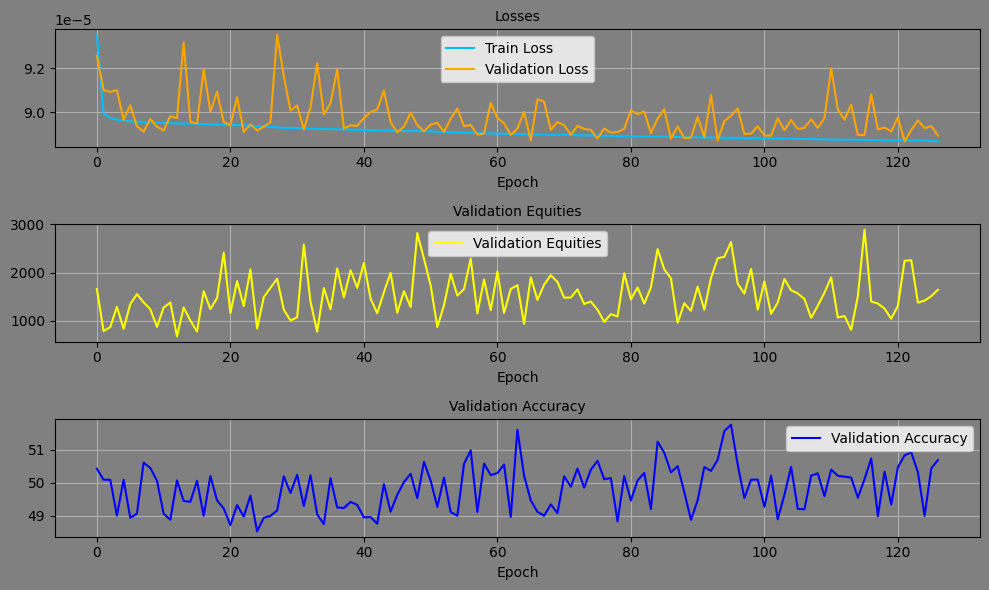

Epoch: 127, Val Equity: 3024.62, Val Accuracy: 50.53 train_losses: 0.0002667835480422109, val_losses: 8.854933548718691e-05, Duration: 0:01:44.928616


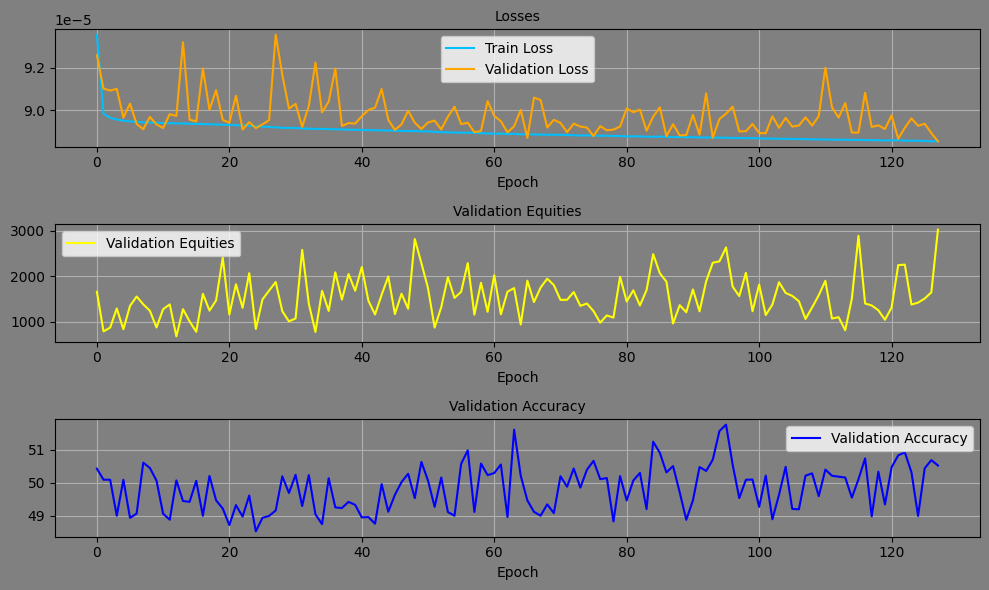

Epoch: 128, Val Equity: 1230.51, Val Accuracy: 50.30 train_losses: 0.00026653541341116075, val_losses: 9.137690358329564e-05, Duration: 0:01:44.863845


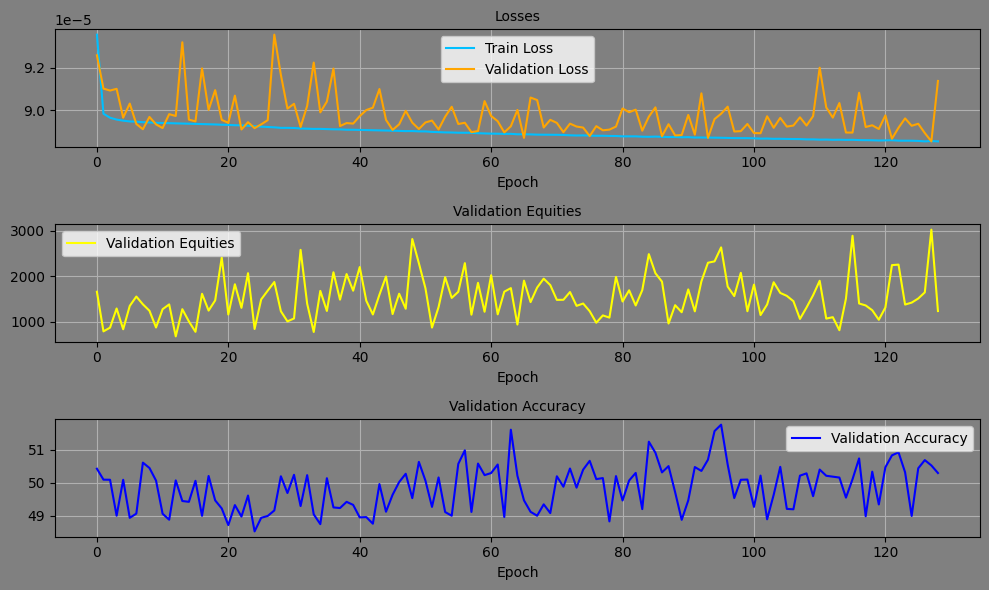

Epoch: 129, Val Equity: 2069.85, Val Accuracy: 49.10 train_losses: 0.0002664972437167204, val_losses: 8.882100519258529e-05, Duration: 0:01:44.423263


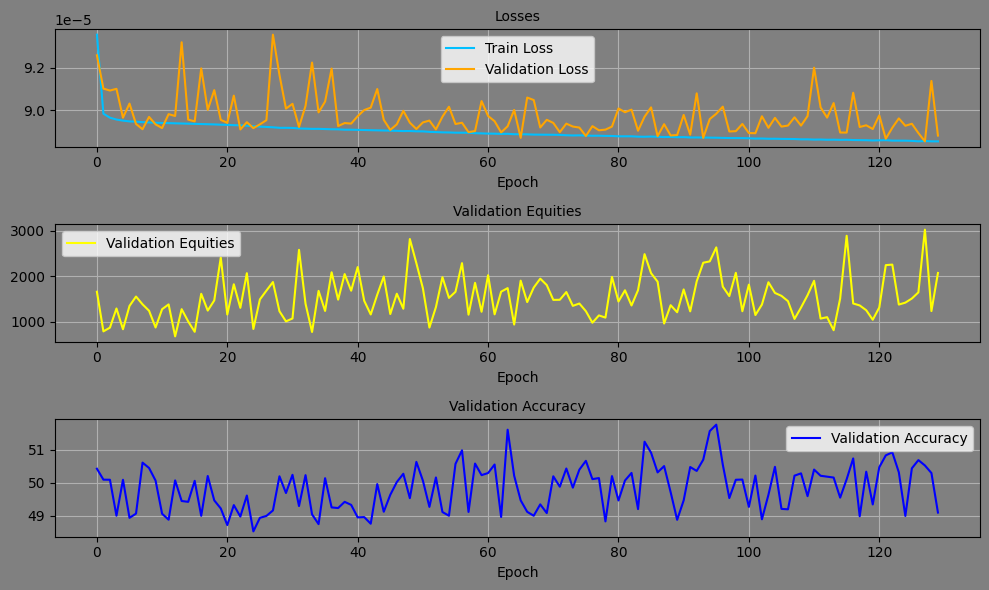

Epoch: 130, Val Equity: 2079.34, Val Accuracy: 49.19 train_losses: 0.0002665921336660457, val_losses: 8.910704491427168e-05, Duration: 0:01:44.881487


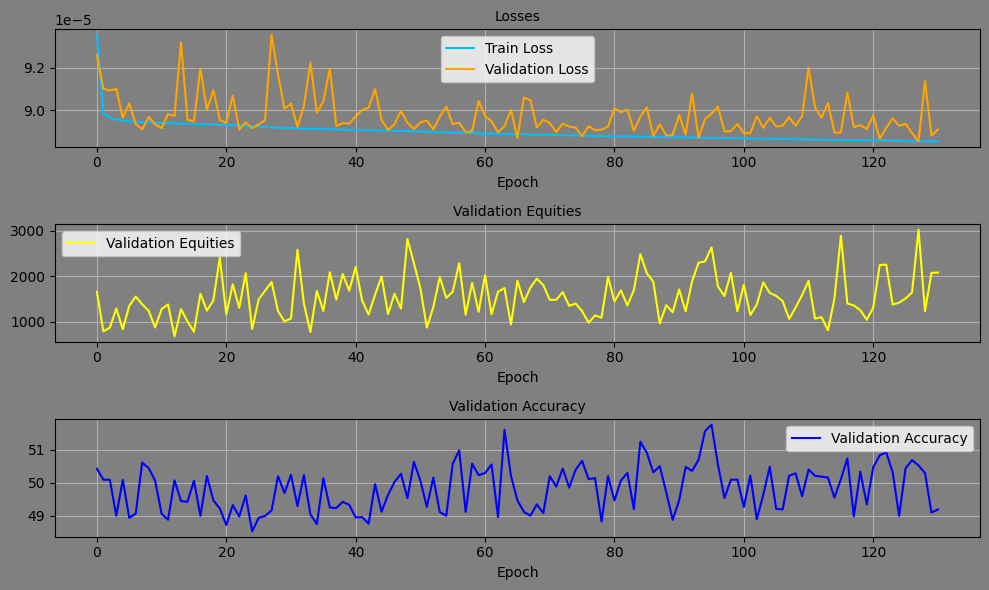

Epoch: 131, Val Equity: 1353.75, Val Accuracy: 50.28 train_losses: 0.0002664671614968761, val_losses: 9.202926594298333e-05, Duration: 0:01:44.311672


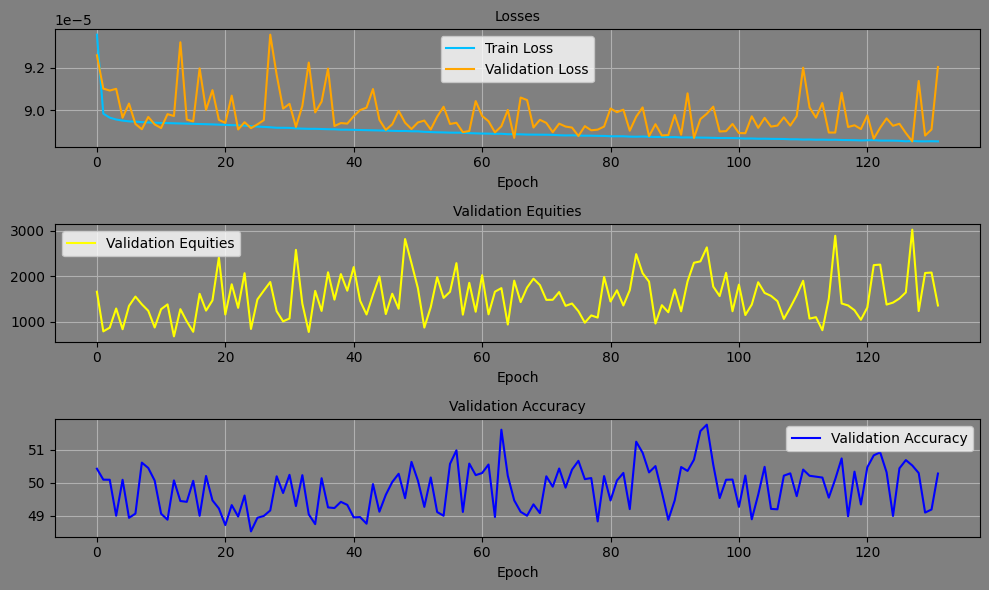

Epoch: 132, Val Equity: 1686.84, Val Accuracy: 50.72 train_losses: 0.00026624282217442937, val_losses: 9.193665027851239e-05, Duration: 0:01:45.351889


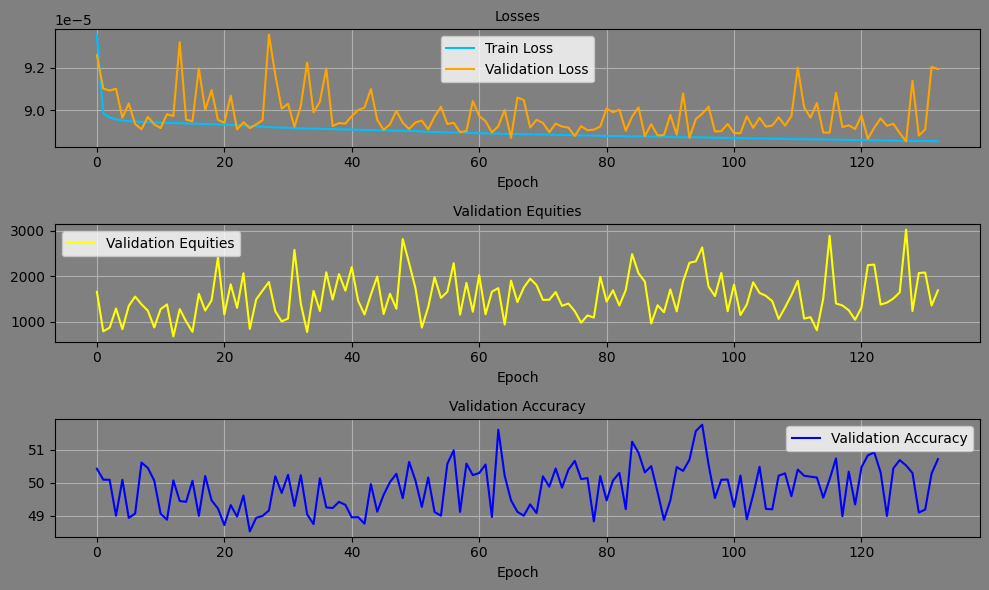

Epoch: 133, Val Equity: 2118.27, Val Accuracy: 49.38 train_losses: 0.0002662515246858057, val_losses: 8.921892731450498e-05, Duration: 0:01:44.877905


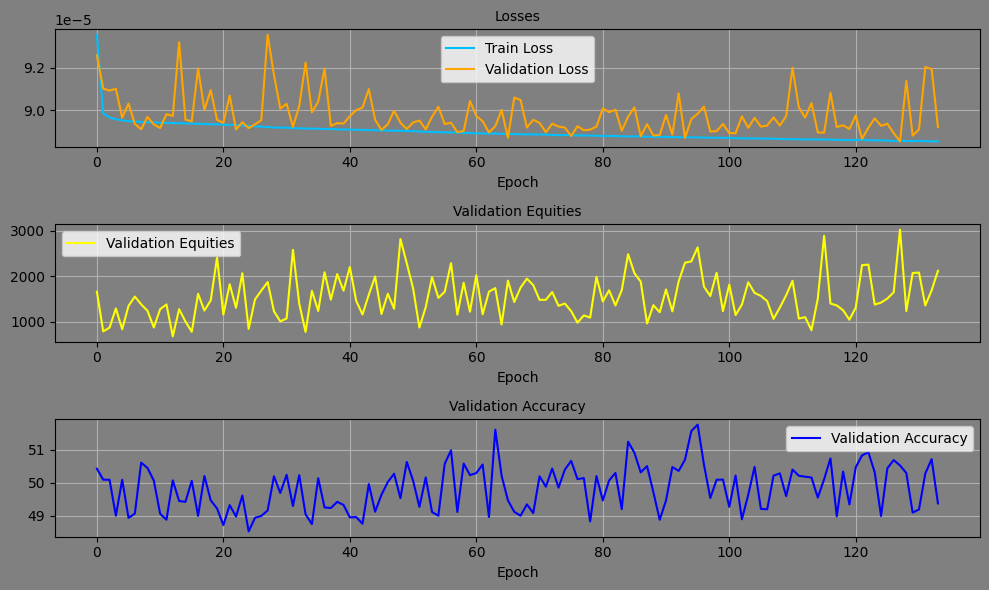

Epoch: 134, Val Equity: 1734.64, Val Accuracy: 50.27 train_losses: 0.00026621026011514737, val_losses: 8.911338227335364e-05, Duration: 0:01:47.017923


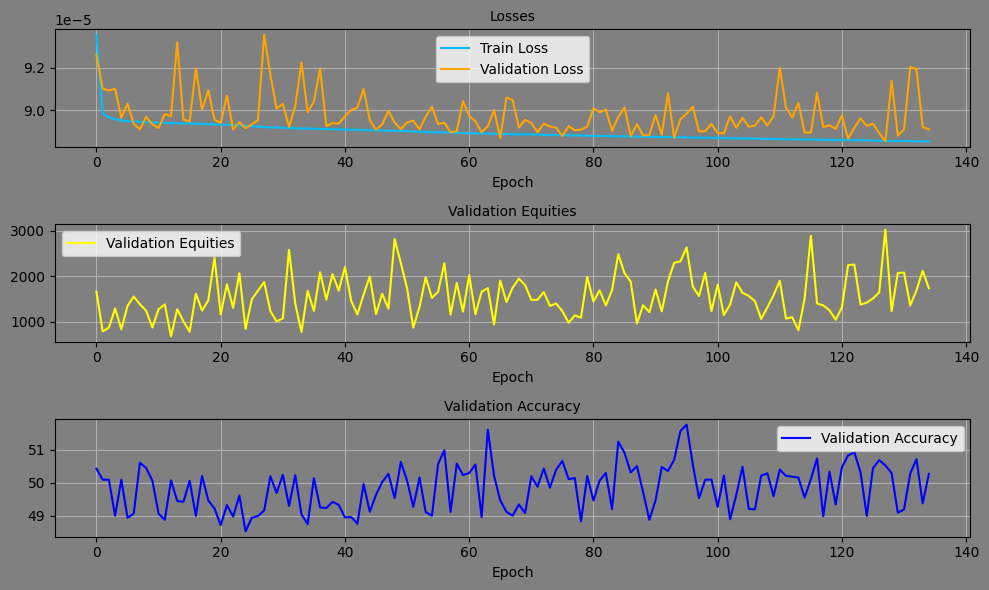

Epoch: 135, Val Equity: 1728.23, Val Accuracy: 50.61 train_losses: 0.0002661402159544391, val_losses: 8.866551797837019e-05, Duration: 0:01:44.321400


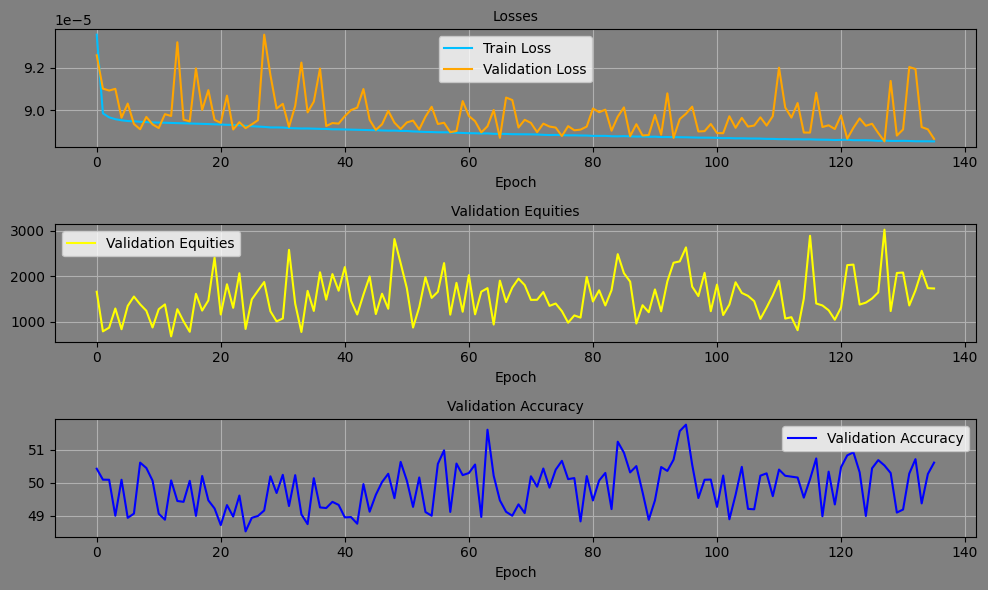

Epoch: 136, Val Equity: 1434.51, Val Accuracy: 49.53 train_losses: 0.00026607766183059264, val_losses: 8.905016875360161e-05, Duration: 0:01:45.145861


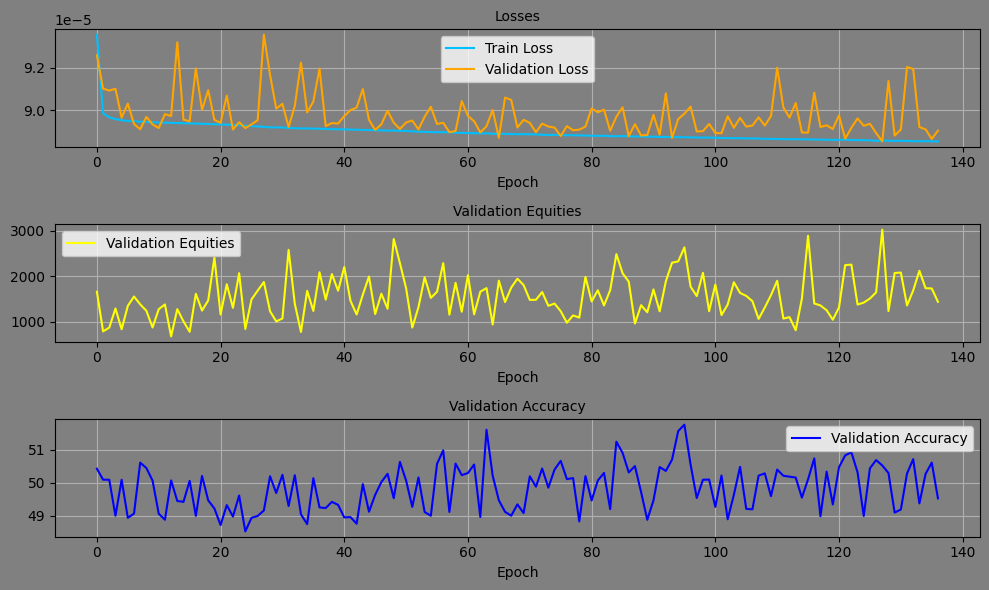

Epoch: 137, Val Equity: 2331.15, Val Accuracy: 50.16 train_losses: 0.0002656893100903489, val_losses: 8.97782010724768e-05, Duration: 0:01:46.446826


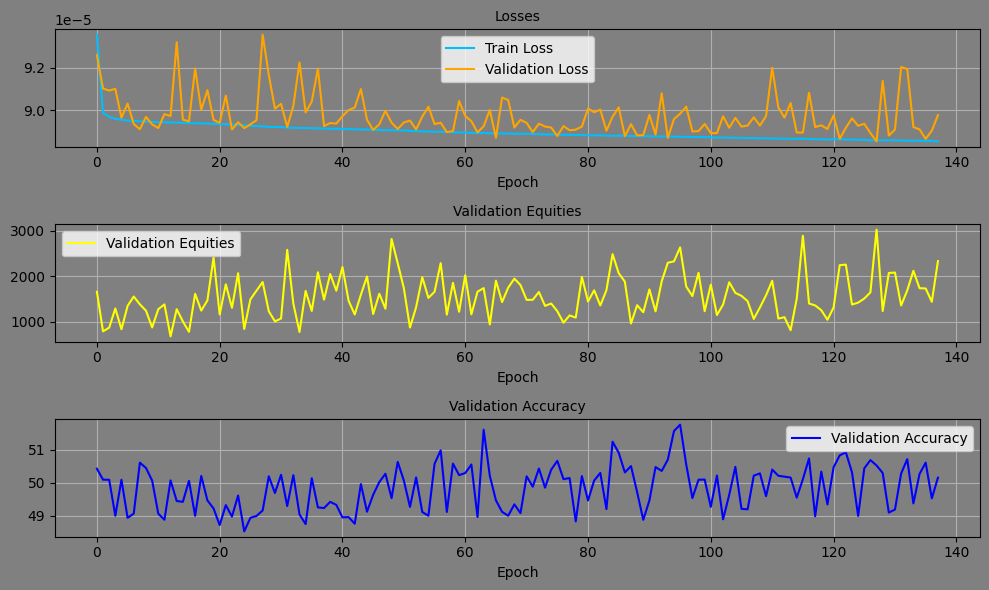

Epoch: 138, Val Equity: 1252.48, Val Accuracy: 48.89 train_losses: 0.00026563209882894396, val_losses: 8.945069566834718e-05, Duration: 0:01:46.416683


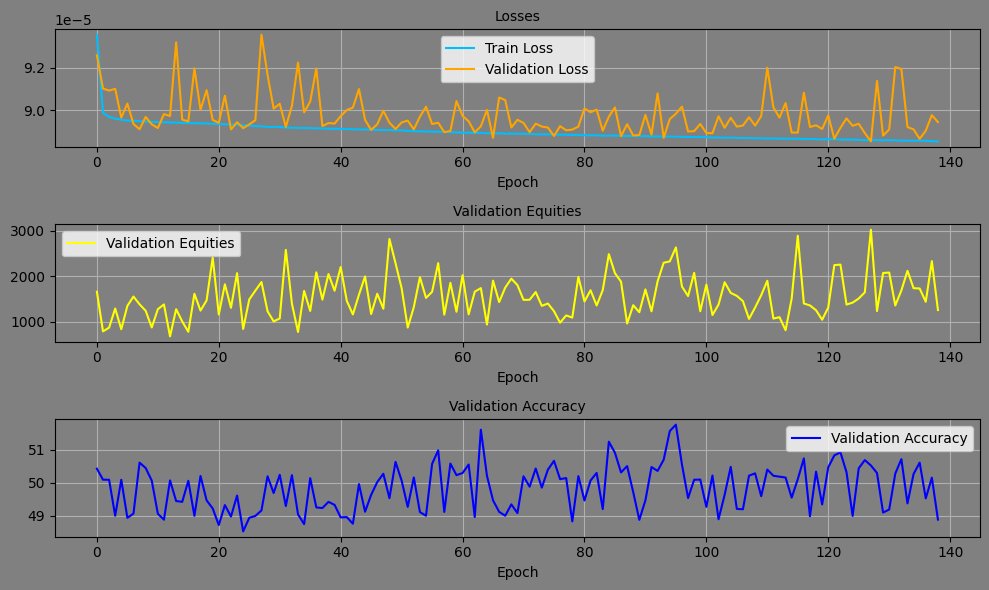

Epoch: 139, Val Equity: 1862.63, Val Accuracy: 50.51 train_losses: 0.0002656783487409706, val_losses: 8.913931378629059e-05, Duration: 0:01:45.982041


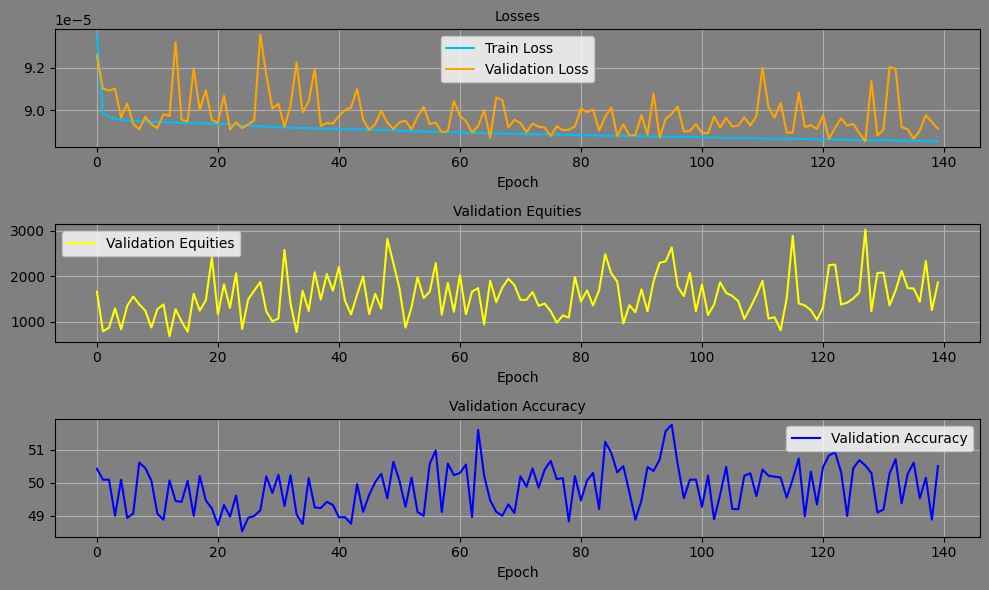

Epoch: 140, Val Equity: 2273.55, Val Accuracy: 50.01 train_losses: 0.0002657262245249727, val_losses: 8.905064169084653e-05, Duration: 0:01:45.034642


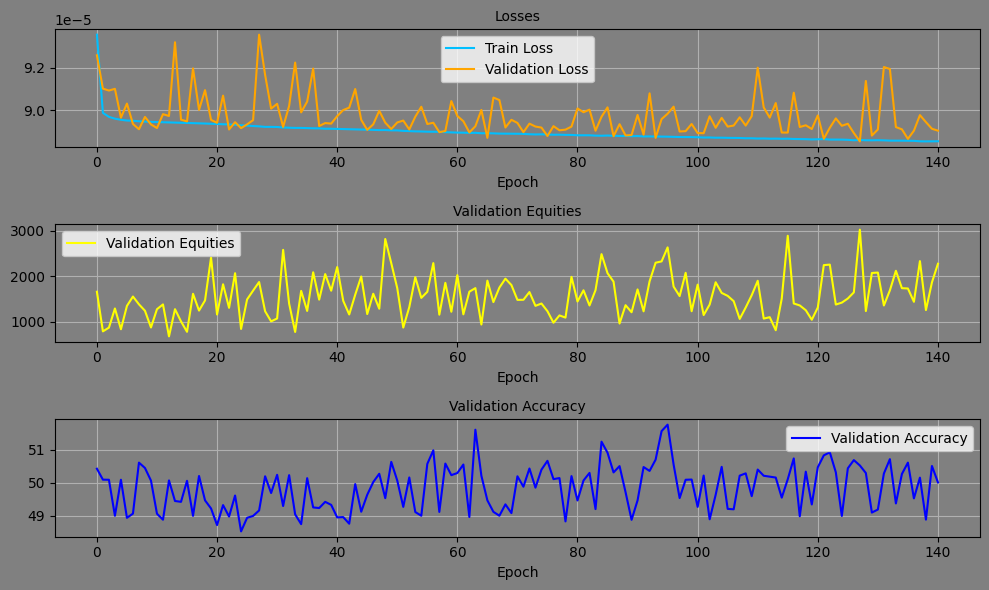

Epoch: 141, Val Equity: 1448.41, Val Accuracy: 49.69 train_losses: 0.0002654552897217947, val_losses: 8.90037408680655e-05, Duration: 0:01:44.299295


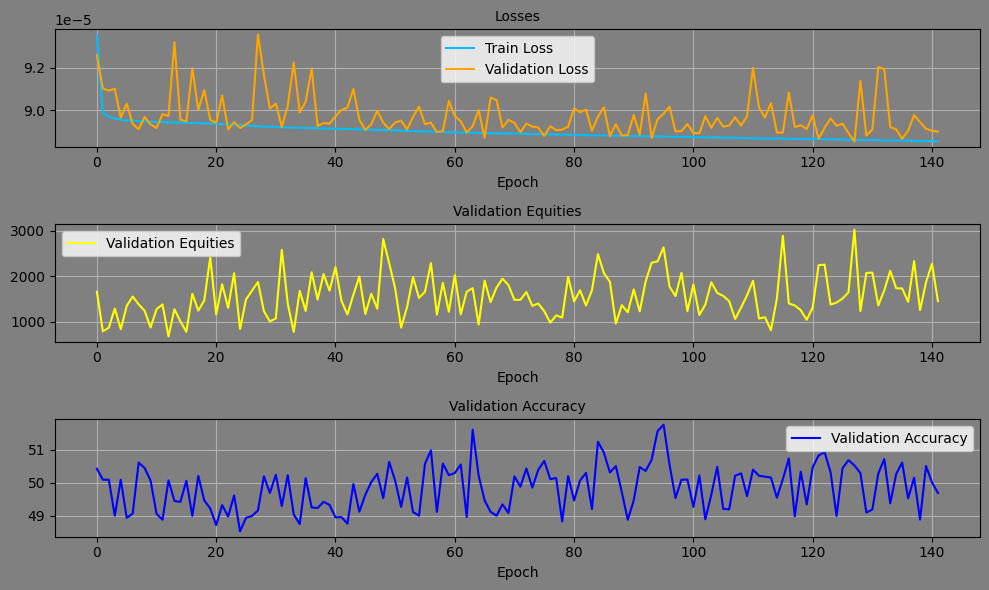

Epoch: 142, Val Equity: 1296.43, Val Accuracy: 50.07 train_losses: 0.0002652475758617495, val_losses: 8.937672100728378e-05, Duration: 0:01:43.681454


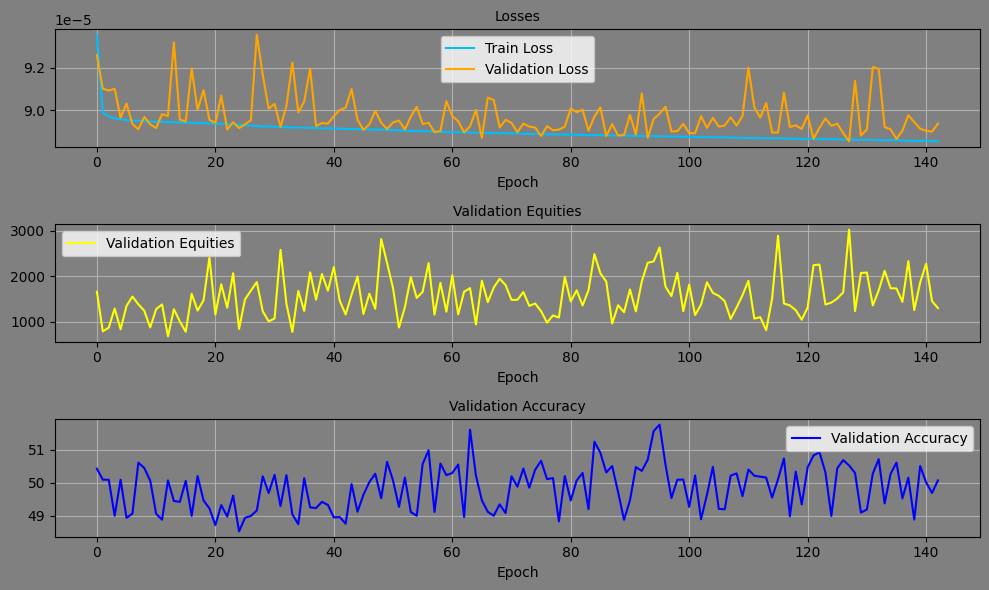

Epoch: 143, Val Equity: 1500.50, Val Accuracy: 50.38 train_losses: 0.0002654857624993679, val_losses: 8.888886077329516e-05, Duration: 0:01:43.630461


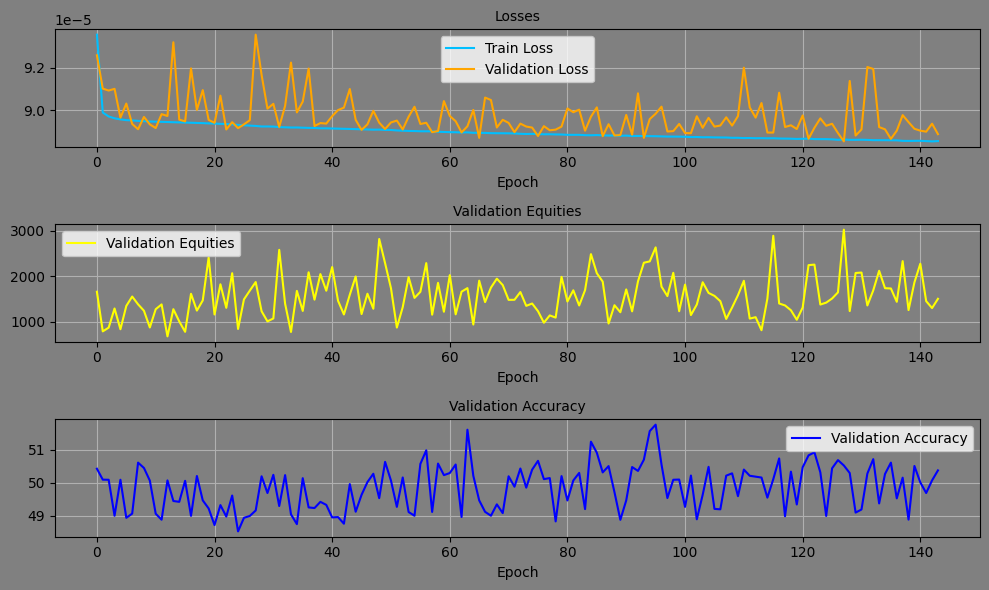

Epoch: 144, Val Equity: 1463.65, Val Accuracy: 48.99 train_losses: 0.0002652665986879472, val_losses: 9.02264509932138e-05, Duration: 0:01:45.190910


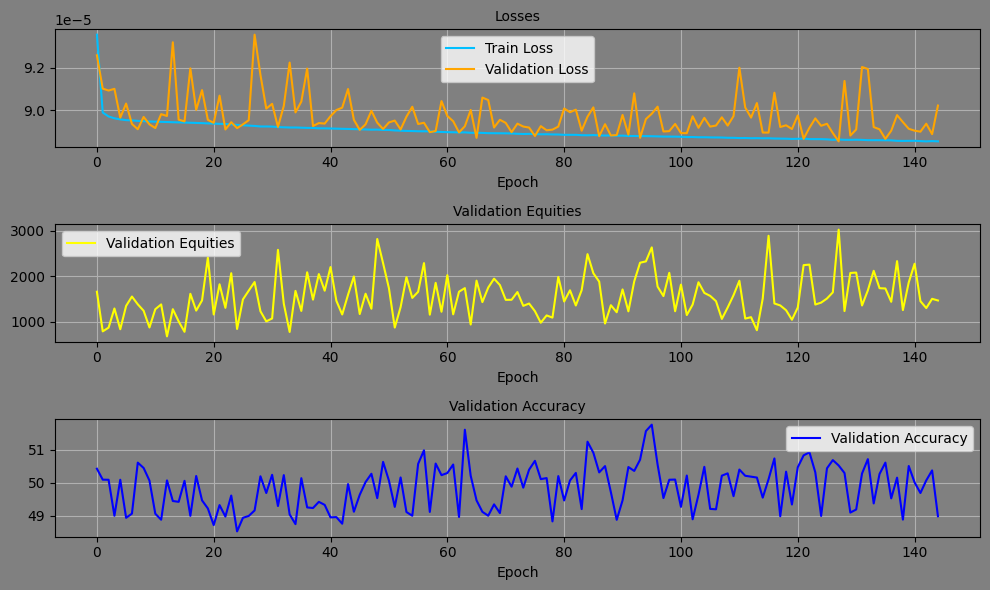

Epoch: 145, Val Equity: 1881.54, Val Accuracy: 50.56 train_losses: 0.0002653097180106071, val_losses: 8.901677938411012e-05, Duration: 0:01:44.585111


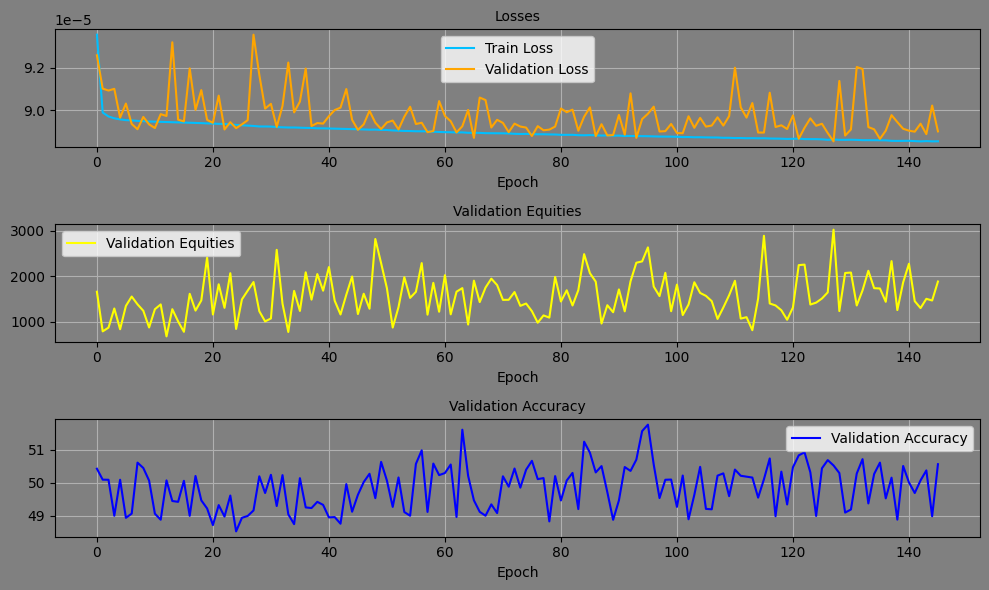

Epoch: 146, Val Equity: 1588.23, Val Accuracy: 49.09 train_losses: 0.0002652623880514393, val_losses: 8.892470941646025e-05, Duration: 0:01:45.396193


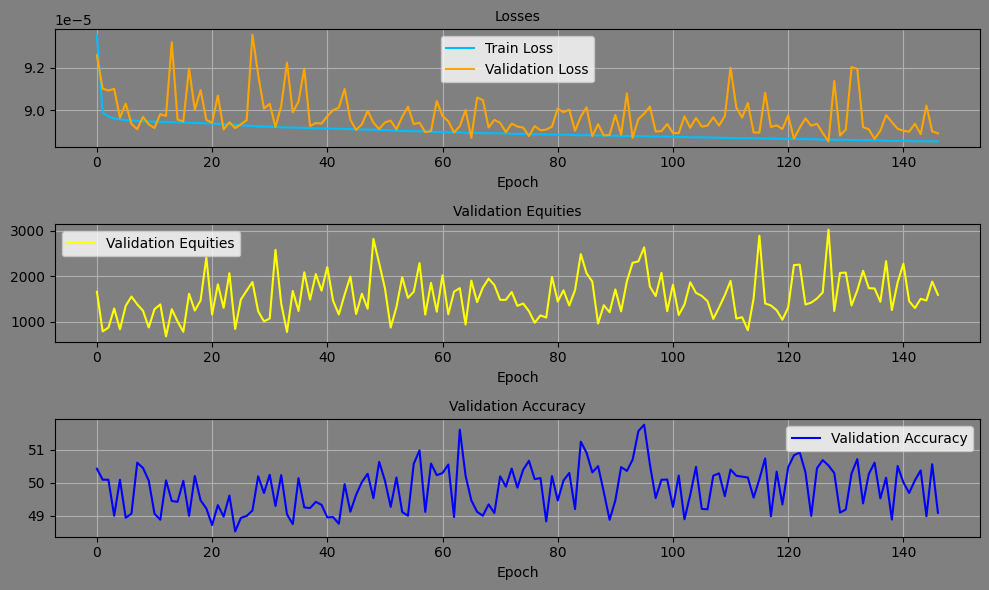

Epoch: 147, Val Equity: 2267.88, Val Accuracy: 50.82 train_losses: 0.00026498880314060135, val_losses: 8.908697054721415e-05, Duration: 0:01:46.050824


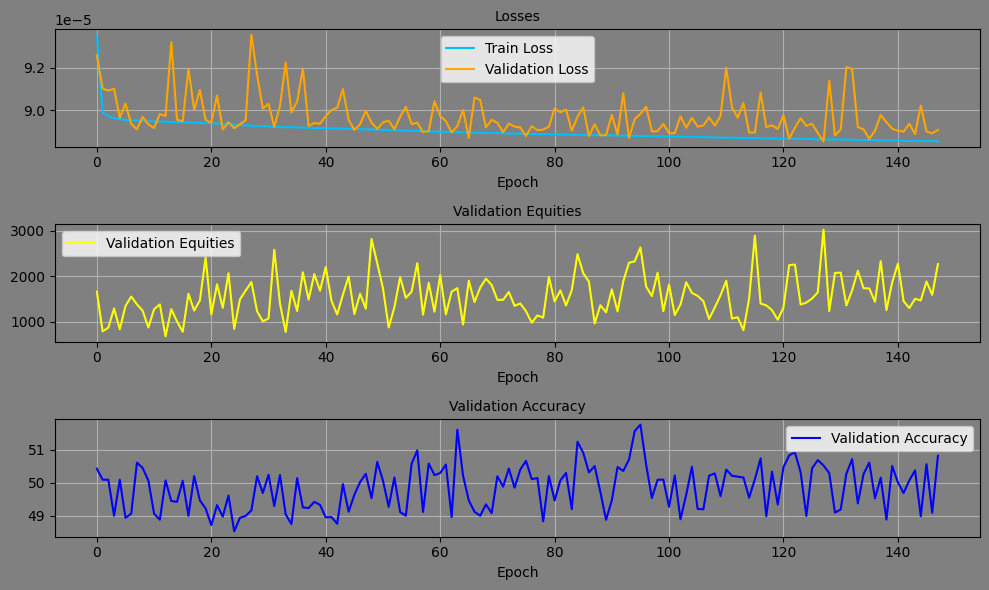

Epoch: 148, Val Equity: 1524.19, Val Accuracy: 49.38 train_losses: 0.00026468501575628003, val_losses: 8.885100396582857e-05, Duration: 0:01:44.219737


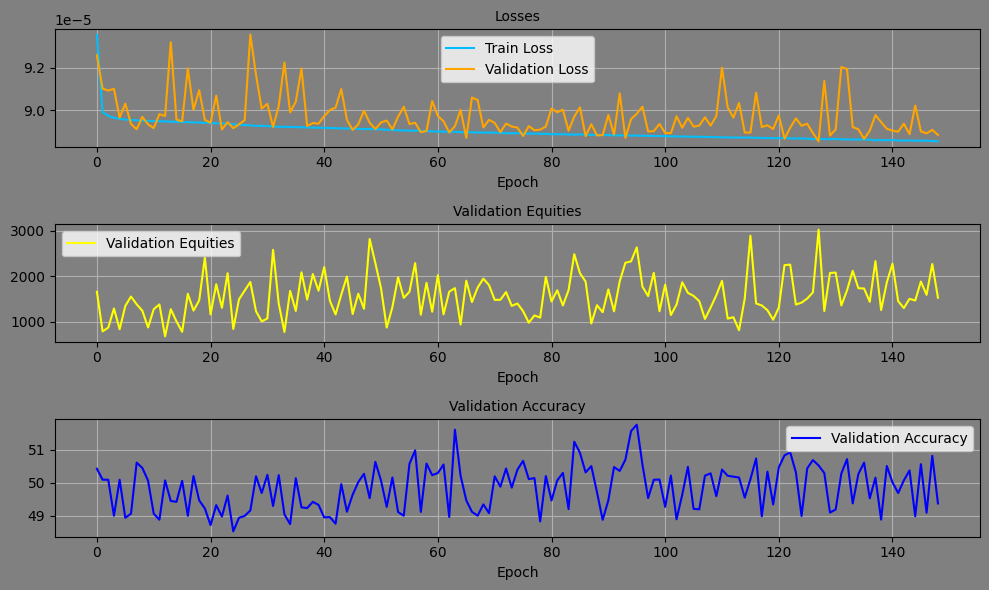

Epoch: 149, Val Equity: 1549.73, Val Accuracy: 50.44 train_losses: 0.000264636219590675, val_losses: 8.909431198844686e-05, Duration: 0:01:48.077952


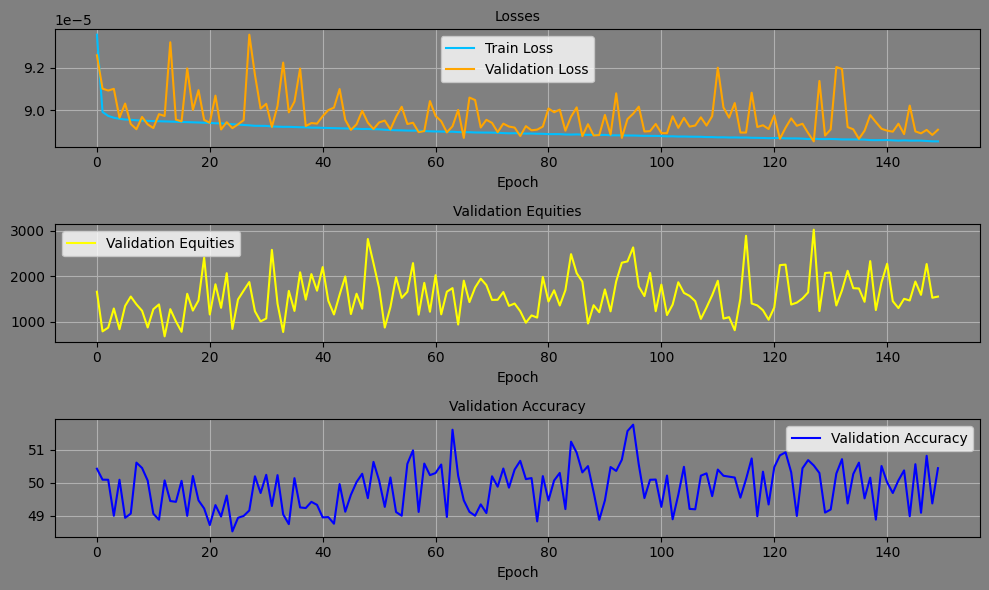

Epoch: 150, Val Equity: 1542.01, Val Accuracy: 49.19 train_losses: 0.0002647456417051446, val_losses: 8.939453982748091e-05, Duration: 0:01:46.413350


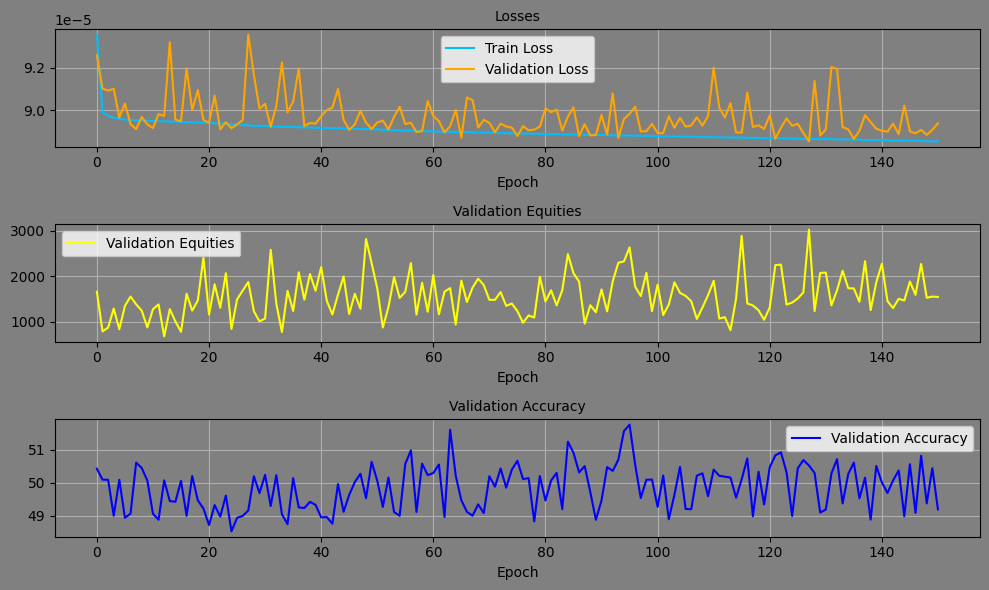

Epoch: 151, Val Equity: 2015.29, Val Accuracy: 50.25 train_losses: 0.00026452180152984243, val_losses: 8.911018812796101e-05, Duration: 0:01:45.335611


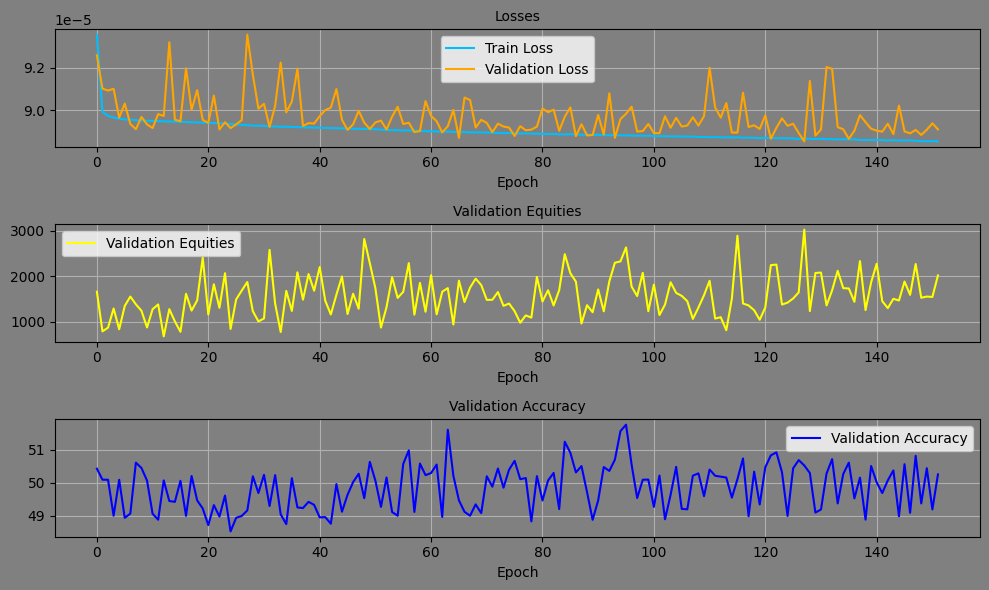

Epoch: 152, Val Equity: 1939.03, Val Accuracy: 50.75 train_losses: 0.00026445356633907644, val_losses: 9.01486782822758e-05, Duration: 0:01:44.634685


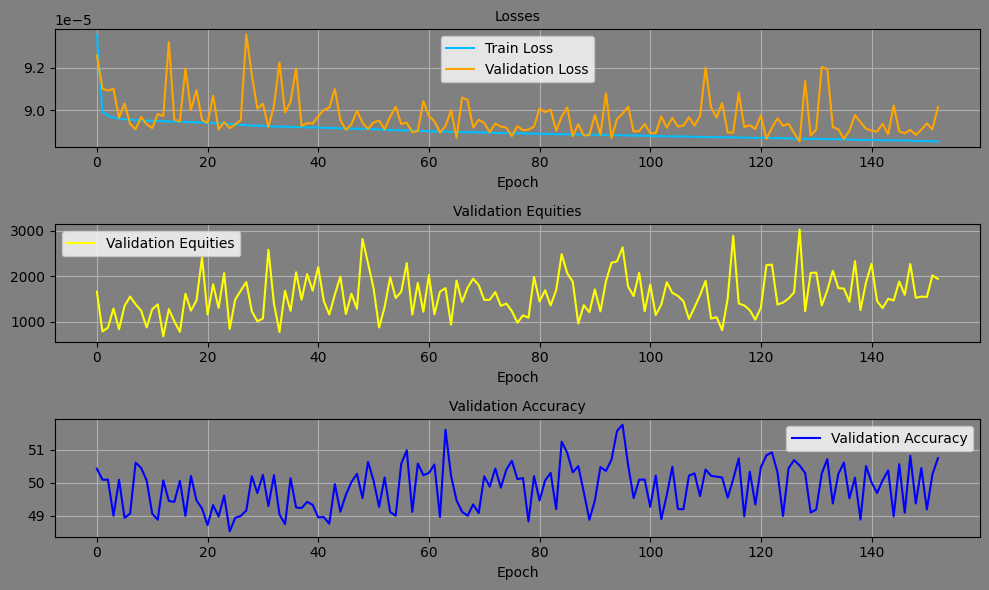

Epoch: 153, Val Equity: 1619.98, Val Accuracy: 50.38 train_losses: 0.000264352334784512, val_losses: 8.867828728398308e-05, Duration: 0:01:44.767191


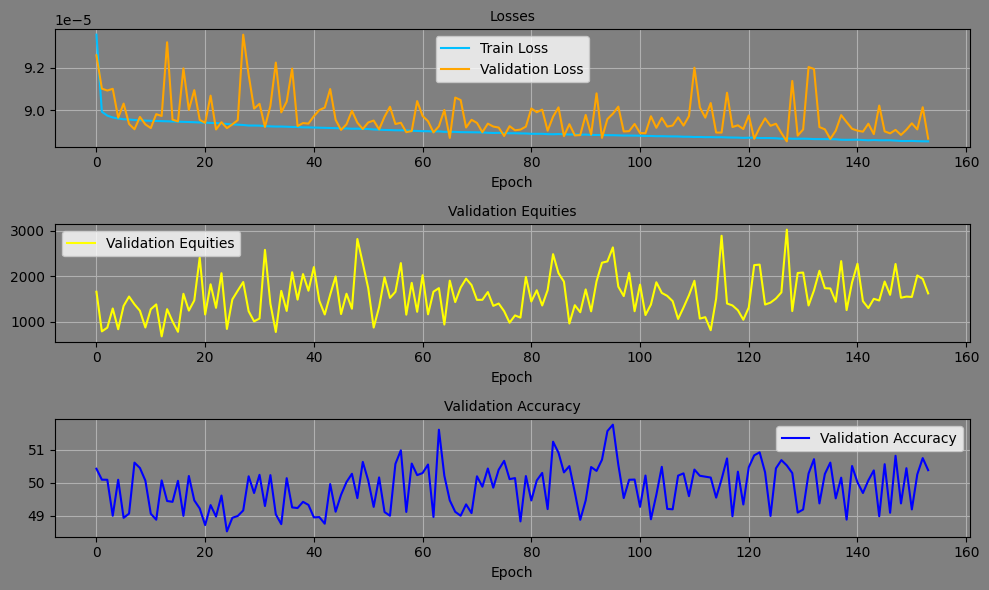

Epoch: 154, Val Equity: 1244.82, Val Accuracy: 50.19 train_losses: 0.0002642467471274336, val_losses: 8.926400914788246e-05, Duration: 0:01:44.791154


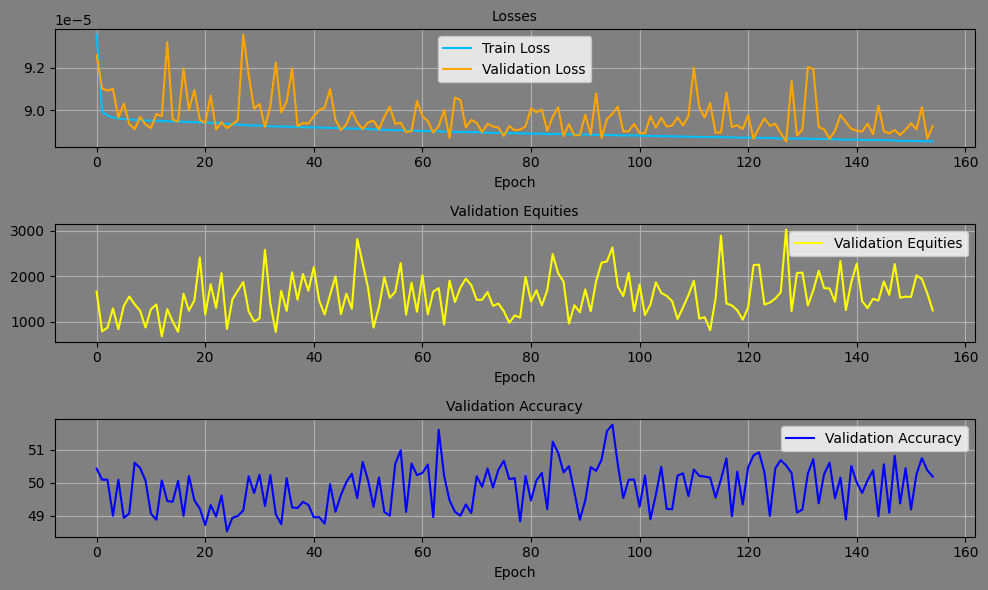

Epoch: 155, Val Equity: 935.90, Val Accuracy: 50.55 train_losses: 0.00026421884808492107, val_losses: 8.910337783163413e-05, Duration: 0:01:44.317166


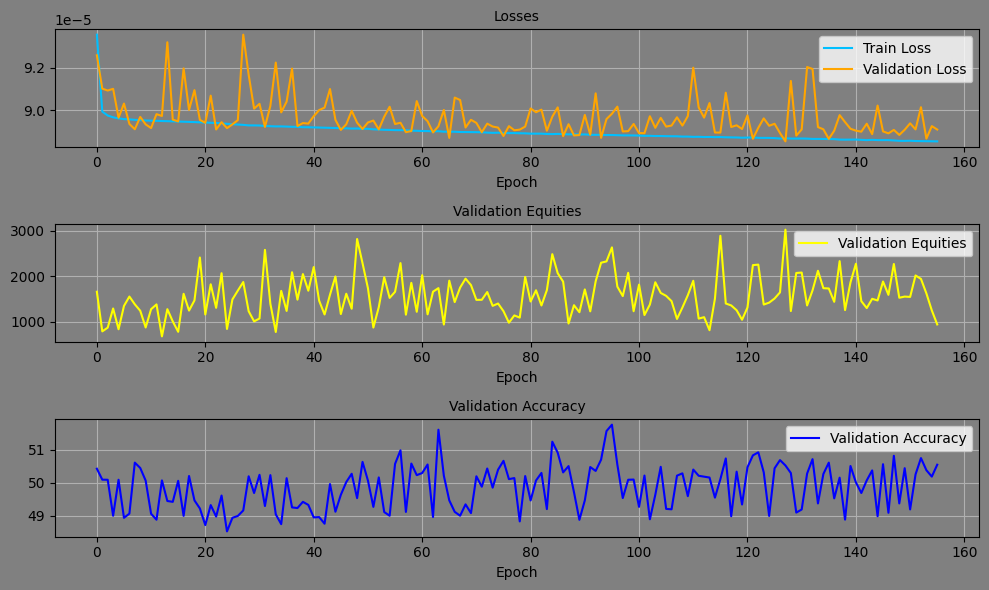

Epoch: 156, Val Equity: 1318.16, Val Accuracy: 49.22 train_losses: 0.0002640459132278669, val_losses: 8.92815223778598e-05, Duration: 0:01:43.217454


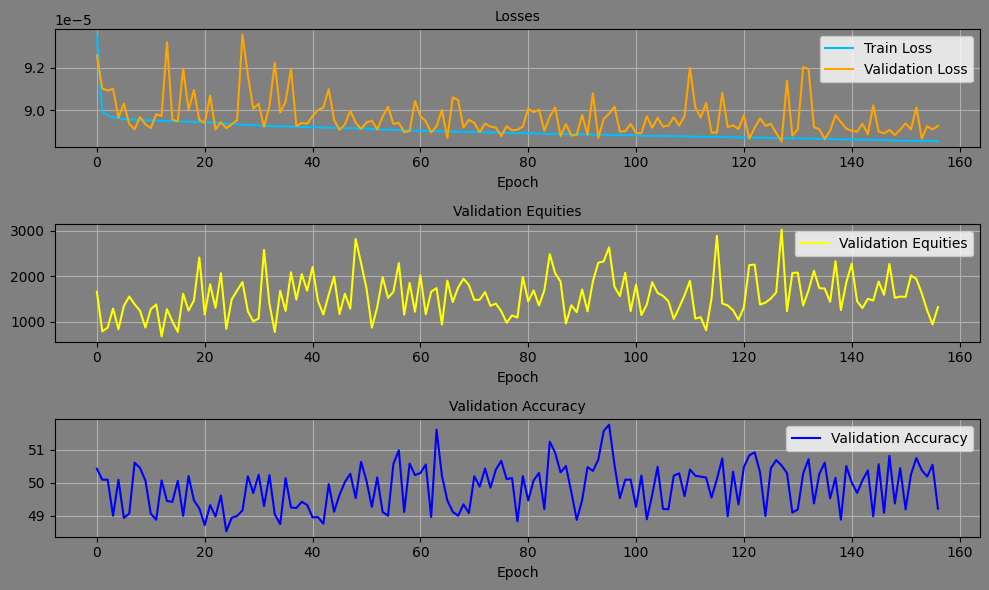

Epoch: 157, Val Equity: 1520.68, Val Accuracy: 50.50 train_losses: 0.00026403180394402265, val_losses: 8.875958155840635e-05, Duration: 0:01:45.445605


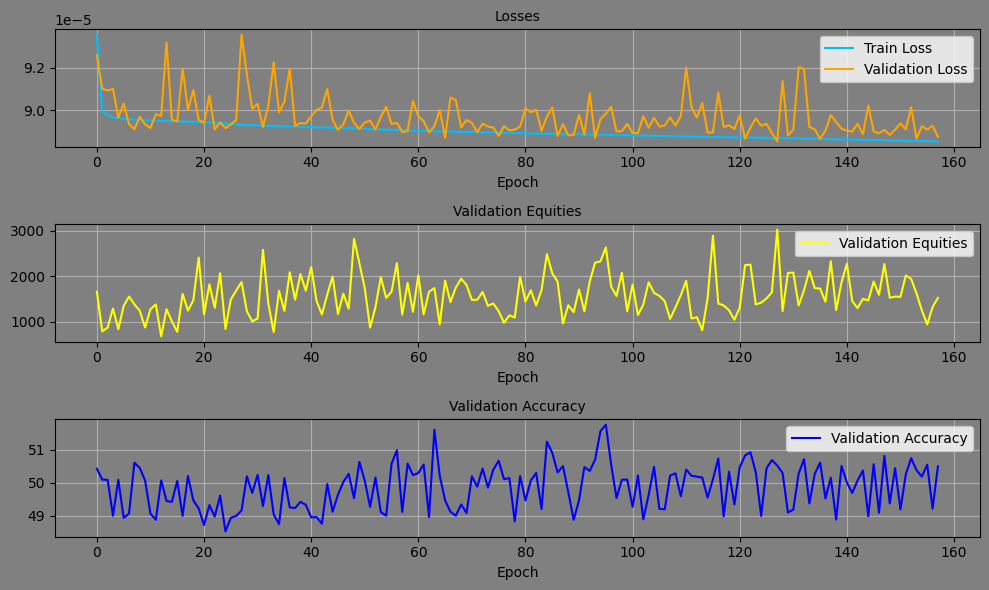

Epoch: 158, Val Equity: 982.13, Val Accuracy: 50.16 train_losses: 0.0002642684570400149, val_losses: 8.915829675970599e-05, Duration: 0:01:45.530727


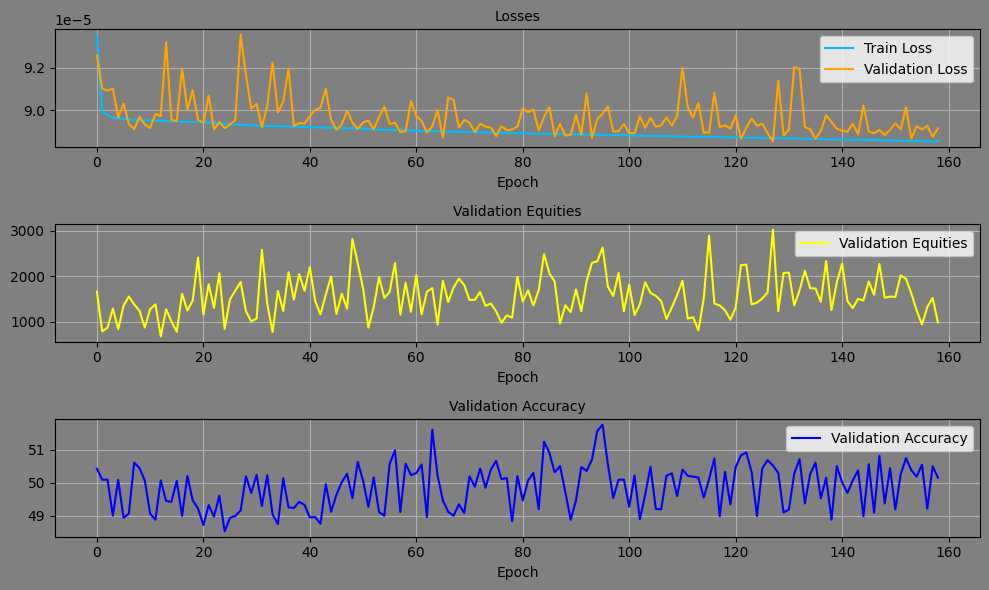

Epoch: 159, Val Equity: 2138.66, Val Accuracy: 50.43 train_losses: 0.0002639034948341708, val_losses: 8.979722042568028e-05, Duration: 0:01:44.704346


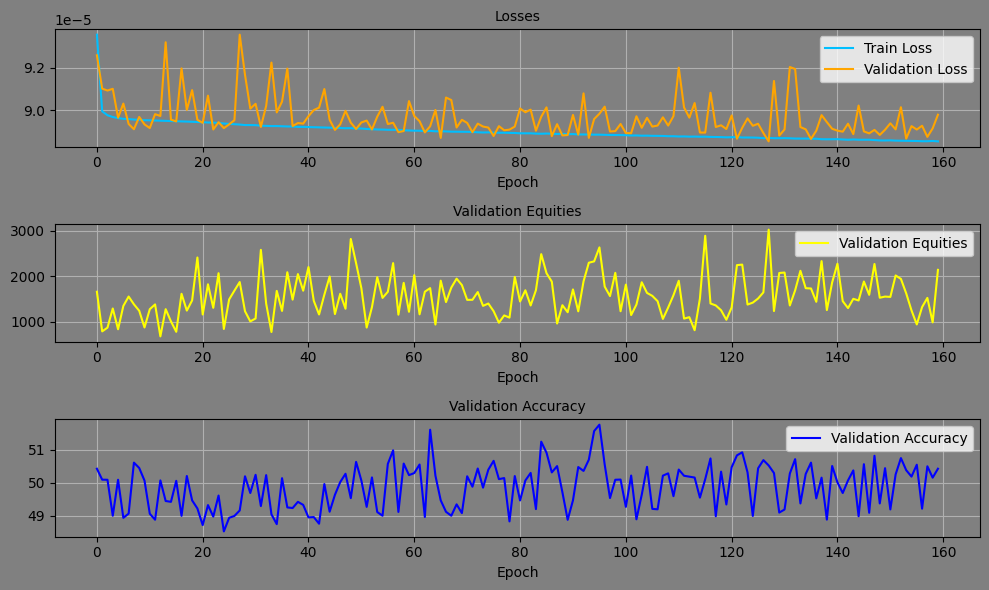

Epoch: 160, Val Equity: 1504.32, Val Accuracy: 49.11 train_losses: 0.0002637905702837953, val_losses: 8.970062481239438e-05, Duration: 0:01:45.148551


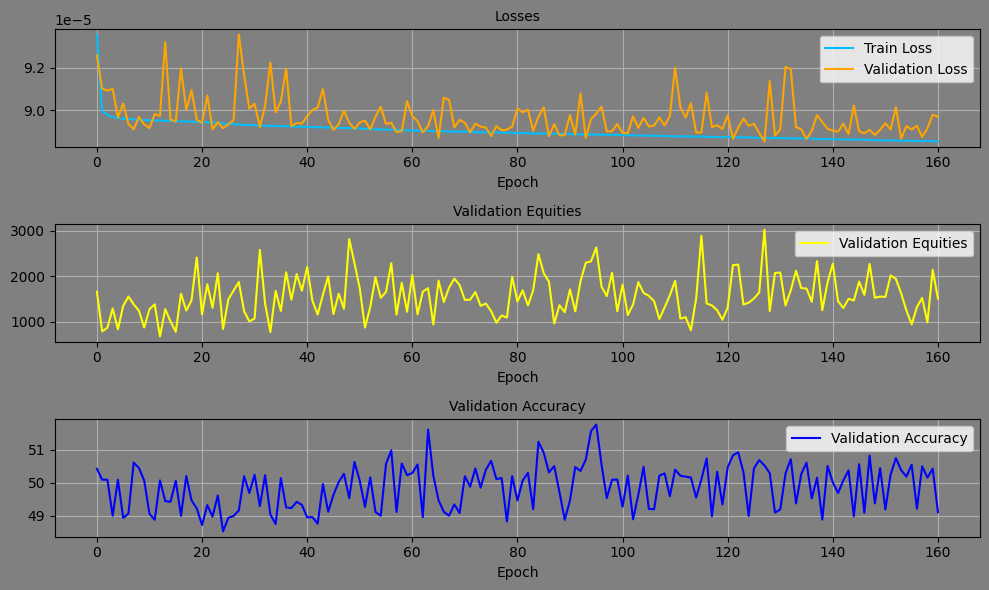

Epoch: 161, Val Equity: 2016.44, Val Accuracy: 51.50 train_losses: 0.00026358935658977794, val_losses: 8.909265307011083e-05, Duration: 0:01:45.260447


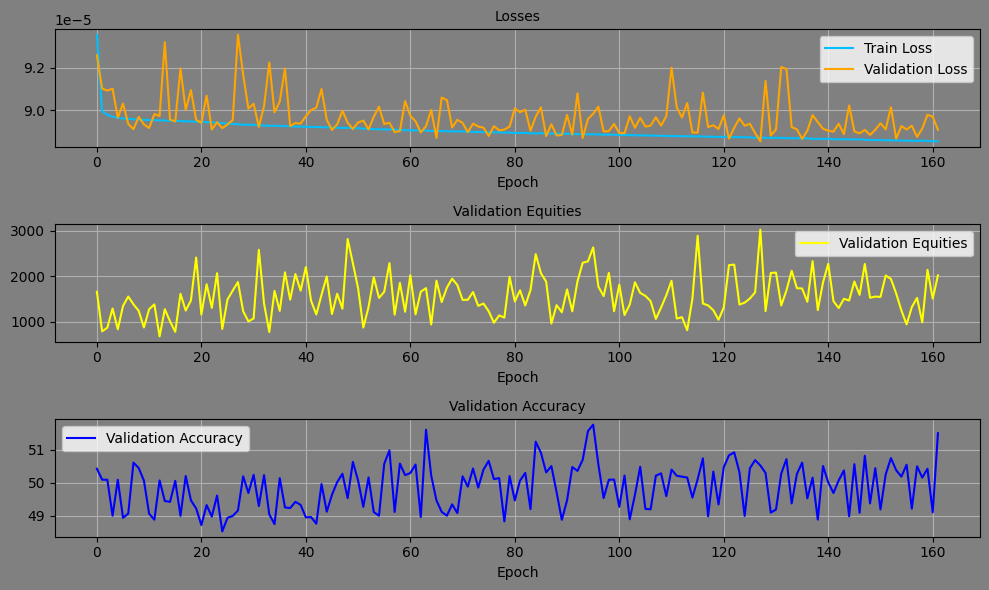

Epoch: 162, Val Equity: 2216.22, Val Accuracy: 51.35 train_losses: 0.000263648683798463, val_losses: 8.951506606535986e-05, Duration: 0:01:48.761677


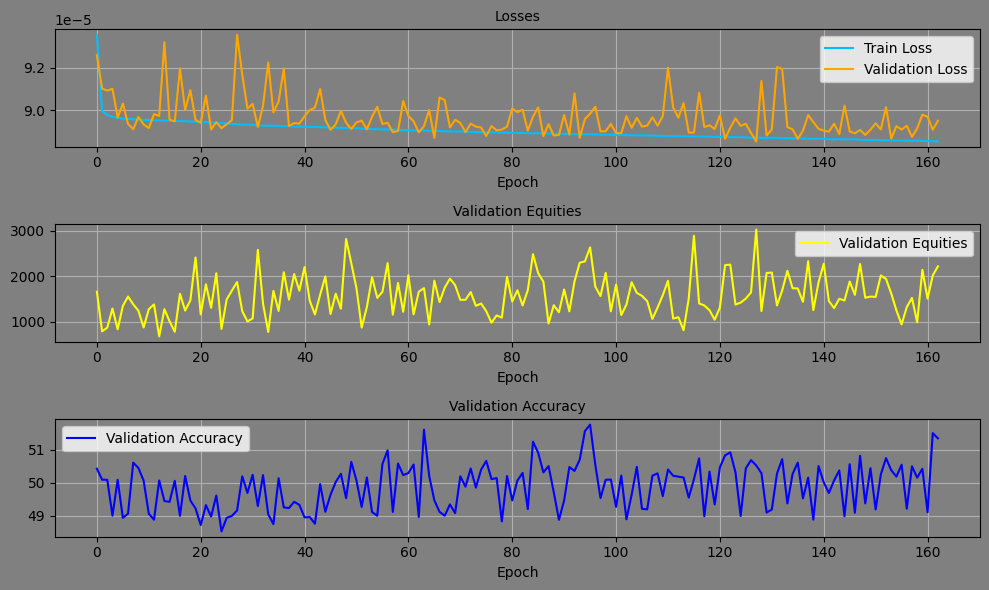

Epoch: 163, Val Equity: 2053.91, Val Accuracy: 51.16 train_losses: 0.00026350082431759076, val_losses: 8.898202941054478e-05, Duration: 0:01:43.999379


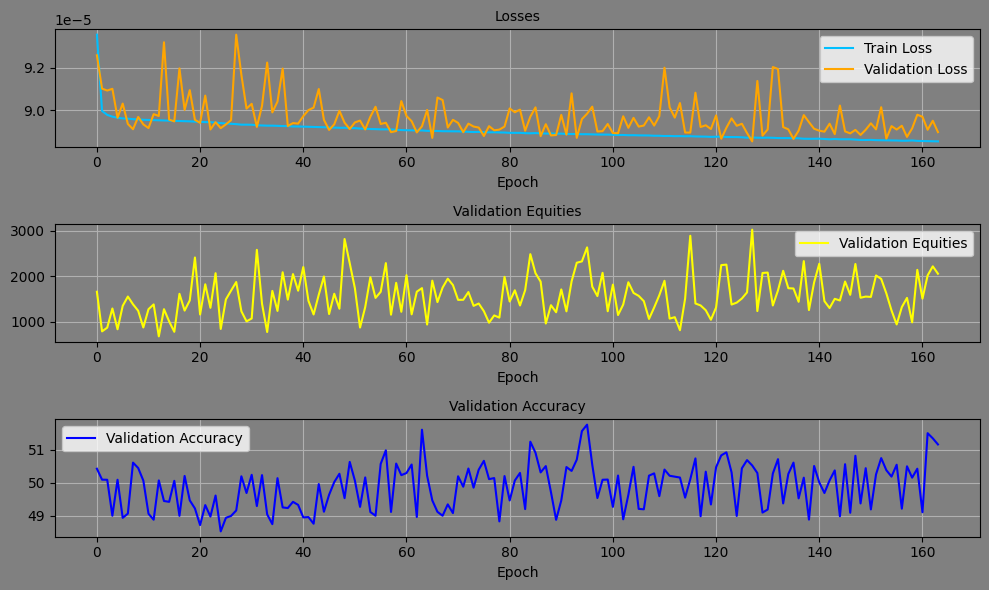

Epoch: 164, Val Equity: 1526.20, Val Accuracy: 50.47 train_losses: 0.00026342745123042916, val_losses: 8.895820792531595e-05, Duration: 0:01:44.293729


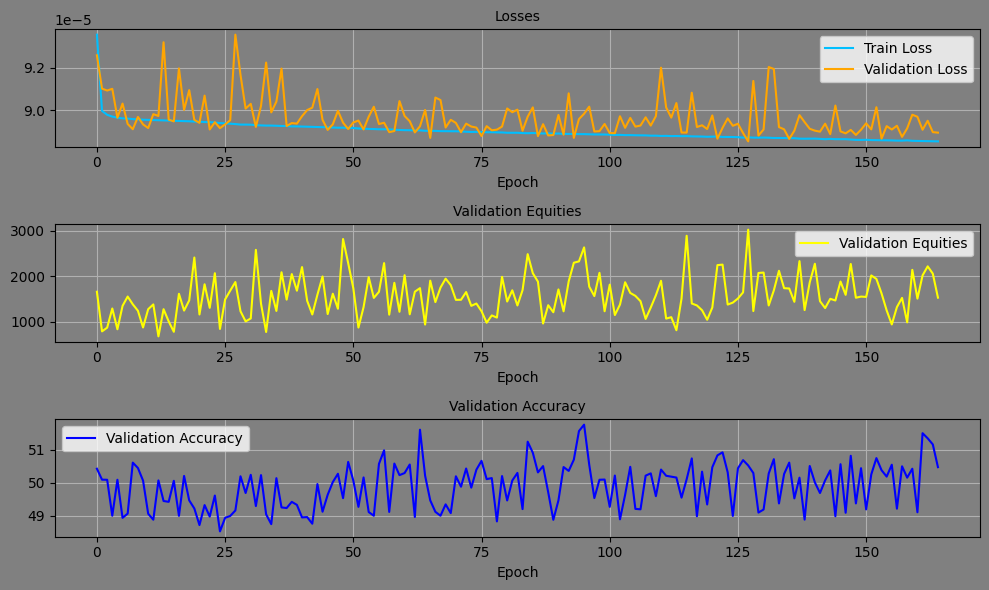

Epoch: 165, Val Equity: 1302.32, Val Accuracy: 50.39 train_losses: 0.00026329409746726073, val_losses: 9.098609007196501e-05, Duration: 0:01:44.999986


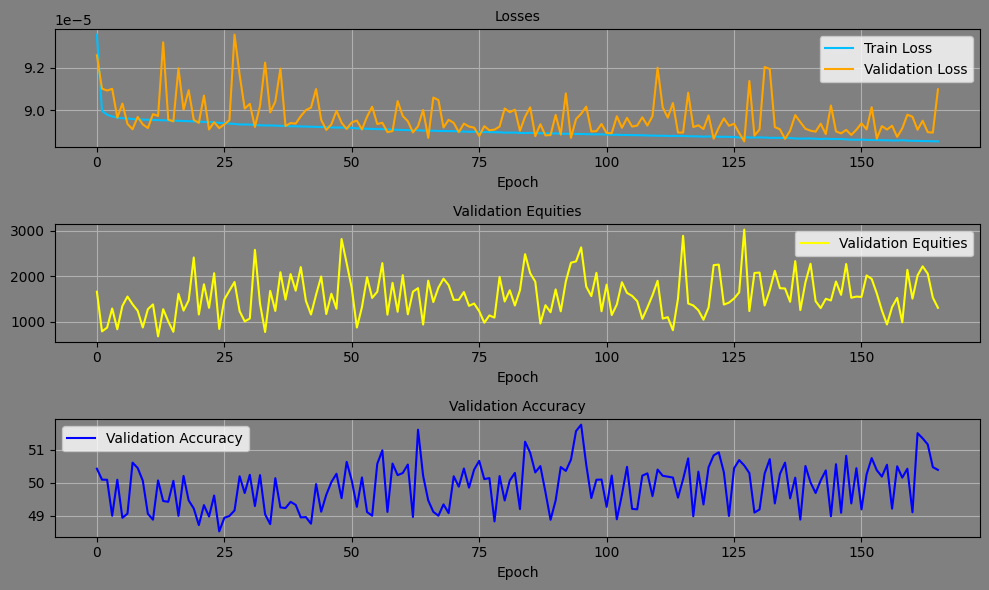

Epoch: 166, Val Equity: 1664.54, Val Accuracy: 48.63 train_losses: 0.0002630175572707733, val_losses: 8.903103298507631e-05, Duration: 0:01:45.160641


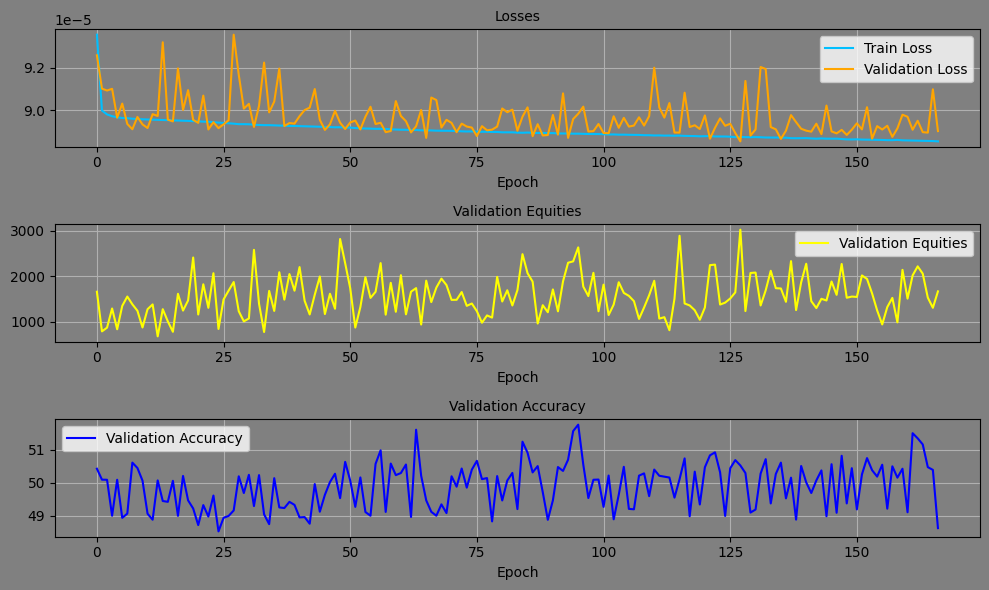

Epoch: 167, Val Equity: 1886.06, Val Accuracy: 49.29 train_losses: 0.0002631938551480855, val_losses: 8.964868175098673e-05, Duration: 0:01:44.396920


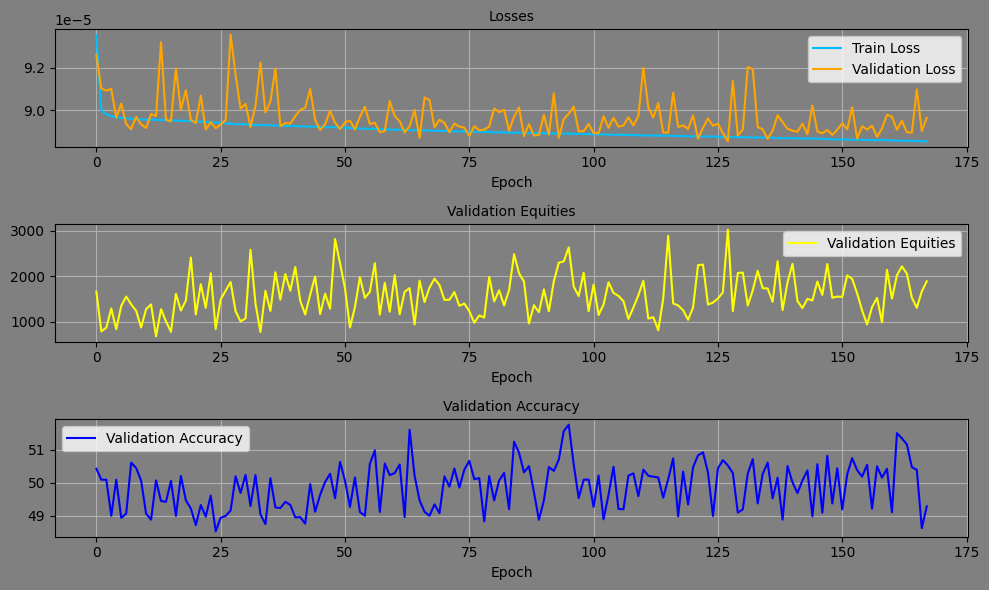

Epoch: 168, Val Equity: 1600.36, Val Accuracy: 50.03 train_losses: 0.00026302254254674854, val_losses: 8.950711344368756e-05, Duration: 0:01:44.547065


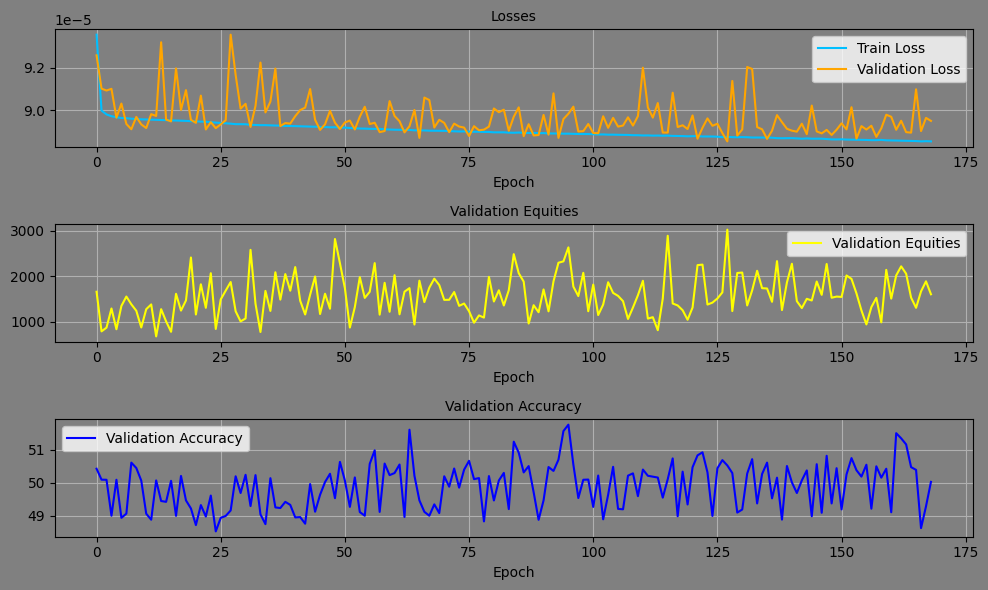

Epoch: 169, Val Equity: 1991.75, Val Accuracy: 49.95 train_losses: 0.00026269552472559383, val_losses: 8.87073329067789e-05, Duration: 0:01:48.182080


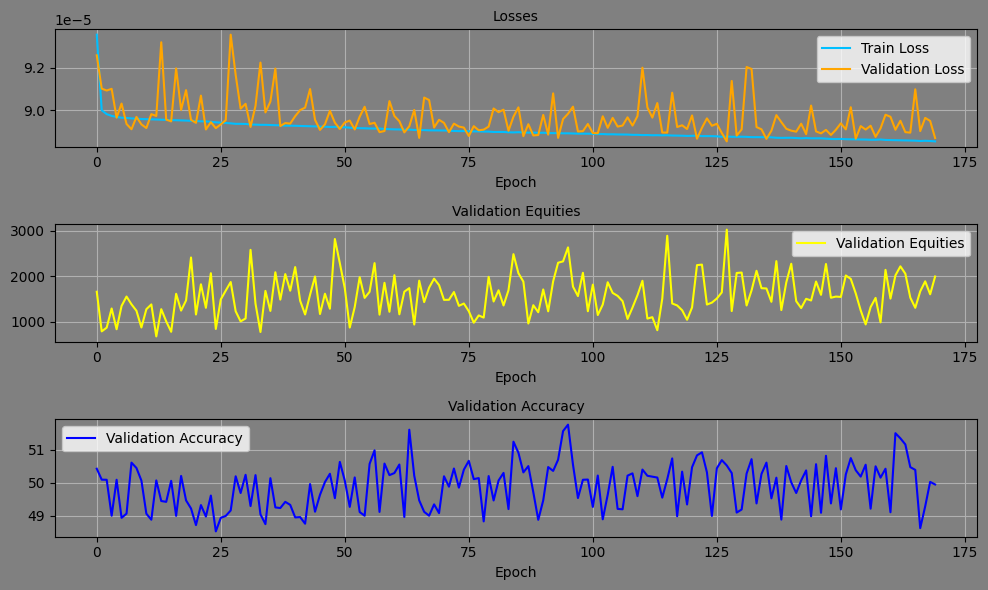

Epoch: 170, Val Equity: 676.30, Val Accuracy: 48.69 train_losses: 0.00026265312504616245, val_losses: 8.891672041499987e-05, Duration: 0:01:45.226754


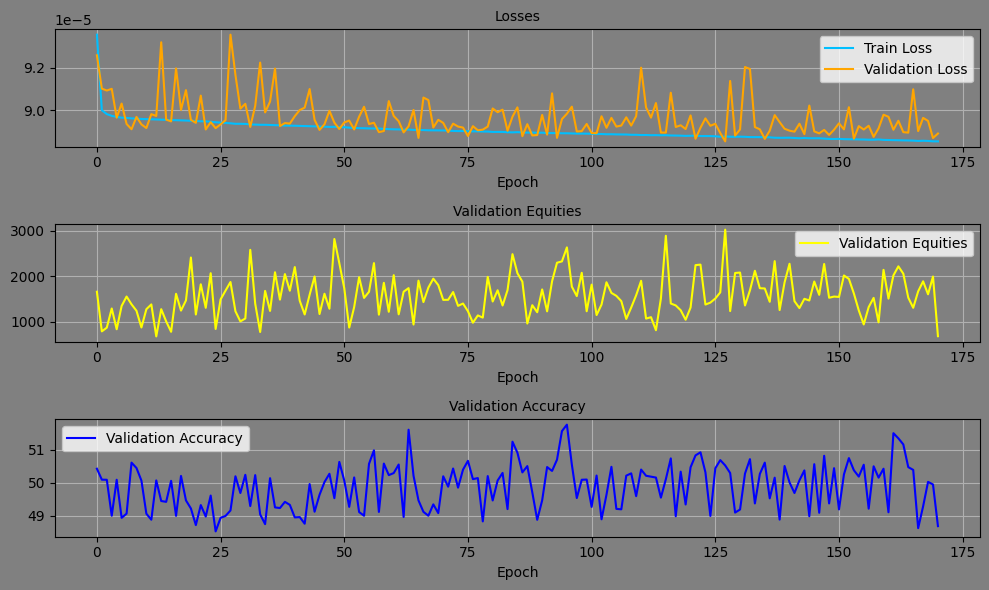

Epoch: 171, Val Equity: 1115.12, Val Accuracy: 50.19 train_losses: 0.000262735098311989, val_losses: 9.087842045119032e-05, Duration: 0:01:45.875968


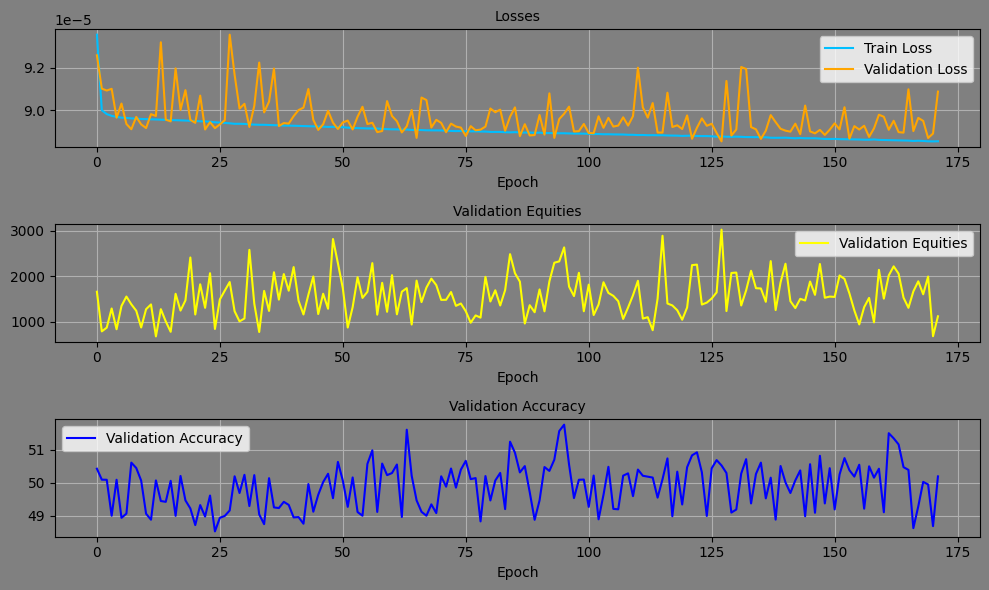

Epoch: 172, Val Equity: 1494.83, Val Accuracy: 49.06 train_losses: 0.00026261808925233355, val_losses: 9.021061850944534e-05, Duration: 0:01:45.556530


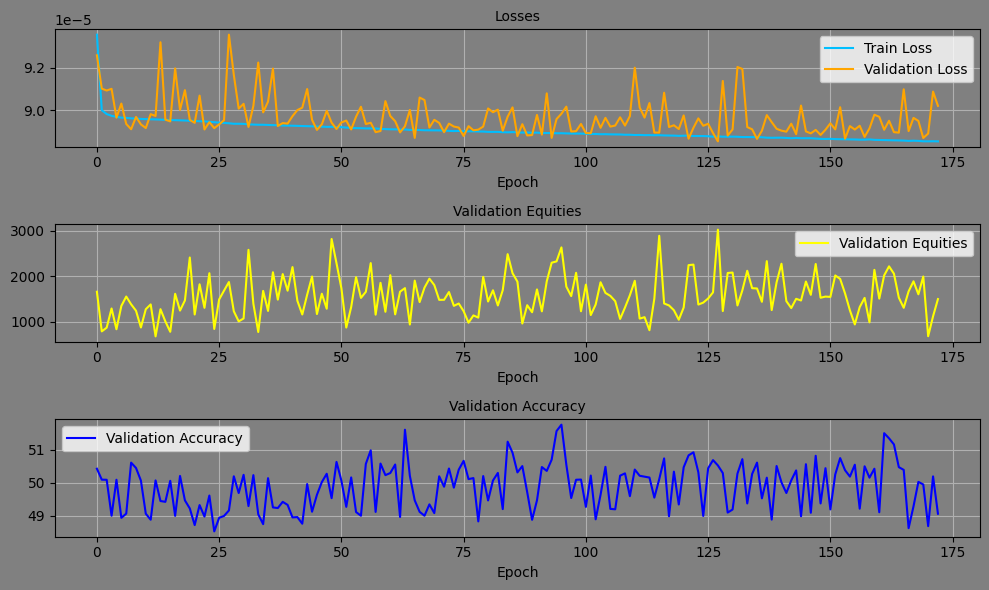

Epoch: 173, Val Equity: 1926.92, Val Accuracy: 49.68 train_losses: 0.0002624494267424817, val_losses: 8.916011574910954e-05, Duration: 0:01:45.818965


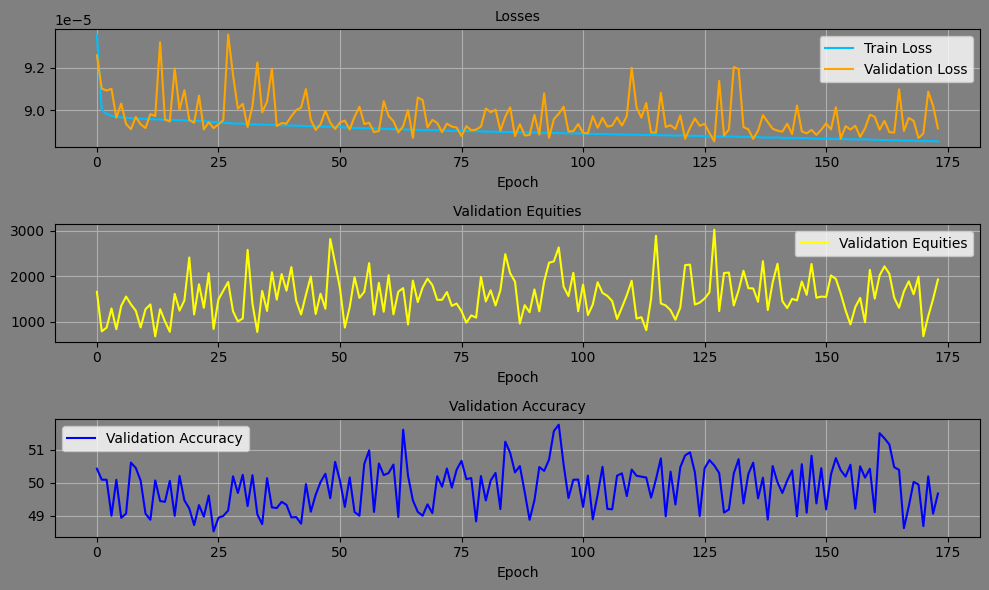

Epoch: 174, Val Equity: 2147.82, Val Accuracy: 51.04 train_losses: 0.00026219316211518535, val_losses: 8.930611511459574e-05, Duration: 0:01:45.400861


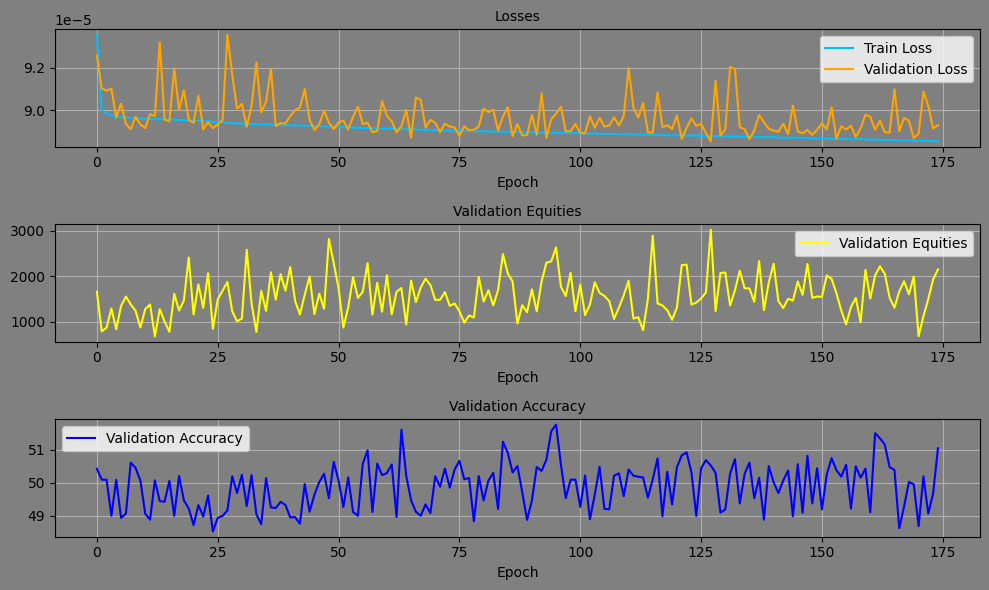

Epoch: 175, Val Equity: 1159.29, Val Accuracy: 50.24 train_losses: 0.00026243062097126136, val_losses: 8.936030644690618e-05, Duration: 0:01:45.559489


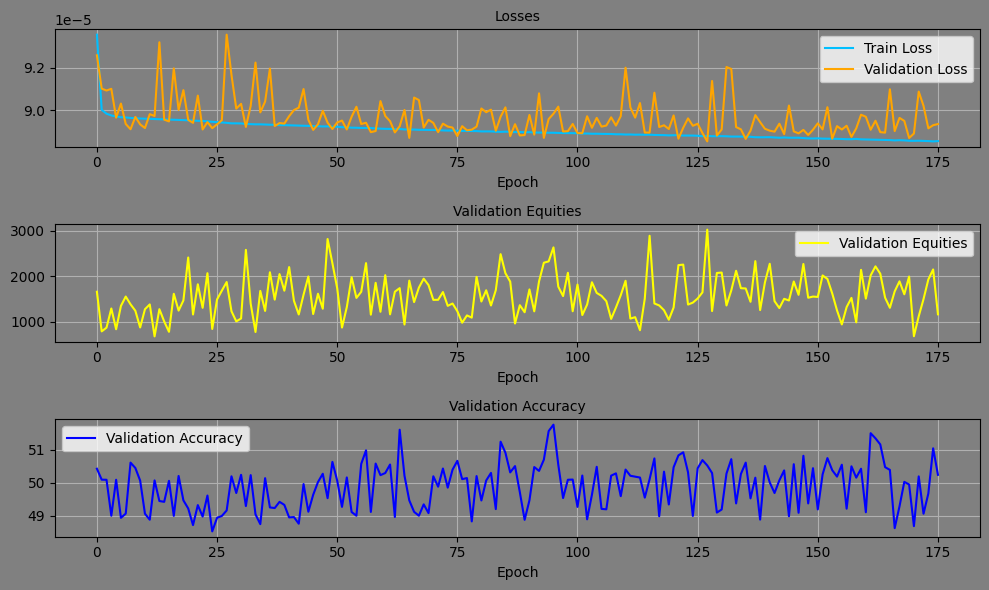

Epoch: 176, Val Equity: 2824.49, Val Accuracy: 50.82 train_losses: 0.000262216776917281, val_losses: 8.883191185304895e-05, Duration: 0:01:44.702919


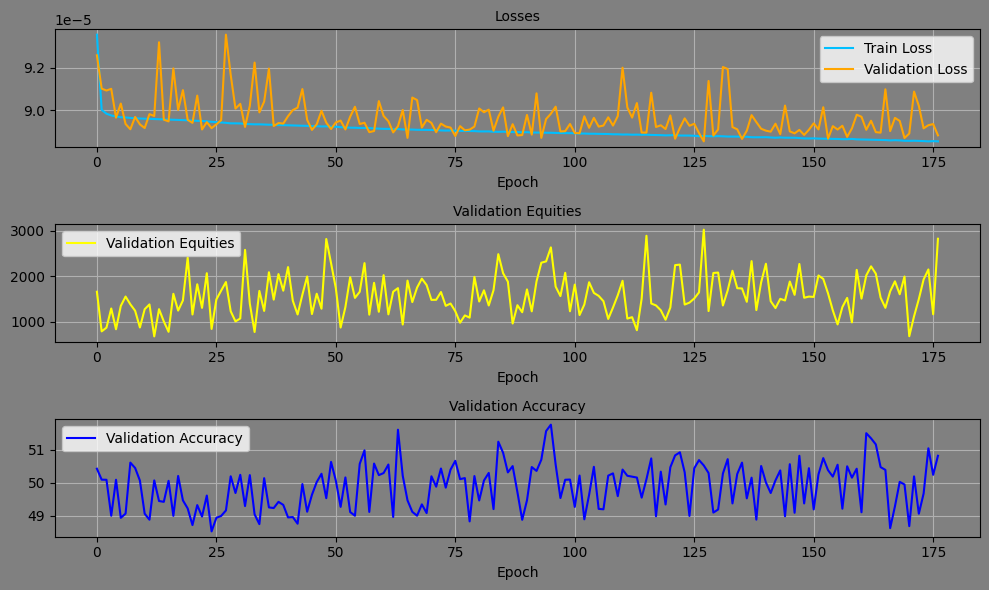

Epoch: 177, Val Equity: 2059.32, Val Accuracy: 50.15 train_losses: 0.00026194765839628097, val_losses: 8.916390652302653e-05, Duration: 0:01:49.536011


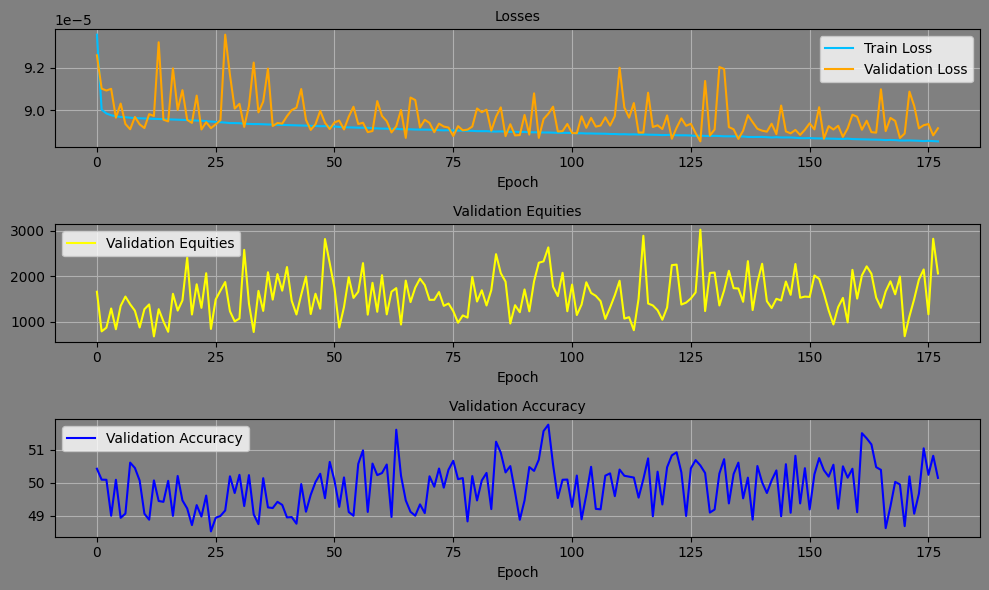

Epoch: 178, Val Equity: 1559.22, Val Accuracy: 49.06 train_losses: 0.000261999934190872, val_losses: 8.889359014574438e-05, Duration: 0:01:45.794731


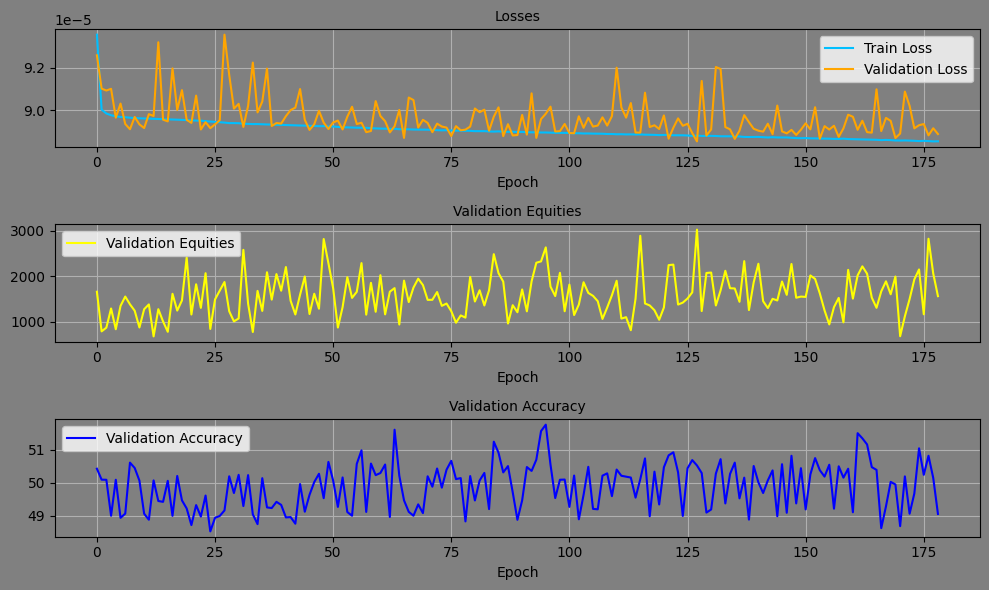

Epoch: 179, Val Equity: 1985.48, Val Accuracy: 50.33 train_losses: 0.00026183628543462395, val_losses: 8.936980157159269e-05, Duration: 0:01:45.700507


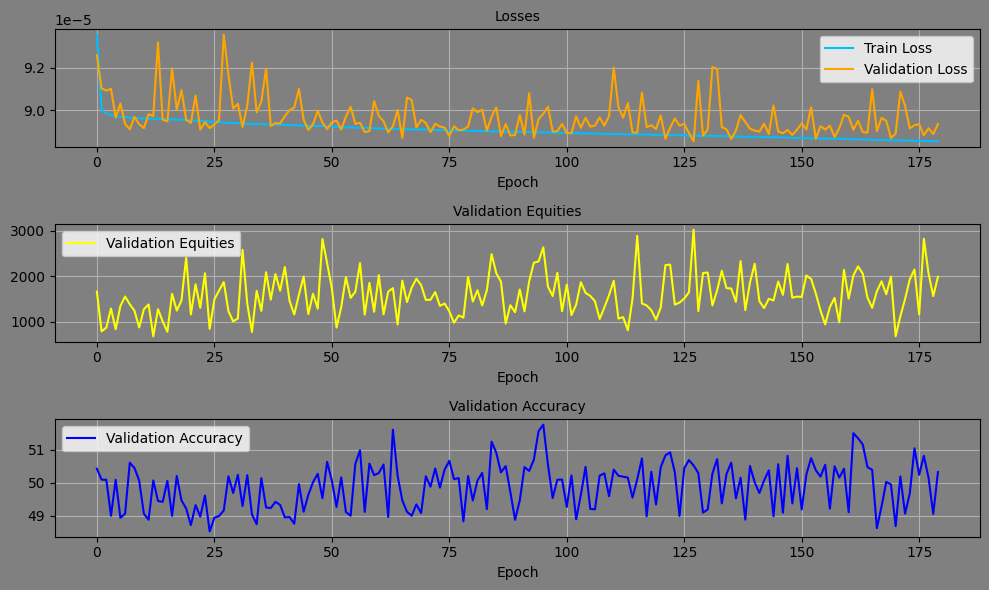

Epoch: 180, Val Equity: 965.09, Val Accuracy: 50.24 train_losses: 0.0002617349720098235, val_losses: 8.98992147995159e-05, Duration: 0:01:44.490970


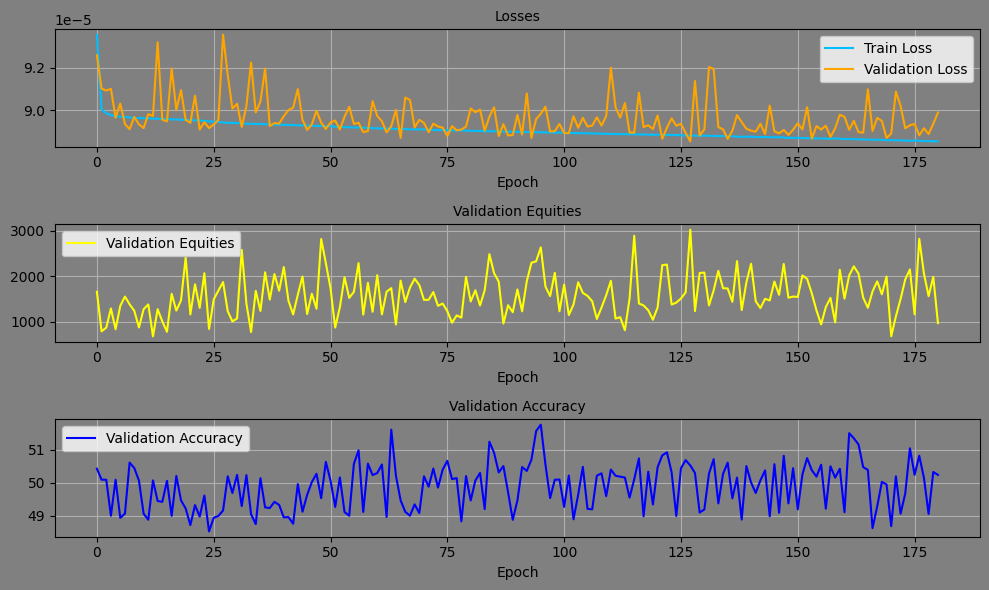

Epoch: 181, Val Equity: 1499.31, Val Accuracy: 49.28 train_losses: 0.00026168440955813815, val_losses: 9.167498501483351e-05, Duration: 0:01:44.629936


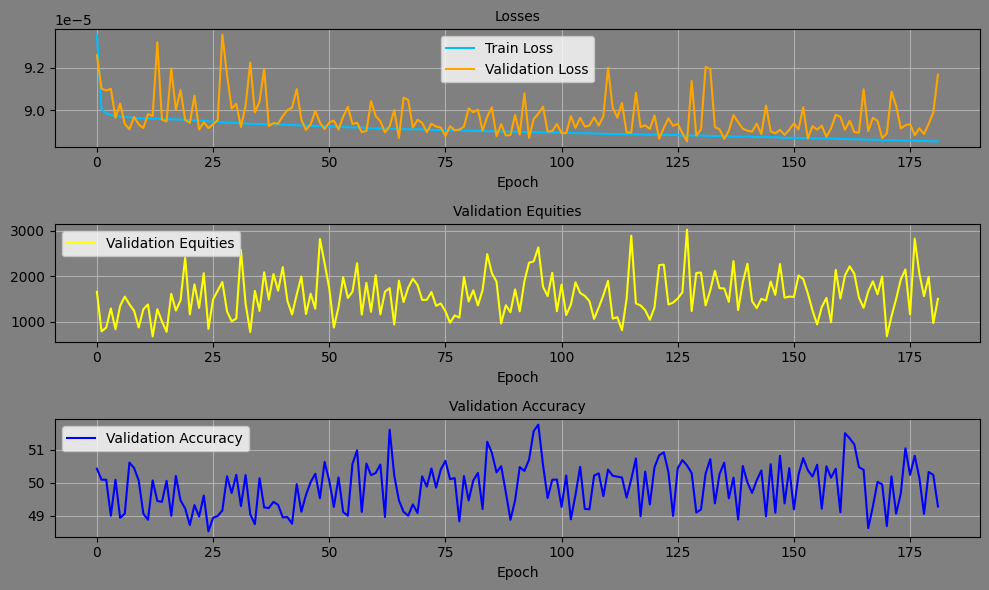

Epoch: 182, Val Equity: 2423.36, Val Accuracy: 51.55 train_losses: 0.00026132415519171674, val_losses: 8.906269795261323e-05, Duration: 0:01:44.059268


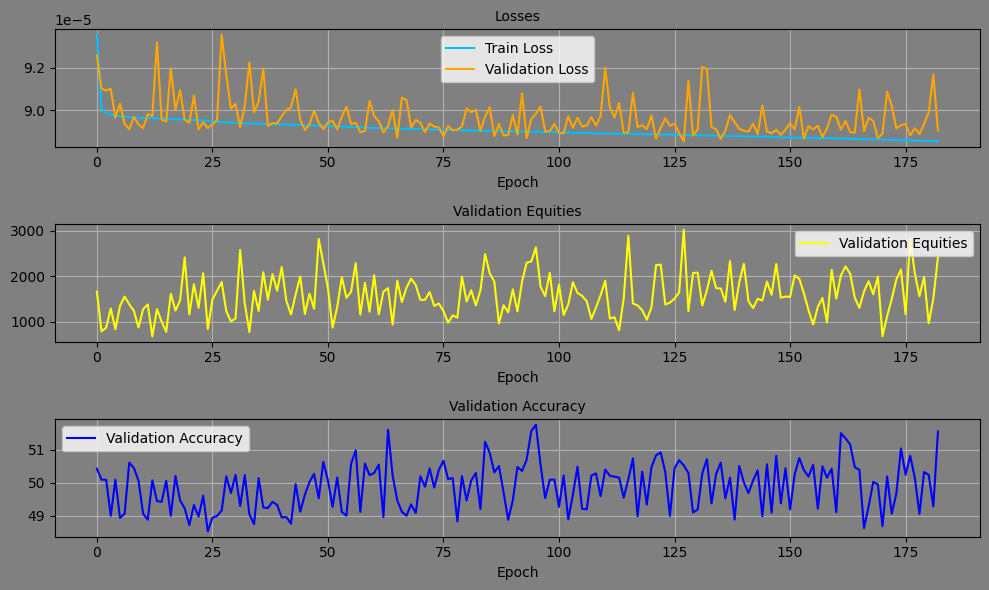

Epoch: 183, Val Equity: 1744.02, Val Accuracy: 51.25 train_losses: 0.00026144122822101485, val_losses: 8.899888052837923e-05, Duration: 0:01:44.793683


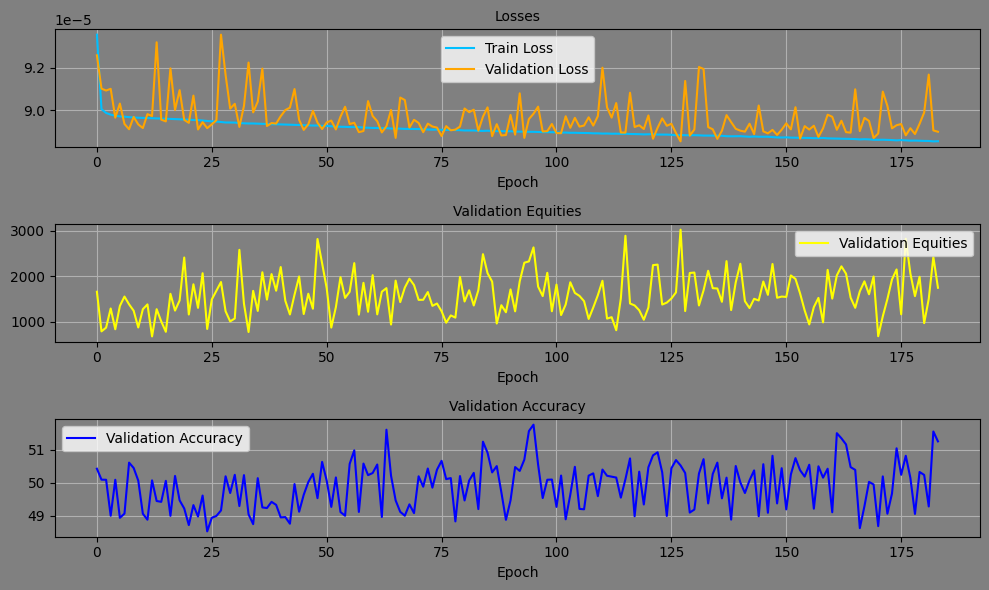

Epoch: 184, Val Equity: 2097.81, Val Accuracy: 50.87 train_losses: 0.00026109910072914946, val_losses: 8.903122215997428e-05, Duration: 0:01:47.339596


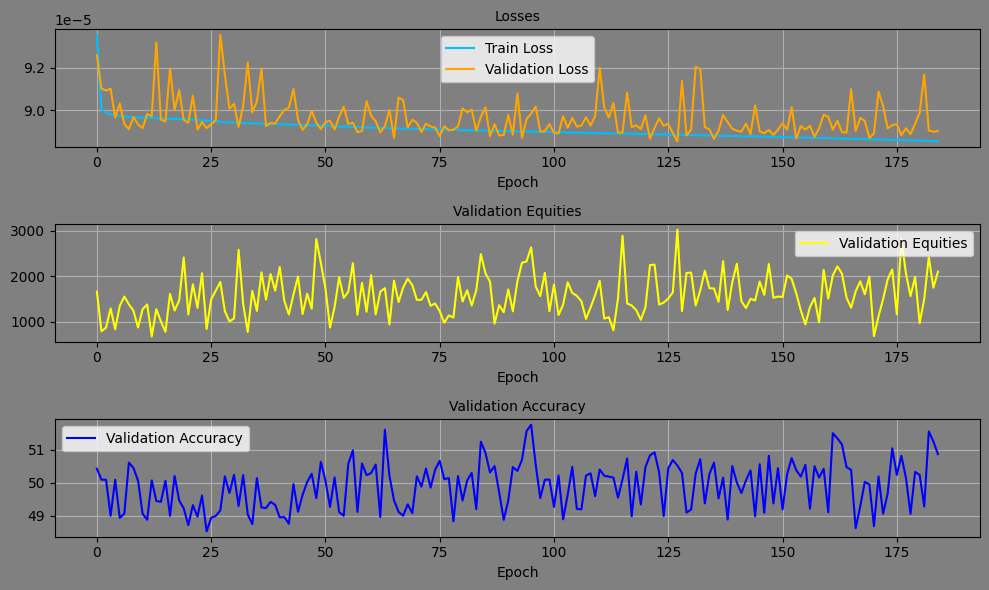

Epoch: 185, Val Equity: 1231.74, Val Accuracy: 50.24 train_losses: 0.000261074038359019, val_losses: 8.96238416316919e-05, Duration: 0:01:44.599365


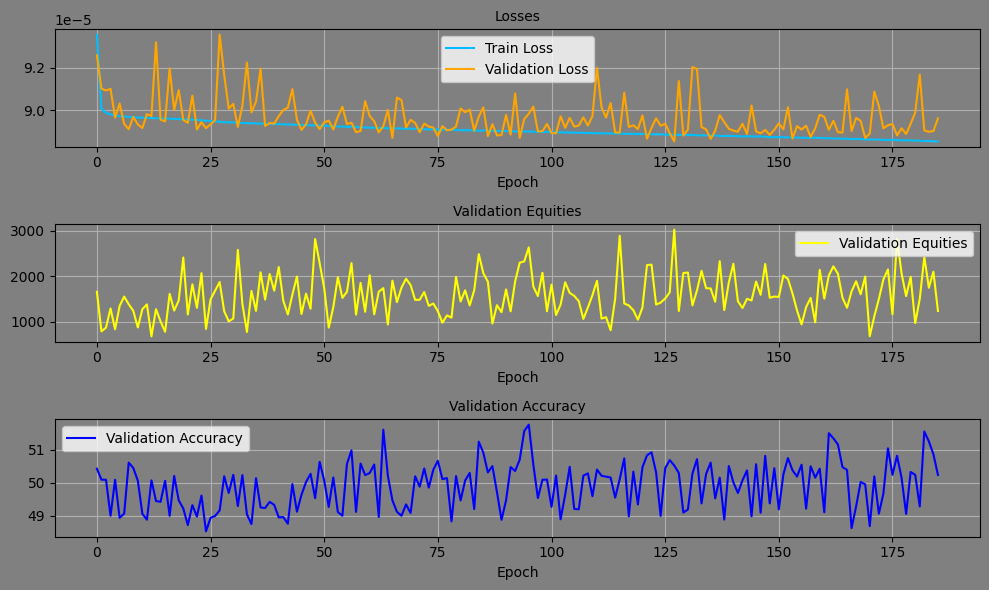

Epoch: 186, Val Equity: 2009.82, Val Accuracy: 51.33 train_losses: 0.0002608627831160832, val_losses: 8.929504110710695e-05, Duration: 0:01:45.144148


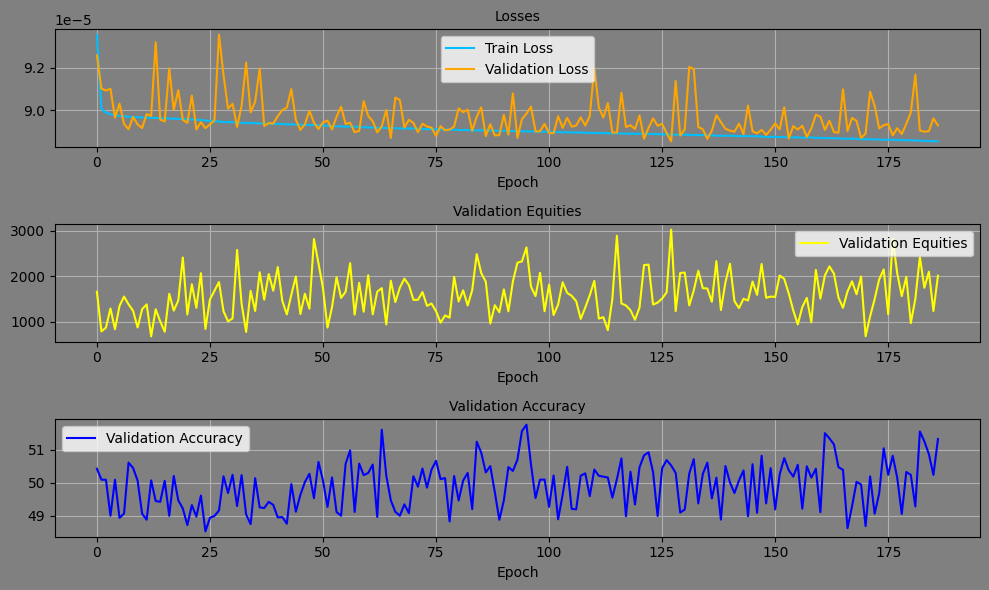

Epoch: 187, Val Equity: 1216.38, Val Accuracy: 50.22 train_losses: 0.0002607925288909827, val_losses: 8.915755461202934e-05, Duration: 0:01:46.268656


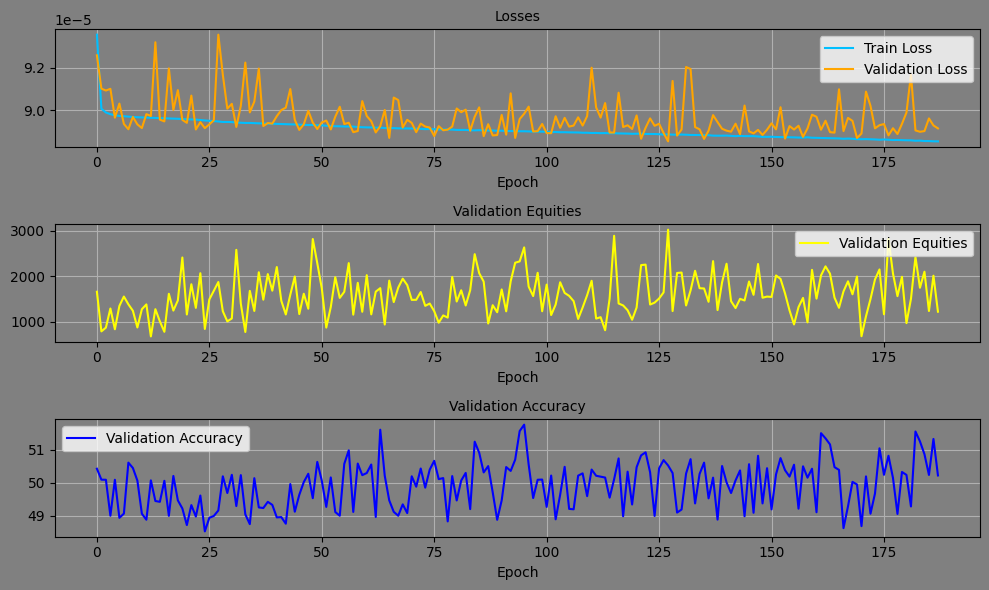

Epoch: 188, Val Equity: 1555.55, Val Accuracy: 49.67 train_losses: 0.0002608253533233112, val_losses: 8.877916116034612e-05, Duration: 0:01:44.174455


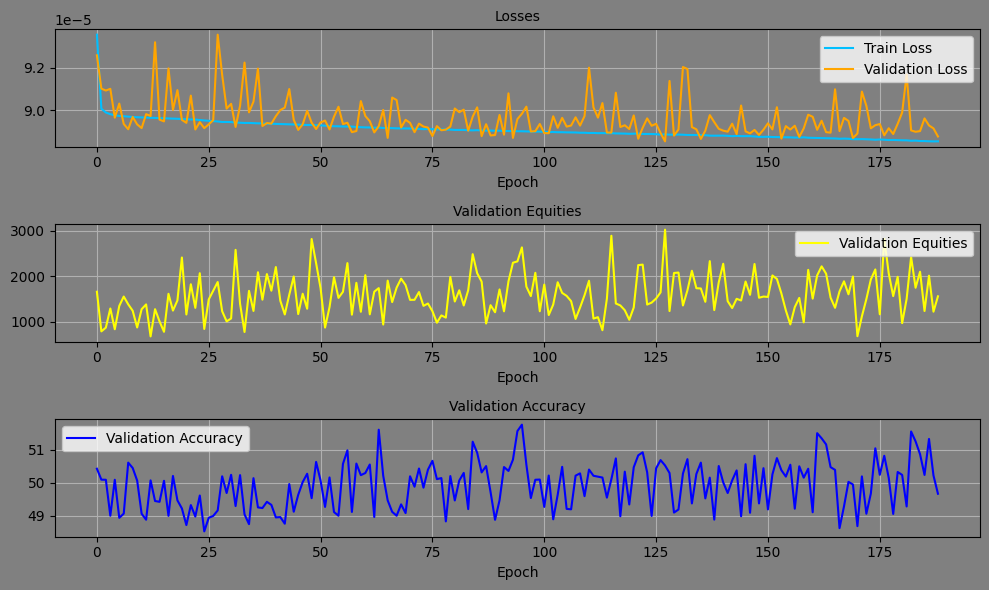

Epoch: 189, Val Equity: 1398.51, Val Accuracy: 50.36 train_losses: 0.0002605184308804826, val_losses: 8.890055323718116e-05, Duration: 0:01:44.358653


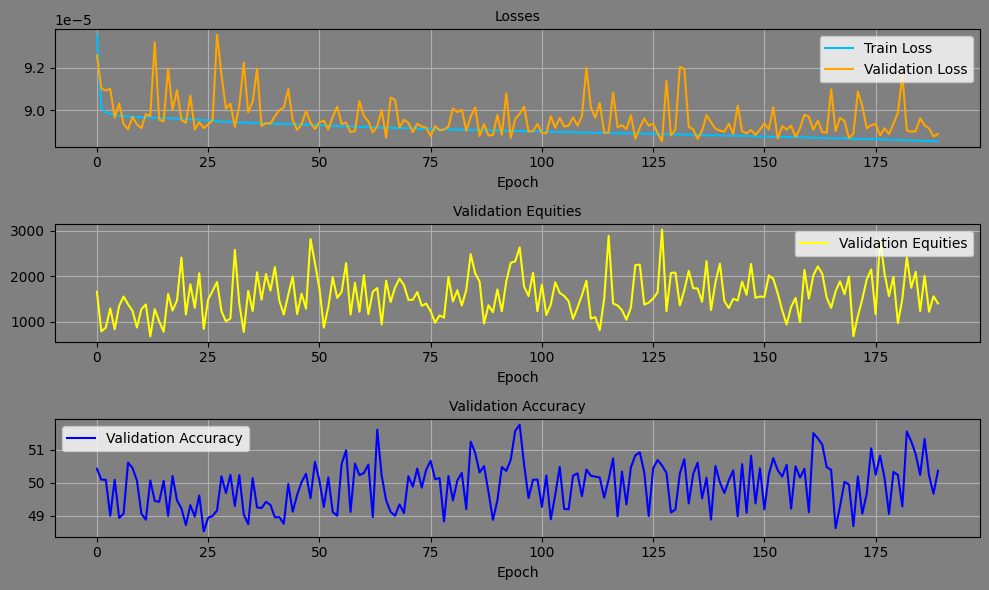

Epoch: 190, Val Equity: 1655.57, Val Accuracy: 49.83 train_losses: 0.00026035798701303333, val_losses: 8.911672921385616e-05, Duration: 0:01:43.241767


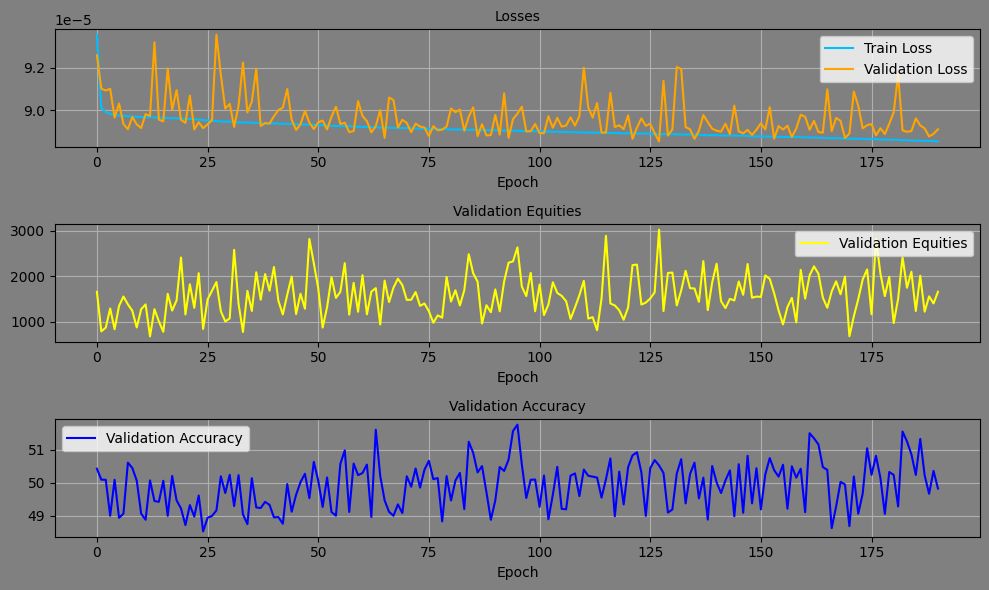

Epoch: 191, Val Equity: 867.51, Val Accuracy: 50.17 train_losses: 0.00026030464509562806, val_losses: 9.18177465791814e-05, Duration: 0:01:44.817455


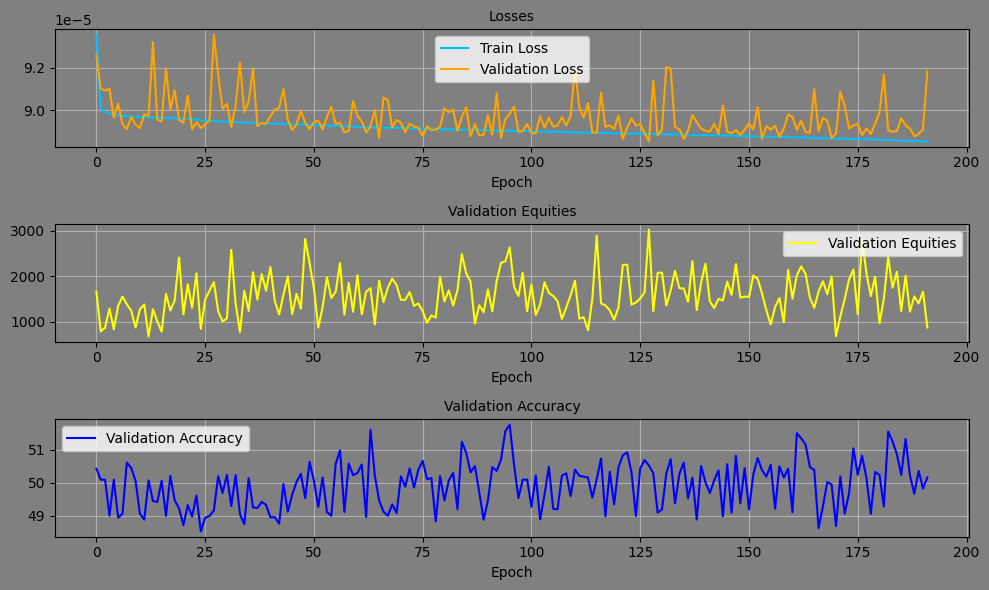

Epoch: 192, Val Equity: 1997.45, Val Accuracy: 50.63 train_losses: 0.00026039153606770407, val_losses: 8.92099051270634e-05, Duration: 0:01:46.018099


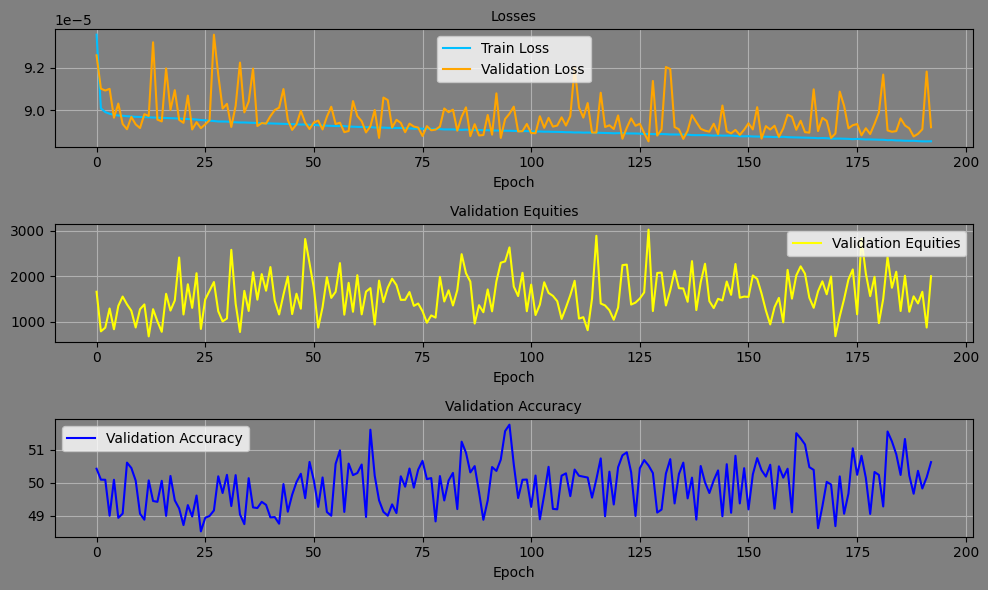

Epoch: 193, Val Equity: 2025.54, Val Accuracy: 51.02 train_losses: 0.00026017463708895533, val_losses: 9.108571975957602e-05, Duration: 0:01:44.793995


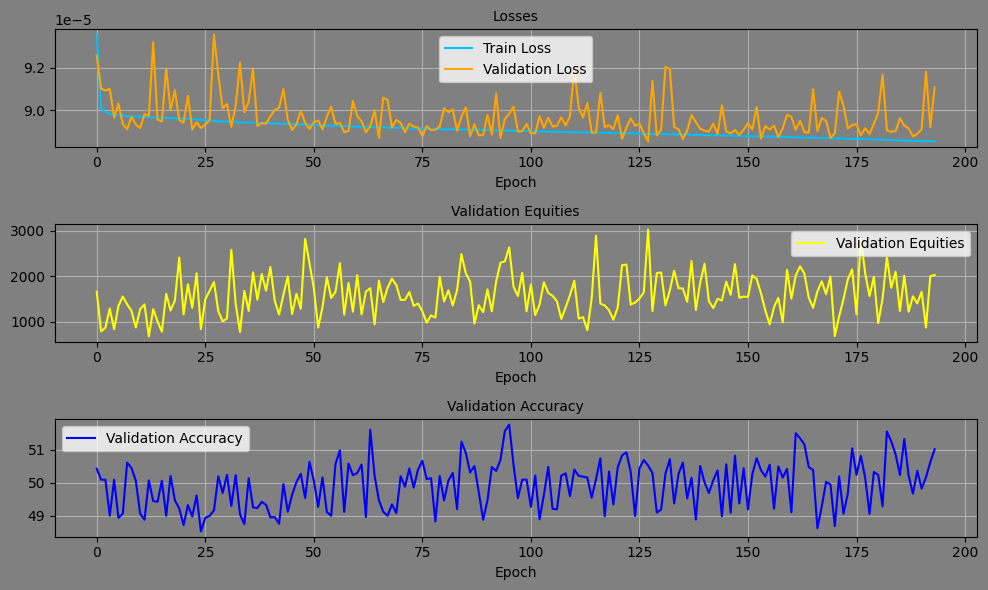

Epoch: 194, Val Equity: 1092.74, Val Accuracy: 50.18 train_losses: 0.00026010811541162524, val_losses: 8.983725274447352e-05, Duration: 0:01:45.115424


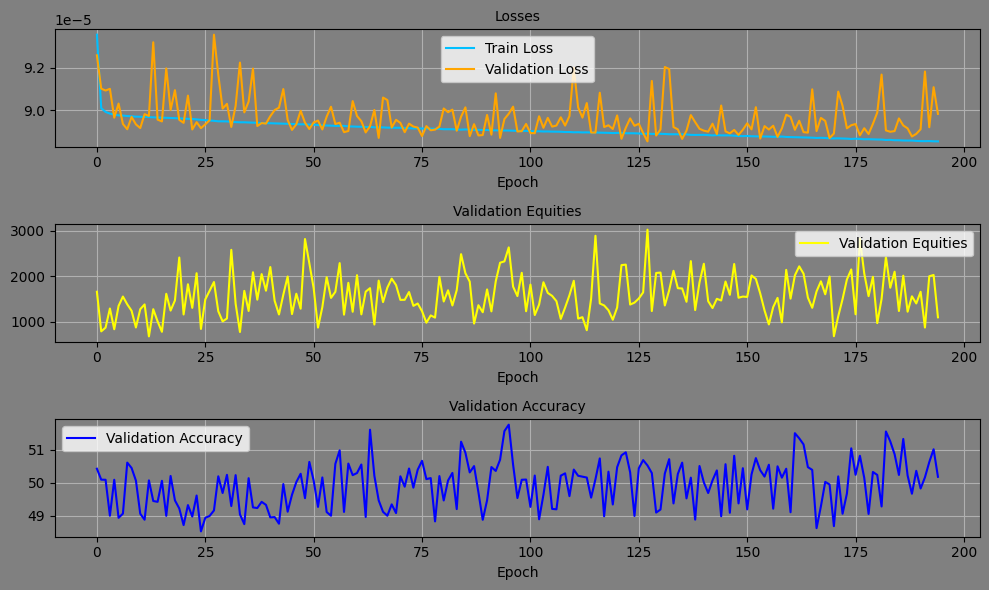

Epoch: 195, Val Equity: 1449.75, Val Accuracy: 49.06 train_losses: 0.00025992012505517647, val_losses: 8.962420542957261e-05, Duration: 0:01:45.559419


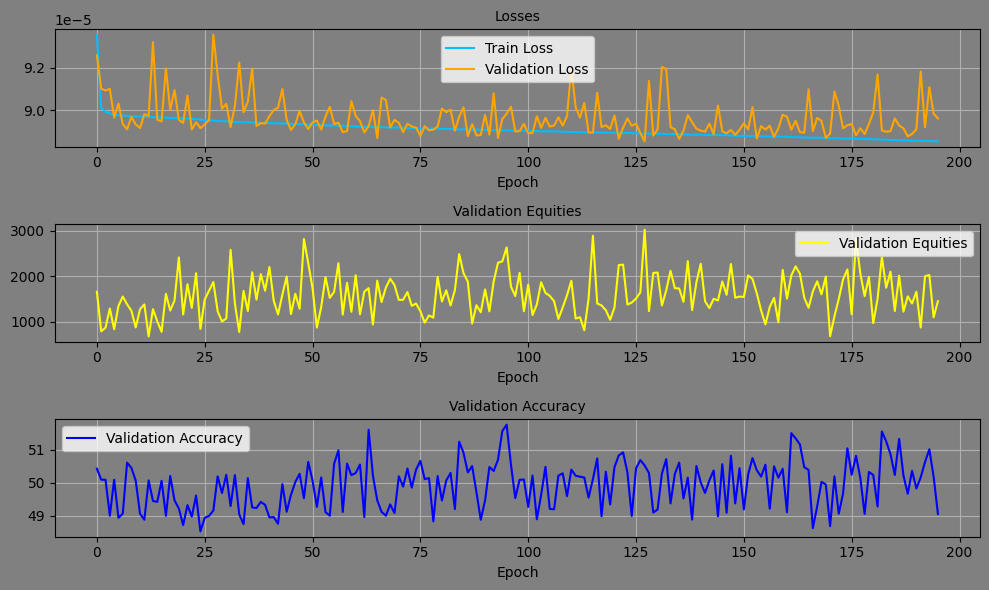

Epoch: 196, Val Equity: 1253.88, Val Accuracy: 48.97 train_losses: 0.0002596953880228972, val_losses: 8.987064938992262e-05, Duration: 0:01:45.057416


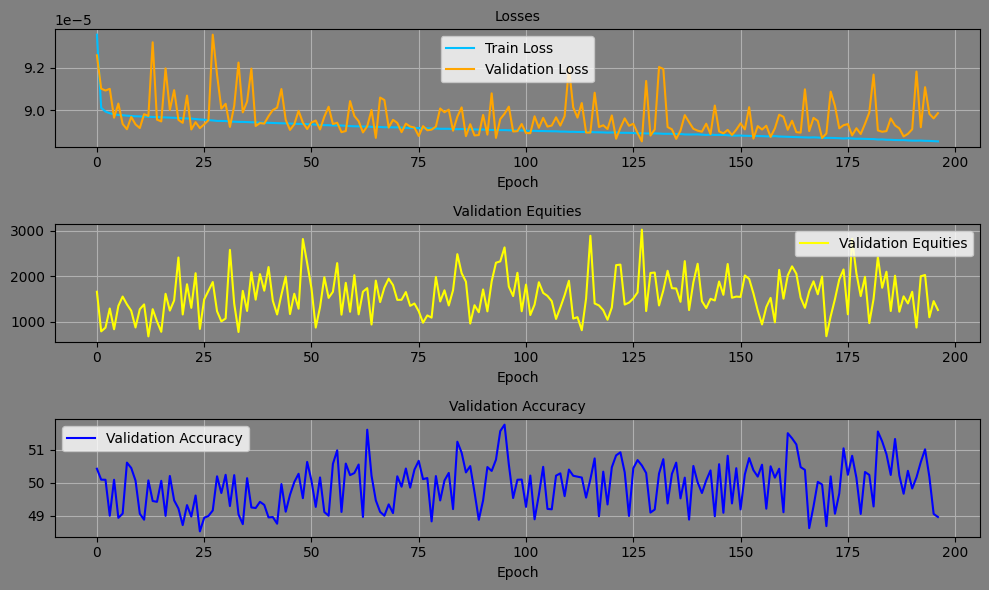

Epoch: 197, Val Equity: 2285.60, Val Accuracy: 51.48 train_losses: 0.00025962157427723403, val_losses: 8.881735993782058e-05, Duration: 0:01:44.083891


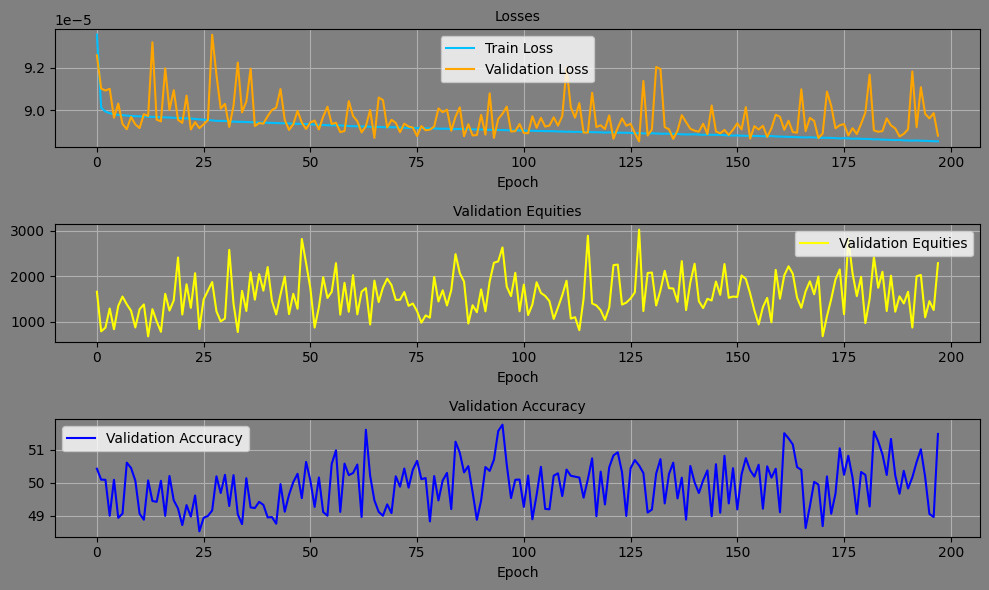

Epoch: 198, Val Equity: 1510.34, Val Accuracy: 49.11 train_losses: 0.00025966150586625406, val_losses: 8.896289364201948e-05, Duration: 0:01:43.696499


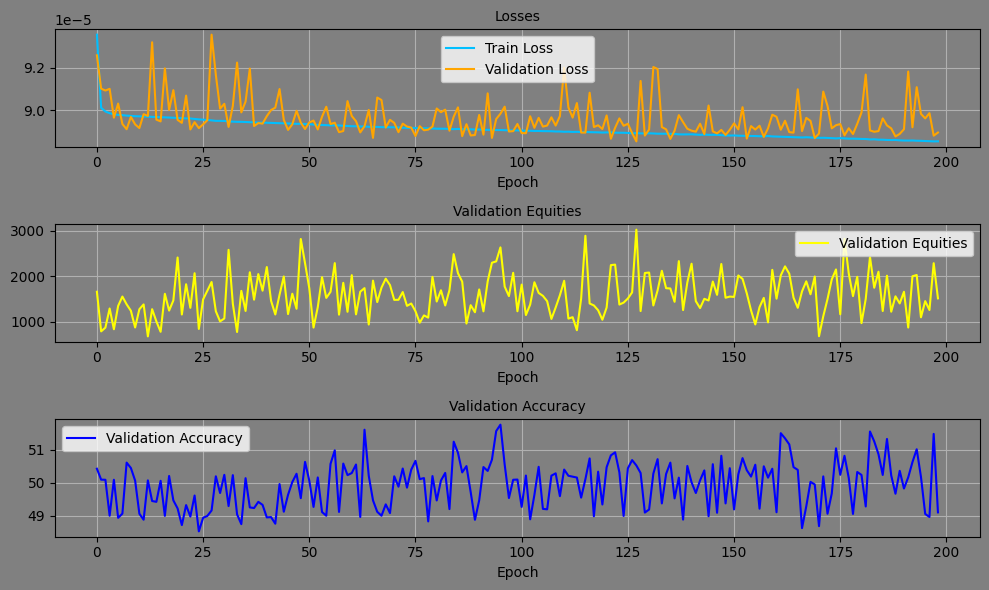

Epoch: 199, Val Equity: 2103.54, Val Accuracy: 50.39 train_losses: 0.00025929869003648047, val_losses: 8.93610340426676e-05, Duration: 0:01:43.399104


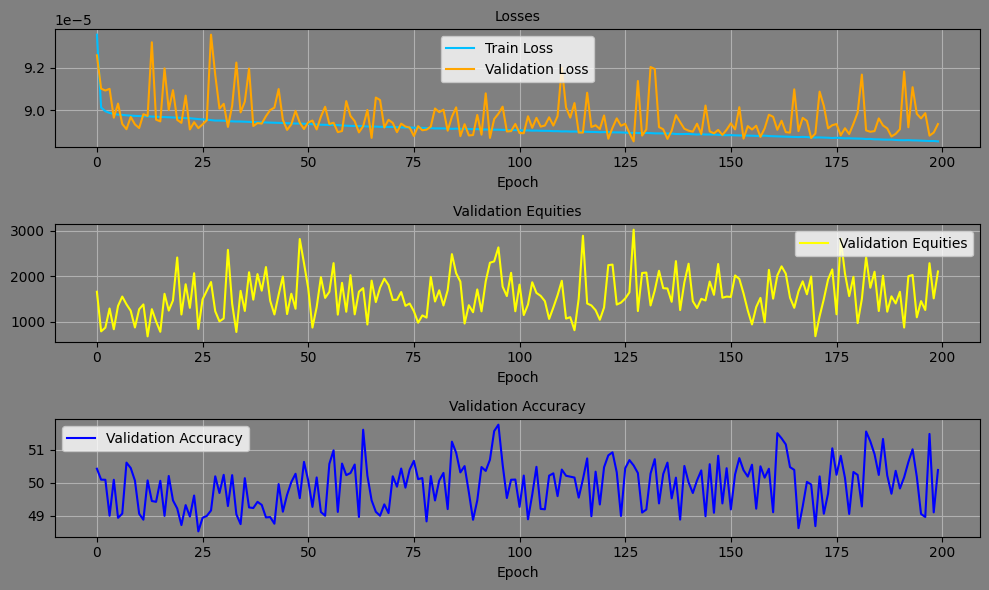

In [15]:
for epoch in range(epoch, num_epochs):

    # Track duration
    dt0_epoch = datetime.now()

    # Create mini batches
    mini_batches, seed = create_minibatches(X_train, Y_train, batch_size, seed, shuffle=True)

    train_losses_batch = []

    for X_train_batch, Y_train_batch in mini_batches:
        # Set train mode
        model.train()

        # Reset the gradients
        optimizer.zero_grad()

        # Forward propagation
        Y_hat_train = model(X_train_batch) # Shape: (batch_size, num_features)

        # Calculate loss (train)
        train_loss = criterion(Y_hat_train, Y_train_batch)

        # Backprop
        train_loss.backward()

        # Update optimizer
        optimizer.step()

        # Keep track of training losses
        train_losses_batch.append(train_loss.item())

    # Predict on validation data -- X_test is never touched here, only X_val.
    # This is the slice the loop is "allowed" to check every epoch to decide
    # when to stop / which checkpoint to keep.
    with torch.no_grad():

        # Set evaluation mode
        model.eval()

        # Forward propagation (chunks)
        chunks = 16  # set once per epoch, outside the retry loop -- previously
                     # this was reset to 16 on every retry, so the "increase
                     # chunks on OOM" logic never actually took effect
        while True:
            try:
                # split the validation set into chunks
                m = m_val // chunks

                for j in range(chunks + 1):
                    Y_pred_val[m*j:m*j+m] = model(X_val[m*j:m*j+m])  # Forward prop

                break

            except Exception as err:
                print(f"Chunks = {chunks} is too large: {err}")
                chunks += 2

        # Calculate validation loss
        val_loss = criterion(Y_pred_val, Y_val)

    # Convert 'Y_pred_val' to numpy
    Y_pred_val_cpu = Y_pred_val.detach().cpu().numpy()

    train_losses.append(np.mean(train_losses_batch))
    val_losses.append(val_loss.item())

    # ===================== Backtest (validation only) =====================
    equities = []    # Store equity (account value) over time
    pos_size = 1000  # Fixed position size ($1000 per trade)
    equity = 1000    # Starting capital
    correct_pred = 0 # Initialize correct prediction

    actions = Y_pred_val_cpu[:, 0] > 0 # Get model's buy/sell predictions

    for i in range(len(X_val)-1):
        curr_open = backtest_opens_val[i]   # the price we enter at.
        curr_close = backtest_closes_val[i] # the price we exit at.
        curr_action = actions[i]        # the model's signal (buy or sell).

        # Calculate percentage price change
        pct_change = (curr_close - curr_open) / curr_open

        # Profit or loss in dollars
        pnl = np.abs(pos_size * pct_change)

        # Update equity depending on action and price move
        if curr_action == 1:     # Long position (Buy side)
            if pct_change > 0:
                equity += pnl    # Price up -> profit
                correct_pred += 1
            elif pct_change < 0:
                equity -= pnl    # Price down -> loss

        elif curr_action == 0:   # Short position
            if pct_change > 0:
                equity -= pnl    # Price up -> loss
            elif pct_change < 0:
                equity += pnl    # Price down -> profit
                correct_pred += 1

        equities.append(equity) # Save current equity
    # ========================================================

    # Calculate percentage accuracy
    accuracy = correct_pred / len(X_val) * 100

    # Save final equity for each epoch
    val_equity_epochs.append(equity)
    val_accuracy_epochs.append(accuracy)

    print(f'Epoch: {epoch}, Val Equity: {equity:.2f}, Val Accuracy: {accuracy:.2f} train_losses: {train_losses[-1]}, val_losses: {val_losses[-1]}, Duration: {datetime.now() - dt0_epoch}')

    # Save training process
    torch.save({
        'epoch': epoch,
        'model_state_dict': model.state_dict(),
        'optimizer_state_dict': optimizer.state_dict(),
        'train_losses': train_losses,
        'val_losses': val_losses,
        'val_equity_epochs': val_equity_epochs,
        'val_accuracy_epochs': val_accuracy_epochs,
        'best_val_equity': best_val_equity,
        'seed': seed,
    }, 'training_process')

    # Manual-inspection checkpoints, same threshold convention as before, but
    # now scored on validation equity, not test equity.
    if equity > 3000:
        torch.save(model.state_dict(), f"models/valeq_{equity:.0f}_ep_{epoch}.pt")

    # The single best checkpoint by validation equity across every epoch run
    # so far -- this is the one file the final held-out test cell loads.
    if equity > best_val_equity:
        best_val_equity = equity
        torch.save(model.state_dict(), "models/best_by_validation.pt")

    # Plot training process
    fig, axs = plt.subplots(nrows=3, ncols=1, figsize=(10, 6))
    scaler_valloss = MinMaxScaler(feature_range=(np.min(val_losses)-0.0000000001, np.max(val_losses)))

    # Plot Train Loss and Validation Loss
    axs[0].set_title(f"Losses", fontsize=10)
    axs[0].plot(scaler_valloss.fit_transform(np.array(train_losses).reshape(-1,1)), label='Train Loss', color='deepskyblue')
    axs[0].plot(val_losses, label='Validation Loss', color='orange')
    axs[0].set_xlabel("Epoch")
    axs[0].legend()
    axs[0].grid()
    # Plot Equities
    axs[1].set_title(f"Validation Equities", fontsize=10)
    axs[1].plot(val_equity_epochs, label='Validation Equities', color='yellow')
    axs[1].set_xlabel("Epoch")
    axs[1].legend()
    axs[1].grid()
    # Plot Accuracy
    axs[2].set_title(f"Validation Accuracy", fontsize=10)
    axs[2].plot(val_accuracy_epochs, label='Validation Accuracy', color='blue')
    axs[2].set_xlabel("Epoch")
    axs[2].legend()
    axs[2].grid()
    # Set background color and paper color
    fig.patch.set_facecolor(mcolors.to_hex('grey'))  # Set paper color
    for ax in axs.flat:
        ax.set_facecolor(mcolors.to_hex('grey'))  # Set bg color
    # Display
    plt.tight_layout()
    plt.savefig(f'training_process.png')
    plt.show()
    plt.close()

**Final held-out test evaluation (run exactly once, after training is done)**

/var/folders/4f/6p47vdgn5_3dwdmxhs9cypqm0000gn/T/ipykernel_36205/1620699859.py:10: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  test_model.load_state_dict(torch.load("model

HELD-OUT TEST (checked exactly once): final equity=1076.24, accuracy=48.17%


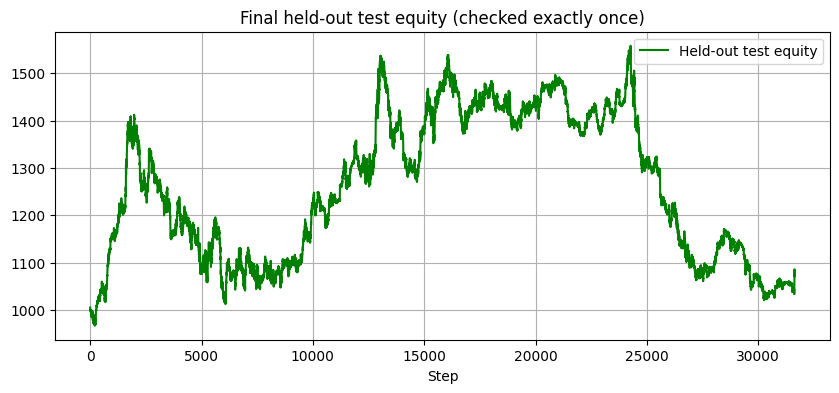

In [16]:
# ===================== FINAL, ONE-TIME TEST EVALUATION =====================
# The only cell in this notebook that touches X_test/Y_test. Runs exactly
# once, after training is completely finished, using
# models/best_by_validation.pt -- the single checkpoint that scored best on
# the VALIDATION set across every epoch. No decision anywhere above this
# cell was made by looking at test-set performance, so this is the first
# honest out-of-sample number in this project.

test_model = Model()
test_model.load_state_dict(torch.load("models/best_by_validation.pt", map_location=device))
test_model.to(device)
test_model.eval()

with torch.no_grad():
    chunks = 16
    m_chunk = m_test // chunks
    Y_pred_test = torch.zeros([m_test, num_features], dtype=torch.float32)
    while True:
        try:
            for j in range(chunks + 1):
                Y_pred_test[m_chunk*j:m_chunk*j+m_chunk] = test_model(
                    X_test[m_chunk*j:m_chunk*j+m_chunk].to(device)
                ).cpu()
            break
        except Exception as err:
            print(f"Chunks = {chunks} is too large: {err}")
            chunks += 2
            m_chunk = m_test // chunks

Y_pred_test_cpu = Y_pred_test.detach().numpy()

pos_size = 1000
equity = 1000
correct_pred = 0
test_equities = []

actions = Y_pred_test_cpu[:, 0] > 0

for i in range(len(X_test) - 1):
    curr_open = backtest_opens_test[i]
    curr_close = backtest_closes_test[i]
    curr_action = actions[i]

    pct_change = (curr_close - curr_open) / curr_open
    pnl = np.abs(pos_size * pct_change)

    if curr_action == 1:
        if pct_change > 0:
            equity += pnl
            correct_pred += 1
        elif pct_change < 0:
            equity -= pnl
    elif curr_action == 0:
        if pct_change > 0:
            equity -= pnl
        elif pct_change < 0:
            equity += pnl
            correct_pred += 1

    test_equities.append(equity)

test_accuracy = correct_pred / len(X_test) * 100
print(f"HELD-OUT TEST (checked exactly once): final equity={equity:.2f}, accuracy={test_accuracy:.2f}%")

plt.figure(figsize=(10, 4))
plt.plot(test_equities, label="Held-out test equity", color="green")
plt.title("Final held-out test equity (checked exactly once)")
plt.xlabel("Step")
plt.legend()
plt.grid()
plt.savefig("test_equity_final.png")
plt.show()